<img src=https://audiovisuales.icesi.edu.co/assets/custom/images/ICESI_logo_prin_descriptor_RGB_POSITIVO_0924.jpg width=200>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/juanestebancg2806/ml3-time-series-forecasting/blob/main/taller2/taller2_pronostico_ocupados.ipynb)

# Pronóstico del número de ocupados en las 13 principales ciudades de Colombia: partición fija frente a evaluación con origen móvil

**Aprendizaje Automático III — Universidad Icesi**

**Integrantes:** Juan Esteban Cardona, Daniel Velasco

Este notebook continúa el pronóstico del número mensual de ocupados, en miles de personas, de las 13 principales ciudades de Colombia, con el objetivo de pronosticar los próximos 6 meses. En el taller anterior se compararon promedios móviles, suavización exponencial y regresión lineal, y el mejor modelo fue la combinación de un Holt-Winters aditivo sin tendencia y una regresión con tendencia lineal y dummies de mes estimada con los últimos 24 meses. Aquí se agregan los modelos ARIMA y se comparan todas las familias con dos estrategias de evaluación.

En la **Parte 1** se conserva la partición fija del taller anterior: los modelos se ajustan con el entrenamiento, de enero de 2001 a diciembre de 2018, y se comparan en la muestra de prueba, de enero a junio de 2019. Los modelos ARIMA se eligen con un procedimiento automático (`auto_arima`) y con optimización bayesiana, y el mejor modelo ARIMA se somete a la revisión de los supuestos de sus residuales. En la **Parte 2** se reemplaza la partición fija por una evaluación con origen móvil: el origen del pronóstico avanza mes a mes, y en cada origen todos los modelos se vuelven a ajustar solo con la información disponible hasta ese momento y pronostican los 6 meses siguientes. Comparar las dos partes permite ver cuánto depende la elección del modelo de la forma de evaluarlo.

Los hiperparámetros de la suavización exponencial y de los modelos ARIMA se eligen con optimización bayesiana mediante la librería Optuna. En lugar de evaluar todas las combinaciones posibles, Optuna usa los resultados de los intentos anteriores para decidir qué combinación probar a continuación, lo que permite explorar espacios con hiperparámetros continuos, como los parámetros de suavización, o con demasiadas combinaciones para recorrerlas todas. Los de la regresión y el promedio móvil, que son todos discretos y se ajustan casi sin costo, se eligen con una búsqueda en grilla que evalúa todas sus combinaciones.

### Contenido

**Preparación común**

1. **Carga de paquetes:** librerías y versiones del entorno.
2. **Carga, exploración y partición de los datos:** periodo, comportamiento general, muestra de prueba y rasgos de la serie que orientan los modelos.
3. **Esquema de validación y funciones comunes:** validación dentro del entrenamiento, caché de evaluaciones y funciones de evaluación y de optimización compartidas por todas las familias.

**Parte 1 — Evaluación con partición fija**

4. **Modelos del taller anterior:** los modelos de promedios móviles, suavización exponencial y regresión, recalculados con la misma partición.
5. **Búsqueda de hiperparámetros de las familias del taller anterior:** suavización exponencial con optimización bayesiana, y regresión y promedio móvil con búsqueda en grilla completa, usando solo el entrenamiento.
6. **Identificación de los modelos ARIMA:** estacionariedad, orden de diferenciación y autocorrelaciones de la serie.
7. **ARIMA y SARIMA:** selección automática con `auto_arima` y optimización bayesiana de los órdenes.
8. **Supuestos del mejor modelo ARIMA:** elección del modelo de la familia con la revisión de sus residuales y diagnóstico del modelo ajustado con todos los datos.
9. **Comparación en la muestra de prueba y elección del modelo.**
10. **Pronóstico de la Parte 1:** julio a diciembre de 2019 con el modelo elegido.

**Parte 2 — Evaluación con origen móvil mensual**

11. **Protocolo de evaluación:** tamaño inicial del entrenamiento, tipo de ventana, frecuencia de actualización y periodo de evaluación.
12. **Reoptimización anual de los hiperparámetros:** hiperparámetros elegidos cada año solo con la información disponible hasta ese momento.
13. **Evaluación de todos los modelos con origen móvil.**
14. **Error por horizonte y por periodo:** desempeño de cada modelo a 1, 2, ..., 6 meses y antes y después del cambio de la serie en 2016.
15. **Elección del modelo y pronóstico final:** julio a diciembre de 2019 con intervalos de predicción.

**Cierre**

16. **Comparación de las dos partes, conclusiones y limitaciones.**

## 1. Carga de paquetes

El notebook se desarrolló con Python 3.13 y las versiones de las librerías que se instalan en la celda siguiente. En un entorno que ya las tenga no hace falta instalarlas; en Google Colab, la celda de instalación se descomenta y se reinicia la sesión antes de continuar.

Además de las librerías del taller anterior, se usan Optuna para la optimización bayesiana y pmdarima para la selección automática de modelos ARIMA por criterios de información. Después de cargar los paquetes se imprimen las versiones del entorno. Los modelos de suavización exponencial y ARIMA se estiman con optimizadores numéricos, por lo que sus resultados pueden variar levemente entre sistemas operativos o procesadores, aun con las mismas versiones. La optimización bayesiana, en cambio, usa una semilla fija, de modo que la secuencia de intentos se repite en cada ejecución.

In [1]:
# Instalación de las librerías con las versiones usadas en este notebook.
# Solo es necesaria en Google Colab o en un entorno que no las tenga instaladas:
# quitar el comentario de la línea %pip y, en Colab, reiniciar la sesión después
# de instalar (Entorno de ejecución > Reiniciar sesión) para que se carguen las
# versiones nuevas. Requiere Python 3.12 o superior.

# %pip install pandas==3.1.1 numpy==2.5.4 matplotlib==3.11.2 statsmodels==0.15.0 scikit-learn==1.9.1 scipy==1.18.1 openpyxl==3.1.5 optuna==5.1.0 pmdarima==2.1.1

In [2]:
import hashlib
import json
import os
import warnings
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
from joblib import Parallel, delayed                               # caché en disco y ajustes en paralelo
from matplotlib import pyplot as plt

# Validación y métricas
from sklearn.model_selection import TimeSeriesSplit                # validación con origen móvil
from sklearn.metrics import mean_squared_error, mean_absolute_percentage_error

# Descripción de la serie e identificación de modelos ARIMA
from statsmodels.tsa.seasonal import seasonal_decompose            # descomposición (solo para describir la serie)
from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf    # raíz unitaria, estacionariedad, ACF y PACF
from statsmodels.tools.sm_exceptions import InterpolationWarning   # aviso de KPSS fuera de su tabla de p-valores
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf      # gráficas de la ACF y la PACF
from pmdarima.arima import ndiffs, nsdiffs                          # órdenes de diferenciación sugeridos

# Modelos
from statsmodels.tsa.exponential_smoothing.ets import ETSModel     # suavización exponencial (SES, Holt, Holt-Winters)
from statsmodels.tsa.statespace.sarimax import SARIMAX             # ARIMA y SARIMA
import statsmodels.api as sm                                       # regresión lineal por MCO y gráfico Q-Q
from pmdarima import auto_arima                                    # selección de ARIMA por criterios de información

# Optimización bayesiana de hiperparámetros
import optuna

# Supuestos de los residuales
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch  # autocorrelación y efectos ARCH
from statsmodels.sandbox.stats.runs import runstest_1samp          # prueba de rachas
from scipy import stats                                            # Jarque-Bera, Shapiro-Wilk, normal y t de Student

# Optuna solo muestra advertencias y errores, no un mensaje por cada intento
optuna.logging.set_verbosity(optuna.logging.WARNING)

In [3]:
# Versiones del entorno de ejecución, para poder reproducir los resultados
import platform
import sys

import matplotlib
import openpyxl
import pmdarima
import scipy
import sklearn
import statsmodels

print(f"{'Python':<14}{sys.version.split()[0]}")
print(f"{'Plataforma':<14}{platform.platform()}")
for nombre_libreria, modulo in [
    ("pandas", pd),
    ("numpy", np),
    ("matplotlib", matplotlib),
    ("statsmodels", statsmodels),
    ("scikit-learn", sklearn),
    ("scipy", scipy),
    ("openpyxl", openpyxl),
    ("optuna", optuna),
    ("pmdarima", pmdarima),
]:
    print(f"{nombre_libreria:<14}{modulo.__version__}")

Python        3.13.9
Plataforma    macOS-27.0.1-arm64-arm-64bit-Mach-O
pandas        3.1.1
numpy         2.5.4
matplotlib    3.11.2
statsmodels   0.15.0
scikit-learn  1.9.1
scipy         1.18.1
openpyxl      3.1.5
optuna        5.1.0
pmdarima      2.1.1


## 2. Carga, exploración y partición de los datos

Los datos provienen del archivo `datosEmpleo.xlsx`, que contiene series mensuales del mercado laboral de las 13 principales ciudades de Colombia. Se usa la columna `Ocupados`, que corresponde al número de ocupados en miles de personas, la misma serie del taller anterior. Primero se revisa el periodo cubierto, si hay valores faltantes y el comportamiento general de la serie. Después se separa la muestra de prueba de la Parte 1 y, solo con el entrenamiento, se miden los rasgos que orientan la configuración de los modelos: el cambio de la tendencia en los últimos años y la forma y el tamaño del patrón estacional.

Observaciones: 222
Periodo: 2001-01 a 2019-06
Valores faltantes: 0
count      222.0
mean      9160.9
std       1295.5
min       6923.6
25%       7971.1
50%       9139.1
75%      10458.5
max      11037.2
Name: Ocupados, dtype: float64


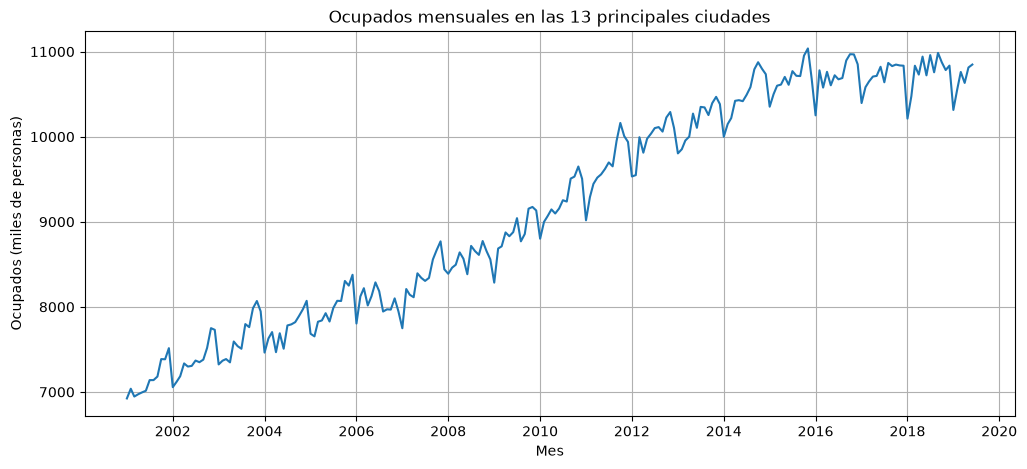

In [4]:
# Carga de datos: la columna "mes" se usa como índice de fechas
data = pd.read_excel(
    "https://raw.githubusercontent.com/dagudelo30/Aprendizaje-automatico-III/main/Clase_1/datosEmpleo.xlsx",
    index_col="mes",
    parse_dates=True,
)

# Serie de ocupados (miles de personas).
# asfreq("MS") declara la frecuencia mensual (inicio de mes): si faltara algún mes,
# aparecería como valor faltante, y además evita la advertencia de frecuencia de statsmodels.
ocupados = data["Ocupados"].asfreq("MS")

print("Observaciones:", len(ocupados))
print("Periodo:", ocupados.index.min().strftime("%Y-%m"), "a", ocupados.index.max().strftime("%Y-%m"))
print("Valores faltantes:", ocupados.isna().sum())
print(ocupados.describe().round(1))

# Gráfica de la serie completa
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(ocupados)
ax.set_title("Ocupados mensuales en las 13 principales ciudades")
ax.set_xlabel("Mes")
ax.set_ylabel("Ocupados (miles de personas)")
ax.grid()
plt.show()

### Lectura de la serie

La serie tiene 222 observaciones mensuales, de enero de 2001 a junio de 2019, sin valores faltantes. El número de ocupados va de un mínimo de 6,924 mil personas a un máximo de 11,037 mil, con una media de 9,161 mil. En la gráfica «Ocupados mensuales en las 13 principales ciudades», la serie crece de forma casi continua hasta 2015 y desde entonces se mantiene en un nivel casi constante, con un patrón que se repite todos los años: una caída fuerte en enero y los valores más altos hacia el final del año.

En la Parte 1, los últimos 6 meses de la serie, de enero a junio de 2019, se reservan como muestra de prueba, igual que en el taller anterior: ningún modelo los usa para estimar sus parámetros ni para elegir sus hiperparámetros, y sirven para comparar los modelos ya ajustados. En la Parte 2 no hay una partición fija: el origen del pronóstico recorre la serie mes a mes, y en cada origen los modelos solo usan los meses anteriores a él.

In [5]:
# Horizonte de pronóstico: 6 meses
horizonte = 6

# Partición temporal de la Parte 1: los últimos 6 meses se reservan como prueba. Ningún modelo
# los usa para estimar sus parámetros ni para elegir sus hiperparámetros.
train = ocupados.iloc[:-horizonte]
test = ocupados.iloc[-horizonte:]

print("Entrenamiento:", train.index.min().strftime("%Y-%m"), "a", train.index.max().strftime("%Y-%m"), f"({len(train)} meses)")
print("Prueba:       ", test.index.min().strftime("%Y-%m"), "a", test.index.max().strftime("%Y-%m"), f"({len(test)} meses)")

Entrenamiento: 2001-01 a 2018-12 (216 meses)
Prueba:        2019-01 a 2019-06 (6 meses)


Pendiente de la tendencia (miles de personas por año):
2001-2015    261.7
2016-2018     15.2

Efecto estacional de cada mes frente a la tendencia:
     Aditivo (miles)  Multiplicativo (%)
Ene           -310.5                -3.4
Feb           -134.2                -1.4
Mar            -59.5                -0.7
Abr            -57.3                -0.7
May              6.5                 0.1
Jun            -35.8                -0.4
Jul             27.7                 0.3
Ago             14.3                 0.1
Sep             63.8                 0.6
Oct            186.0                 2.0
Nov            200.8                 2.2
Dic             98.1                 1.2

Caída de enero frente a la tendencia, por año:
      Tendencia (miles)  Caída (miles)  Caída (%)
mes                                              
2002             7263.4          207.0        2.9
2003             7476.8          153.3        2.1
2004             7722.0          259.6        3.4
2005             7849.

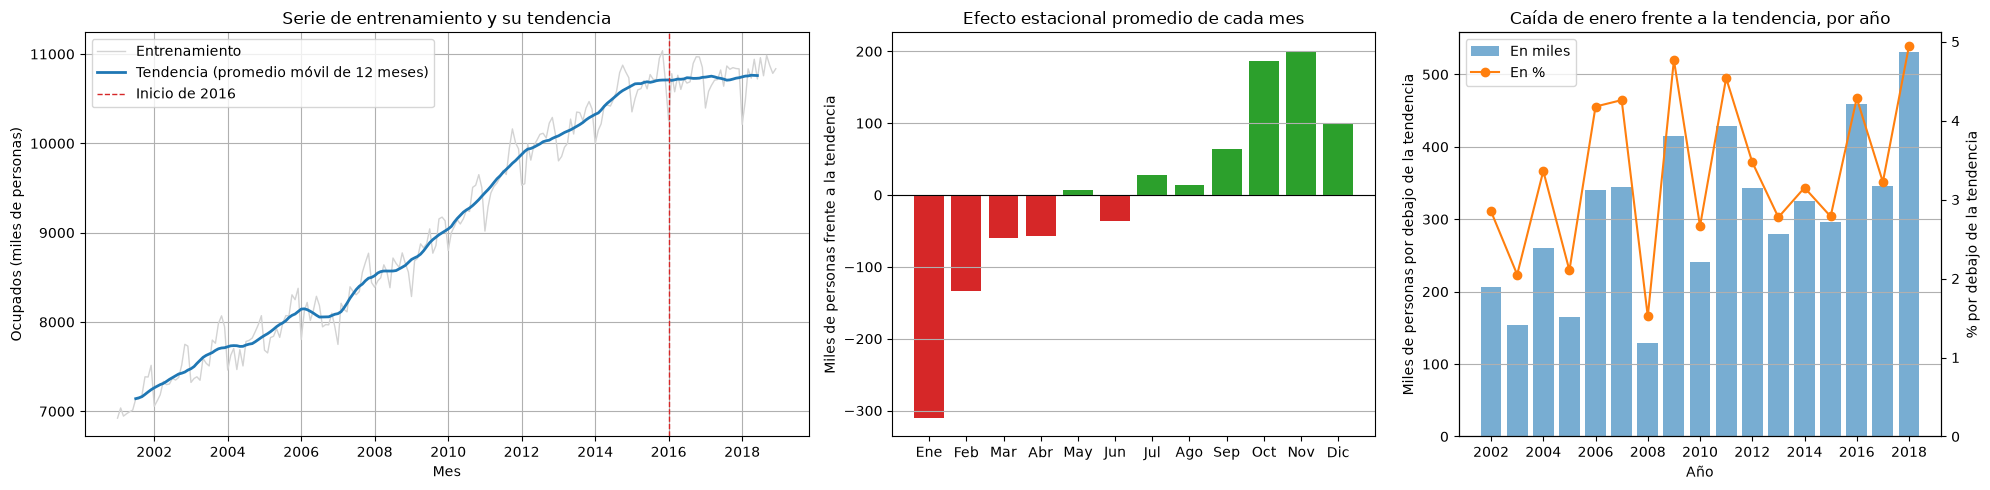

In [6]:
# Rasgos de la serie de entrenamiento que orientan la configuración de los modelos.
# Solo se usa el entrenamiento, para que ninguna decisión dependa de la muestra de prueba.
nombres_meses = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]
anio_cambio = "2016"   # año desde el que la serie deja de crecer, según la gráfica anterior


def pendiente_anual(serie):
    """Pendiente de una tendencia lineal con dummies de mes, en miles de personas por año.

    Las dummies evitan que el patrón estacional se confunda con la tendencia
    cuando el periodo no empieza y termina en el mismo mes.
    """
    t = np.arange(len(serie)) / 12
    dummies_mes = pd.get_dummies(serie.index.month, drop_first=True, dtype=float).to_numpy()
    X = sm.add_constant(np.column_stack([t, dummies_mes]))
    return sm.OLS(serie.to_numpy(), X).fit().params[1]


# 1. Cambio de la tendencia: pendiente antes y después del año de cambio
periodos = {"2001-2015": train.loc[:"2015"], f"{anio_cambio}-2018": train.loc[anio_cambio:]}
pendientes = pd.Series({nombre: pendiente_anual(serie) for nombre, serie in periodos.items()})
print("Pendiente de la tendencia (miles de personas por año):")
print(pendientes.round(1).to_string())

# 2. Patrón estacional: efecto de cada mes con la descomposición clásica aditiva y multiplicativa
desc_aditiva = seasonal_decompose(train, model="additive")
desc_multiplicativa = seasonal_decompose(train, model="multiplicative")
efectos_estacionales = pd.DataFrame({
    "Aditivo (miles)": desc_aditiva.seasonal.iloc[:12].to_numpy(),          # el entrenamiento empieza en enero
    "Multiplicativo (%)": 100 * (desc_multiplicativa.seasonal.iloc[:12].to_numpy() - 1),
}, index=nombres_meses)
print("\nEfecto estacional de cada mes frente a la tendencia:")
print(efectos_estacionales.round(1).to_string())

# 3. Tamaño de la caída de enero frente a la tendencia en cada año.
# Si la caída fuera estable en miles, el efecto sería aditivo; si fuera estable en porcentaje,
# multiplicativo; si crece incluso en porcentaje, el patrón estacional cambió con el tiempo.
es_enero = train.index.month == 1
tendencia_enero = desc_aditiva.trend[es_enero].dropna()   # enero de 2001 no tiene tendencia
caida_enero = pd.DataFrame({
    "Tendencia (miles)": tendencia_enero,
    "Caída (miles)": tendencia_enero - train[tendencia_enero.index],
})
caida_enero["Caída (%)"] = 100 * caida_enero["Caída (miles)"] / caida_enero["Tendencia (miles)"]
caida_enero.index = caida_enero.index.year
print("\nCaída de enero frente a la tendencia, por año:")
print(caida_enero.round(1).to_string())

tabla_enero = pd.DataFrame({
    "2002-2005": caida_enero.loc[2002:2005].mean(),
    "2016-2018": caida_enero.loc[2016:2018].mean(),
}).T
tabla_enero.loc["Cociente 2016-2018 / 2002-2005"] = tabla_enero.loc["2016-2018"] / tabla_enero.loc["2002-2005"]
print("\nPromedio de enero al inicio y al final del entrenamiento:")
print(tabla_enero.round(2).to_string())

# Gráficas: tendencia con el año de cambio, efecto de cada mes y caída de enero por año
fig, axes = plt.subplots(1, 3, figsize=(20, 5), gridspec_kw={"width_ratios": [3, 2, 2]})

axes[0].plot(train, color="lightgray", linewidth=1, label="Entrenamiento")
axes[0].plot(desc_aditiva.trend, color="C0", linewidth=2, label="Tendencia (promedio móvil de 12 meses)")
axes[0].axvline(pd.Timestamp(f"{anio_cambio}-01-01"), color="C3", linestyle="--", linewidth=1,
                label=f"Inicio de {anio_cambio}")
axes[0].set_title("Serie de entrenamiento y su tendencia")
axes[0].set_xlabel("Mes")
axes[0].set_ylabel("Ocupados (miles de personas)")
axes[0].legend(loc="upper left")
axes[0].grid()

colores_barras = ["C3" if efecto < 0 else "C2" for efecto in efectos_estacionales["Aditivo (miles)"]]
axes[1].bar(nombres_meses, efectos_estacionales["Aditivo (miles)"], color=colores_barras)
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_title("Efecto estacional promedio de cada mes")
axes[1].set_ylabel("Miles de personas frente a la tendencia")
axes[1].grid(axis="y")

# Caída de enero en miles (barras, eje izquierdo) y en porcentaje (línea, eje derecho)
axes[2].bar(caida_enero.index, caida_enero["Caída (miles)"], color="C0", alpha=0.6, label="En miles")
axes[2].set_ylabel("Miles de personas por debajo de la tendencia")
axes[2].set_xlabel("Año")
axes[2].set_xticks(caida_enero.index[::2])   # años enteros, uno de cada dos para que se lean
eje_porcentaje = axes[2].twinx()
eje_porcentaje.plot(caida_enero.index, caida_enero["Caída (%)"], color="C1", marker="o", label="En %")
eje_porcentaje.set_ylabel("% por debajo de la tendencia")
eje_porcentaje.set_ylim(bottom=0)
axes[2].set_title("Caída de enero frente a la tendencia, por año")
lineas = axes[2].get_legend_handles_labels()[0] + eje_porcentaje.get_legend_handles_labels()[0]
etiquetas = axes[2].get_legend_handles_labels()[1] + eje_porcentaje.get_legend_handles_labels()[1]
axes[2].legend(lineas, etiquetas, loc="upper left")
axes[2].grid(axis="y")

fig.tight_layout()
plt.show()

### Rasgos de la serie de entrenamiento

**Cambio de la tendencia.** Con una tendencia lineal y dummies de mes, la serie creció 261.7 mil personas por año entre 2001 y 2015, y solo 15.2 mil por año entre 2016 y 2018, cerca de 94 % menos. En la gráfica «Serie de entrenamiento y su tendencia», la tendencia sube de forma casi continua hasta 2015 y luego se aplana alrededor de 10,700 mil. Este cambio afecta a cualquier modelo que estime una pendiente con toda la historia, porque tendería a extender hacia el futuro un crecimiento que ya no ocurre. Por eso, en cada familia se incluyen alternativas que pueden adaptarse a él: tendencias amortiguadas o ausentes en la suavización exponencial, ventanas de estimación que usan solo los años recientes en la suavización exponencial y en la regresión, y diferenciación en los modelos ARIMA, que pronostican a partir del nivel reciente.

**Forma del patrón estacional.** En la gráfica «Efecto estacional promedio de cada mes», enero es el mes con el mayor efecto: queda 310.5 mil personas (3.4 %) por debajo de la tendencia, y febrero 134.2 mil. Desde septiembre la serie sube, hasta alcanzar sus valores más altos en octubre y noviembre, con 186.0 y 200.8 mil por encima de la tendencia. Entre diciembre y enero el efecto pasa de +98.1 a -310.5 mil, un cambio de 408.6 mil personas en un solo mes. Un patrón tan brusco requiere que cada mes pueda tener su propio efecto, o una representación con suficientes términos de alta frecuencia.

**Tamaño del patrón estacional.** Entre 2002-2005 y 2016-2018, la tendencia de enero aumentó 42 % (de 7,577.8 a 10,731.9 mil). Si el efecto estacional fuera aditivo, la caída de enero sería parecida en miles de personas en ambos periodos; si fuera multiplicativo, habría crecido en la misma proporción que el nivel, es decir, 1.42 veces. En realidad se multiplicó por 2.27 (de 196.3 a 445.5 mil personas) y pasó de 2.59 % a 4.15 % del nivel. El supuesto multiplicativo describe mejor la serie que el aditivo, porque la caída sí creció con el nivel, pero tampoco basta: creció incluso como porcentaje. Además, como muestra la gráfica «Caída de enero frente a la tendencia, por año», varía bastante de un año a otro, entre 129.6 mil (1.5 %) en 2008 y 531.6 mil (4.9 %) en 2018. Esto es un indicio, no una prueba, porque la descomposición clásica supone un mismo patrón para todos los años y estima la tendencia con un promedio móvil, pero sugiere que el patrón estacional cambió con el tiempo.

Estos rasgos orientan dos decisiones comunes a todas las familias. Primero, se evalúan versiones aditivas y multiplicativas de la estacionalidad: la multiplicativa describe mejor la historia completa, pero en los años recientes, en los que el nivel cambió poco, las dos pueden pronosticar de forma parecida, de modo que los datos no permiten descartar ninguna antes de evaluar los modelos. En la suavización exponencial, la estacionalidad puede ser aditiva o multiplicativa; en la regresión y en los modelos ARIMA, el equivalente multiplicativo es ajustar el logaritmo de la serie. Segundo, los modelos deben poder darle más peso al patrón estacional reciente: en la suavización exponencial, con el parámetro de actualización de la estacionalidad $\gamma$; en los modelos ARIMA, con la componente estacional, que relaciona cada mes con el mismo mes de años anteriores; y en todas las familias, con ventanas de estimación que usan solo los años más recientes.

## 3. Esquema de validación y funciones comunes

Para elegir entre modelos y configuraciones sin usar la muestra de prueba, en la Parte 1 se aplica la misma validación con origen móvil del taller anterior. Se definen 6 cortes en el tiempo dentro del entrenamiento, y en cada uno el modelo se ajusta con los meses anteriores al corte y pronostica los 6 meses siguientes. Ajustar significa volver a estimar los parámetros del modelo solo con los datos disponibles hasta el corte, de modo que ningún pronóstico usa información posterior. Los 6 cortes cubren los semestres de 2016 a 2018, y en cada uno se calculan dos métricas:

- **RMSE** (raíz del error cuadrático medio), en miles de personas, que penaliza más los errores grandes.
- **MAPE** (error porcentual absoluto medio), en porcentaje del valor real, que permite leer el error en términos relativos.

Dentro de la validación, el criterio principal para elegir los hiperparámetros es el RMSE promedio de los 6 cortes, y el MAPE promedio se usa como complemento. Entre los mejores modelos se revisa además en cuántos cortes cada uno supera al naive estacional, para que la elección no dependa de un solo semestre.

En este esquema hay que distinguir dos ventanas. La primera es la del protocolo de evaluación: en cada corte, los datos disponibles van desde enero de 2001 hasta el mes anterior al corte, de modo que la historia disponible crece de un corte al siguiente (ventana expansiva). La segunda es la ventana de estimación de cada modelo: dentro de los datos disponibles en un corte, el modelo puede usar toda la historia (ventana recursiva) o solo los últimos $w$ meses (ventana móvil). La primera es igual para todos los modelos, y la segunda es un hiperparámetro que se busca en cada familia.

Las funciones de esta sección se usan en las dos partes del trabajo. En la Parte 1 trabajan con el entrenamiento y estos 6 cortes. En la Parte 2 reciben otra serie y otro esquema de cortes: la información disponible hasta cada diciembre, para elegir los hiperparámetros de cada año, y los orígenes mensuales de la evaluación. Así, todas las familias y las dos partes se evalúan con el mismo código.

Corte 1: ajuste 2001-01 a 2015-12 (180 meses) | validación 2016-01 a 2016-06
Corte 2: ajuste 2001-01 a 2016-06 (186 meses) | validación 2016-07 a 2016-12
Corte 3: ajuste 2001-01 a 2016-12 (192 meses) | validación 2017-01 a 2017-06
Corte 4: ajuste 2001-01 a 2017-06 (198 meses) | validación 2017-07 a 2017-12
Corte 5: ajuste 2001-01 a 2017-12 (204 meses) | validación 2018-01 a 2018-06
Corte 6: ajuste 2001-01 a 2018-06 (210 meses) | validación 2018-07 a 2018-12


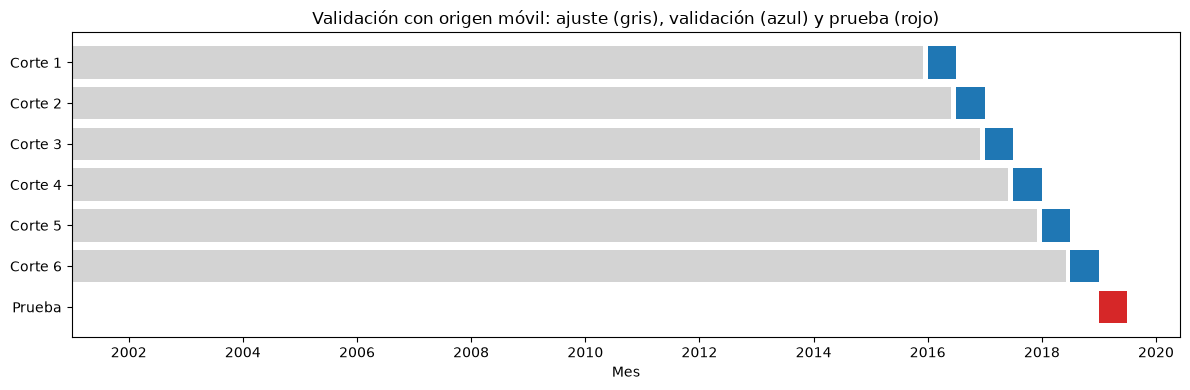

In [7]:
# Validación con origen móvil dentro del entrenamiento (la muestra de prueba no se usa aquí).
# TimeSeriesSplit no mezcla los datos: cada corte ajusta con los meses anteriores
# y valida con los 6 meses siguientes. Por defecto la ventana de ajuste es expansiva
# (max_train_size=None), es decir, cada corte tiene disponible toda la historia hasta ese punto.
n_cortes = 6
tscv = TimeSeriesSplit(n_splits=n_cortes, test_size=horizonte)

for numero, (idx_ajuste, idx_validacion) in enumerate(tscv.split(train), start=1):
    print(
        f"Corte {numero}: ajuste {train.index[idx_ajuste[0]]:%Y-%m} a {train.index[idx_ajuste[-1]]:%Y-%m} "
        f"({len(idx_ajuste)} meses) | validación {train.index[idx_validacion[0]]:%Y-%m} "
        f"a {train.index[idx_validacion[-1]]:%Y-%m}"
    )

# Diagrama de los cortes de validación y de la muestra de prueba
fig, ax = plt.subplots(figsize=(12, 4))
for numero, (idx_ajuste, idx_validacion) in enumerate(tscv.split(train), start=1):
    inicio_ajuste, fin_ajuste = train.index[idx_ajuste[0]], train.index[idx_ajuste[-1]]
    inicio_validacion, fin_validacion = train.index[idx_validacion[0]], train.index[idx_validacion[-1]]
    # Barra gris: meses disponibles para ajustar; barra azul: meses de validación
    ax.barh(numero, fin_ajuste - inicio_ajuste, left=inicio_ajuste, color="lightgray")
    ax.barh(numero, fin_validacion - inicio_validacion + pd.Timedelta(days=30),
            left=inicio_validacion, color="C0")

# Muestra de prueba, reservada hasta el final de la Parte 1
ax.barh(n_cortes + 1, test.index[-1] - test.index[0] + pd.Timedelta(days=30),
        left=test.index[0], color="C3")

ax.set_yticks(range(1, n_cortes + 2))
ax.set_yticklabels([f"Corte {numero}" for numero in range(1, n_cortes + 1)] + ["Prueba"])
ax.invert_yaxis()
ax.set_title("Validación con origen móvil: ajuste (gris), validación (azul) y prueba (rojo)")
ax.set_xlabel("Mes")
plt.tight_layout()
plt.show()

Los 6 cortes validan semestres consecutivos entre enero de 2016 y diciembre de 2018. En la gráfica «Validación con origen móvil: ajuste (gris), validación (azul) y prueba (rojo)», los datos disponibles para ajustar el modelo en cada corte van desde enero de 2001 hasta el mes anterior al corte (gris), entre 180 y 210 meses, y el modelo se evalúa en los 6 meses siguientes (azul). La muestra de prueba (rojo) queda por fuera de todos los cortes. Son exactamente los mismos cortes del taller anterior, lo que permite comparar los modelos nuevos con los anteriores corte por corte.

### Caché de evaluaciones

La optimización bayesiana evalúa cientos de configuraciones, y cada una requiere ajustar el modelo en todos los cortes; en la Parte 2, además, cada modelo se vuelve a ajustar en cada origen mensual. Para no repetir esos ajustes cada vez que se ejecuta el notebook, el resultado de cada configuración en cada corte se guarda en un archivo de la carpeta `cache/`, que no forma parte del repositorio. Cada archivo guarda las métricas y los pronósticos del corte, o el mensaje de error si el ajuste falló, junto con una firma: un hash SHA-256 de todos los campos que determinan el resultado.

- **La configuración del modelo:** la familia y sus hiperparámetros. Una configuración distinta se guarda en otro archivo, de modo que cambiar un hiperparámetro solo obliga a ajustar esa configuración.
- **Los datos:** un hash de los valores y de las fechas de la serie disponible en el corte y de los meses validados.
- **El corte:** sus fechas de inicio y fin de ajuste y de validación, el horizonte, la separación entre ajuste y validación y el tipo de ventana del protocolo.
- **Las versiones** de las librerías que intervienen en el ajuste y en las métricas.
- **La constante `CACHE_VERSION`.**

El nombre de cada archivo tiene tres partes: la familia del modelo, un código de 8 caracteres que resume la configuración, el primer mes de ajuste y el horizonte, y el último mes de ajuste en formato AAMM. Así, el corte se identifica por sus fechas y no por su número dentro de un esquema. Un corte que aparece en varios esquemas de evaluación, por ejemplo el que ajusta con los datos de enero de 2001 a diciembre de 2015 y valida el primer semestre de 2016, se guarda una sola vez y se reutiliza en todos, siempre que la configuración del modelo sea la misma.

Al leer un archivo, si la firma guardada no coincide con la actual, el resultado se descarta, se vuelve a ajustar el modelo y se muestra una advertencia con los campos que cambiaron. Así, el caché se invalida solo si cambian los datos, los cortes o las versiones de las librerías. Lo único que la firma no puede detectar es un cambio en el código de una función de ajuste o de pronóstico; en ese caso, hay que subir `CACHE_VERSION`, lo que invalida todos los archivos. Con `RECALCULAR = True`, el caché se ignora y todos los modelos se vuelven a ajustar.

Los archivos se escriben primero con la extensión `.tmp` y luego se renombran, de modo que una ejecución interrumpida nunca deja un resultado incompleto que pueda leerse como válido. El caché no cambia ningún resultado: el notebook se puede ejecutar completo sin él, por ejemplo en Google Colab, y solo tarda más.

In [8]:
# --- Caché de evaluaciones por corte ---
CARPETA_CACHE = Path("cache")   # ruta relativa a la carpeta del notebook (incluida en .gitignore)
CACHE_VERSION = 1               # se sube a mano cuando cambia el código de una función de ajuste o de pronóstico
RECALCULAR = False              # True ignora el caché y vuelve a ajustar todos los modelos

# Versiones de las librerías que intervienen en el ajuste y en las métricas: si cambian, el caché se invalida
VERSIONES_CACHE = {
    "numpy": np.__version__, "pandas": pd.__version__, "scipy": scipy.__version__,
    "statsmodels": statsmodels.__version__, "scikit-learn": sklearn.__version__,
    "pmdarima": pmdarima.__version__,
}

# Procesos para ajustar en paralelo los cortes pendientes de una evaluación, por función de pronóstico.
# Solo conviene en los modelos lentos de estimar; no cambia ningún resultado ni la firma del caché.
N_PROCESOS = os.cpu_count() or 1
PROCESOS_POR_MODELO = {"crear_pronostico_sarima": N_PROCESOS, "crear_pronostico_auto_arima": N_PROCESOS}


class ErrorDeAjuste(Exception):
    """Fallo del ajuste o del pronóstico en algún corte; el mensaje es el del error original."""


def hash_datos(datos: pd.Series | pd.DataFrame) -> str:
    """SHA-256 de los valores, el tipo, los nombres y el índice temporal de una serie o tabla."""
    contenido = pd.util.hash_pandas_object(datos, index=True).to_numpy().tobytes()
    descripcion = repr((getattr(datos, "name", None), list(getattr(datos, "columns", [])), str(datos.dtypes)))
    return hashlib.sha256(contenido + descripcion.encode()).hexdigest()


def forma_canonica(valor: object) -> object:
    """Convierte un valor a una forma estable y serializable en JSON, para que la firma no dependa
    del orden de las claves ni del tipo concreto de los números o las fechas."""
    if isinstance(valor, dict):
        return {str(clave): forma_canonica(valor[clave]) for clave in sorted(valor, key=str)}
    if isinstance(valor, (list, tuple)):
        return [forma_canonica(elemento) for elemento in valor]
    if isinstance(valor, (pd.Series, pd.DataFrame)):
        return hash_datos(valor)
    if isinstance(valor, np.ndarray):
        return hashlib.sha256(np.ascontiguousarray(valor).tobytes() + str(valor.dtype).encode()).hexdigest()
    if isinstance(valor, (pd.Timestamp, np.datetime64)):
        return pd.Timestamp(valor).isoformat()
    if isinstance(valor, np.generic):
        return valor.item()
    if valor is None or isinstance(valor, (bool, int, float, str)):
        return valor
    return repr(valor)


def hash_campos(campos: dict) -> str:
    """SHA-256 de unos campos ya en forma canónica."""
    return hashlib.sha256(json.dumps(campos, sort_keys=True, ensure_ascii=False).encode()).hexdigest()


def campos_corte(identidad: dict, serie_ajuste: pd.Series, serie_validacion: pd.Series, cv) -> dict:
    """Campos que determinan el resultado de una configuración en un corte, en forma canónica."""
    max_train_size = getattr(cv, "max_train_size", None)
    return forma_canonica({
        "modelo": identidad["modelo"],
        "config": identidad["config"],
        "corte": {
            "inicio_ajuste": serie_ajuste.index[0], "fin_ajuste": serie_ajuste.index[-1],
            "inicio_validacion": serie_validacion.index[0], "fin_validacion": serie_validacion.index[-1],
            "horizonte": len(serie_validacion), "separacion": getattr(cv, "gap", 0),
            "ventana_protocolo": "expansiva" if max_train_size is None else f"deslizante de {max_train_size}",
        },
        "datos": {"ajuste": serie_ajuste, "validacion": serie_validacion},
        "versiones": VERSIONES_CACHE,
        "cache_version": CACHE_VERSION,
    })


def ruta_cache(identidad: dict, serie_ajuste: pd.Series, h: int) -> Path:
    """Archivo de una configuración en un corte: <familia>_<código de 8 caracteres>_<AAMM>.joblib.

    El código es un hash de la configuración, del primer mes de ajuste y del horizonte, y AAMM es el
    último mes de ajuste. Así, el corte se identifica por sus fechas y no por su número, y un mismo
    corte tiene el mismo archivo en cualquier esquema de evaluación.
    """
    familia = identidad["modelo"].removeprefix("crear_pronostico_")
    codigo = hash_campos(forma_canonica({
        "config": identidad["config"], "inicio_ajuste": serie_ajuste.index[0], "horizonte": h,
    }))[:8]
    return CARPETA_CACHE / f"{familia}_{codigo}_{serie_ajuste.index[-1]:%y%m}.joblib"


def leer_cache(ruta: Path, campos: dict) -> tuple[dict | None, str]:
    """Lee el resultado de un corte. Devuelve (resultado, estado), con estado "missing" si no hay archivo,
    "corrupt" si no se puede leer, "invalid" si la firma no coincide y "loaded" si es válido."""
    if not ruta.exists():
        return None, "missing"
    try:
        contenido = joblib.load(ruta)
        campos_guardados, firma_guardada, resultado = contenido["fields"], contenido["fields_hash"], contenido["result"]
    except Exception:
        warnings.warn(f"Caché ilegible, se vuelve a ajustar: {ruta.name}", stacklevel=2)
        return None, "corrupt"
    if firma_guardada != hash_campos(campos):
        cambiados = sorted(campo for campo in set(campos) | set(campos_guardados)
                           if campos.get(campo) != campos_guardados.get(campo))
        warnings.warn(f"Caché desactualizado en {ruta.name}; cambiaron: {', '.join(cambiados)}", stacklevel=2)
        return None, "invalid"
    return resultado, "loaded"


def guardar_cache(ruta: Path, campos: dict, resultado: dict) -> None:
    """Guarda el resultado de un corte de forma atómica: escribe un .tmp y luego lo renombra."""
    ruta.parent.mkdir(parents=True, exist_ok=True)
    temporal = ruta.with_name(ruta.name + ".tmp")
    joblib.dump({"fields": campos, "fields_hash": hash_campos(campos), "result": resultado}, temporal)
    os.replace(temporal, ruta)

### Funciones de evaluación

Las funciones de evaluación son las del taller anterior, con cuatro cambios. Primero, la evaluación verifica que el modelo entregue 6 pronósticos finitos en cada corte, y si no lo hace en alguno, el modelo no se evalúa: así, ningún modelo se promedia sobre menos cortes que los demás. Segundo, cuando se indica la configuración del modelo, cada corte se lee del caché si su firma coincide, y solo se ajustan los cortes pendientes, en paralelo en los modelos lentos de estimar; la tabla de resultados indica si cada corte se leyó del caché (`loaded`) o se calculó (`computed`). Tercero, la evaluación recibe la serie y el esquema de cortes como argumentos, de modo que la misma función sirve para la validación de la Parte 1, para la reoptimización anual y para los orígenes de la Parte 2, y puede devolver el pronóstico de cada horizonte para calcular el error a 1, 2, ..., 6 meses. Cuarto, cada modelo evaluado en la validación de la Parte 1 se guarda en un registro común con su familia y su función de pronóstico, de modo que la comparación, la evaluación en la prueba y el pronóstico se construyen recorriendo el registro, sin repetir código para cada familia.

Todas las funciones de pronóstico tienen la misma forma: reciben la serie disponible hasta el corte y el número de meses a pronosticar, y devuelven los pronósticos. Si un modelo elige su especificación dentro de cada corte, como `auto_arima`, su función de pronóstico puede describirla en los atributos de la serie que devuelve, y esa descripción se guarda y se muestra junto con las métricas del corte.

In [9]:
def calcular_metricas(real, pronostico):
    """RMSE (miles de personas) y MAPE (%) de un pronóstico frente a los valores reales."""
    return {
        "rmse": np.sqrt(mean_squared_error(real, pronostico)),
        # sklearn devuelve el MAPE como fracción, por eso se multiplica por 100
        "mape": 100 * mean_absolute_percentage_error(real, pronostico),
    }


def evaluar_corte(funcion_pronostico, serie_ajuste, serie_validacion, campos=None, ruta=None) -> dict:
    """Ajusta y evalúa un modelo en un corte; si se indica una ruta, guarda el resultado apenas termina.

    Devuelve las métricas y los pronósticos, o el mensaje de error si el ajuste falla o el pronóstico
    no tiene h valores finitos. Si la función de pronóstico devuelve una serie con atributos (attrs),
    por ejemplo el modelo que eligió en el corte, se guardan como detalle del corte.
    """
    try:
        salida = funcion_pronostico(serie_ajuste, len(serie_validacion))
        pronostico = np.asarray(salida, dtype=float)
        if pronostico.shape != (len(serie_validacion),) or not np.isfinite(pronostico).all():
            raise ValueError(f"pronóstico inválido en el corte que inicia en {serie_validacion.index[0]:%Y-%m}")
        resultado = {**calcular_metricas(serie_validacion, pronostico),
                     "pronostico": pd.Series(pronostico, index=serie_validacion.index)}
        detalle = dict(getattr(salida, "attrs", {}))
        if detalle:
            resultado["detalle"] = detalle
    except Exception as error:
        resultado = {"error": f"{type(error).__name__}: {error}"[:200]}
    if ruta is not None:
        guardar_cache(ruta, campos, resultado)
    return resultado


def evaluar_validacion(funcion_pronostico, serie=train, cv=tscv, identidad=None, n_procesos=1,
                       con_pronosticos=False):
    """Evalúa un método de pronóstico en cada corte de un esquema de validación con origen móvil.

    funcion_pronostico(serie_ajuste, h) debe devolver h pronósticos usando solo serie_ajuste.
    serie y cv: la serie disponible y el esquema de cortes (por defecto, el entrenamiento y los 6 cortes
    de la Parte 1); cv puede ser cualquier objeto con un método split(serie), como TimeSeriesSplit.
    identidad: {"modelo": nombre de la función que crea el pronóstico, "config": configuración}. Si se
    indica, cada corte se lee del caché cuando su firma coincide, y solo se ajustan los cortes pendientes.
    n_procesos: procesos para ajustar en paralelo los cortes pendientes (no cambia el resultado).
    con_pronosticos: si es True, la tabla incluye el pronóstico de cada horizonte (columnas
    "pronostico_1", ..., "pronostico_h"), para calcular después el error por horizonte.
    Si el ajuste falla en algún corte, los demás se guardan igual y al final se lanza ErrorDeAjuste:
    un modelo solo se compara con los demás si produce pronósticos válidos en todos los cortes.
    Devuelve una tabla con el RMSE (miles), el MAPE (%), los detalles del modelo si los hay y el estado
    ("loaded" o "computed") de cada corte.
    """
    resultados, estados, pendientes = {}, {}, []
    for numero, (idx_ajuste, idx_validacion) in enumerate(cv.split(serie), start=1):
        serie_ajuste, serie_validacion = serie.iloc[idx_ajuste], serie.iloc[idx_validacion]
        assert serie_validacion.index[0] > serie_ajuste.index[-1], "la validación debe ser posterior al ajuste"
        campos = ruta = None
        if identidad is not None:
            campos = campos_corte(identidad, serie_ajuste, serie_validacion, cv)
            ruta = ruta_cache(identidad, serie_ajuste, len(serie_validacion))
            if not RECALCULAR:
                resultado, estado = leer_cache(ruta, campos)
                if estado == "loaded":
                    resultados[numero], estados[numero] = resultado, "loaded"
                    continue
        pendientes.append((numero, serie_ajuste, serie_validacion, campos, ruta))

    if n_procesos > 1 and len(pendientes) > 1:
        calculados = Parallel(n_jobs=min(n_procesos, len(pendientes)))(
            delayed(evaluar_corte)(funcion_pronostico, *tarea[1:]) for tarea in pendientes
        )
    else:
        calculados = [evaluar_corte(funcion_pronostico, *tarea[1:]) for tarea in pendientes]
    for (numero, *_), resultado in zip(pendientes, calculados):
        resultados[numero], estados[numero] = resultado, "computed"

    errores = [resultados[numero]["error"] for numero in sorted(resultados) if "error" in resultados[numero]]
    if errores:
        raise ErrorDeAjuste(errores[0])
    filas = []
    for numero in sorted(resultados):
        resultado = resultados[numero]
        fila = {
            "inicio_validacion": resultado["pronostico"].index[0].strftime("%Y-%m"),
            "rmse": resultado["rmse"],
            "mape": resultado["mape"],
            **resultado.get("detalle", {}),
            "estado": estados[numero],
        }
        if con_pronosticos:
            fila.update({f"pronostico_{paso}": valor
                         for paso, valor in enumerate(resultado["pronostico"].to_numpy(), start=1)})
        filas.append(fila)
    return pd.DataFrame(filas).set_index("inicio_validacion")


# Registro común de modelos: resultados por corte, familia y función de pronóstico de cada uno
validacion = {}
familias = {}
funciones_pronostico = {}


def registrar_modelo(nombre, familia, funcion_pronostico, resultados=None, identidad=None, n_procesos=1):
    """Evalúa un modelo en la validación (si no se entregan sus resultados) y lo guarda en el registro."""
    if resultados is None:
        resultados = evaluar_validacion(funcion_pronostico, identidad=identidad, n_procesos=n_procesos)
    validacion[nombre] = resultados
    familias[nombre] = familia
    funciones_pronostico[nombre] = funcion_pronostico
    return resultados


def resumir_validacion(nombres, referencias=("Naive estacional",)):
    """Resumen de la validación de los modelos indicados, ordenado por RMSE promedio.

    Incluye el RMSE y el MAPE promedio de los 6 cortes y, para cada referencia, el número
    de cortes en que cada modelo tiene un RMSE menor que el de esa referencia.
    """
    resumen = pd.DataFrame({
        "RMSE promedio": pd.Series({nombre: validacion[nombre]["rmse"].mean() for nombre in nombres}),
        "MAPE promedio (%)": pd.Series({nombre: validacion[nombre]["mape"].mean() for nombre in nombres}),
    })
    for referencia in referencias:
        resumen[f"Cortes mejores que {referencia}"] = pd.Series({
            nombre: int((validacion[nombre]["rmse"] < validacion[referencia]["rmse"]).sum())
            for nombre in nombres
        })
    return resumen.sort_values("RMSE promedio")


def error_por_corte(nombres, metrica="rmse"):
    """Tabla con la métrica indicada ("rmse" o "mape") de cada modelo (columnas) en cada corte (filas)."""
    return pd.DataFrame({nombre: validacion[nombre][metrica] for nombre in nombres})


def graficar_resumen_validacion(modelos, destacado, titulo, referencia="Naive estacional"):
    """Gráfica de barras del RMSE promedio de validación, con la referencia marcada con una línea.

    modelos: diccionario {etiqueta para la gráfica: nombre del modelo en validacion}.
    destacado: etiqueta del modelo que se resalta en verde; las referencias naive van en gris.
    Devuelve la tabla resumen de la validación con las etiquetas como índice.
    """
    etiquetas = {nombre: etiqueta for etiqueta, nombre in modelos.items()}
    resumen = resumir_validacion(list(modelos.values()), referencias=(referencia,)).rename(index=etiquetas)
    rmse_referencia = validacion[referencia]["rmse"].mean()

    orden = resumen.sort_values("RMSE promedio", ascending=False)
    colores = ["C2" if etiqueta == destacado else "gray" if etiqueta.startswith("Naive") else "C0"
               for etiqueta in orden.index]

    fig, ax = plt.subplots(figsize=(11, 0.5 * len(orden) + 1))
    ax.barh(orden.index, orden["RMSE promedio"], color=colores)
    ax.axvline(rmse_referencia, color="black", linestyle="--", linewidth=1,
               label=f"{referencia} ({rmse_referencia:.1f} mil)")
    for posicion, valor in enumerate(orden["RMSE promedio"]):
        # Fondo blanco para que la etiqueta se lea aunque cruce la línea de referencia
        ax.text(valor + 3, posicion, f"{valor:.1f}", va="center", fontsize=9,
                bbox=dict(facecolor="white", edgecolor="none", pad=1))
    ax.set_xlim(0, orden["RMSE promedio"].max() * 1.12)
    ax.set_title(titulo)
    ax.set_xlabel("RMSE promedio (miles de personas)")
    ax.legend(loc="upper right")
    ax.grid(axis="x")
    plt.tight_layout()
    plt.show()
    return resumen

### Funciones de la optimización bayesiana

Todas las familias se optimizan con la misma función. Cada familia define su espacio de búsqueda y cómo construir su función de pronóstico a partir de una configuración, y la optimización aplica las mismas reglas a todas:

- **Objetivo:** el RMSE promedio de los cortes de validación, calculado con la función `evaluar_validacion`. En la Parte 1 son los 6 cortes del entrenamiento; en la reoptimización anual de la Parte 2, la función recibe solo los datos disponibles hasta cada diciembre y sus propios cortes. Optuna busca la configuración que minimiza el objetivo con su algoritmo por defecto, TPE (*Tree-structured Parzen Estimator*): después de unos intentos iniciales al azar, separa los intentos con menor error de los demás y propone valores que aparecen con más frecuencia entre los mejores.
- **Reproducibilidad:** el algoritmo usa una semilla fija, de modo que la secuencia de intentos se repite en cada ejecución.
- **Fallos:** si el ajuste falla o el pronóstico no es válido en algún corte, el intento se descarta sin asignarle un error. Optuna lo registra como podado (*pruned*), un estado que TPE ubica entre los peores intentos; así, el algoritmo deja de proponer configuraciones que no se pueden estimar. Si el intento se marcara solo como fallido, TPE no lo tendría en cuenta y podría volver a proponer la misma región una y otra vez. Se registra el motivo del fallo y el número de intentos fallidos.
- **Intentos repetidos:** cuando Optuna propone una configuración discreta que ya evaluó, se reutiliza su resultado en lugar de volver a ajustar los modelos.
- **Revisión de bordes:** al terminar, se revisa si el mejor valor de cada hiperparámetro numérico quedó en el límite de su rango. Si es así, el rango se amplía en una segunda etapa, que empieza evaluando los mejores intentos de la primera. Como el espacio ampliado contiene al anterior, la segunda etapa parte del mejor resultado conocido y nunca termina con un error mayor.
- **Verificación:** el mejor intento se vuelve a evaluar al registrarlo, y su error debe coincidir con el obtenido durante la optimización.

Para leer cada estudio de la Parte 1 se usan dos gráficas: el RMSE de cada intento con el mejor valor acumulado, que muestra si la búsqueda se estabilizó, y la importancia de cada hiperparámetro, que indica cuáles explican la mayor parte de la variación del error entre intentos.

In [10]:
# Semilla de la optimización bayesiana, común a todos los estudios
SEMILLA = 2026


def identidad_cache(crear_pronostico, config):
    """Identidad de una evaluación en el caché: la función que crea el pronóstico y su configuración."""
    return {"modelo": crear_pronostico.__name__, "config": config}


def optimizar(sugerir_configuracion, crear_pronostico, n_intentos, serie=train, cv=tscv, semilla=SEMILLA,
              intentos_iniciales=(), mostrar=True):
    """Optimización bayesiana (TPE) del RMSE promedio de validación.

    sugerir_configuracion(trial) define el espacio de búsqueda y devuelve un diccionario con la
    configuración del intento. crear_pronostico(config) devuelve la función de pronóstico, con la
    firma (serie_ajuste, h). Cada intento se evalúa con evaluar_validacion en los cortes de cv sobre
    serie (por defecto, los 6 cortes de la Parte 1 sobre el entrenamiento), usando el caché y, si la
    familia lo tiene definido en PROCESOS_POR_MODELO, ajustes en paralelo.
    Si el ajuste falla en algún corte, el intento se descarta (estado PRUNED de Optuna), de modo que
    TPE lo cuenta entre los peores y no vuelve a proponer esa región; las configuraciones repetidas
    reutilizan el resultado ya calculado.
    intentos_iniciales: valores de hiperparámetros que se evalúan primero (por ejemplo, los mejores
    intentos de una etapa anterior), antes de que el algoritmo proponga los suyos.
    mostrar: si es False, no imprime el resumen del estudio (por ejemplo, en la reoptimización anual).
    """
    n_procesos = PROCESOS_POR_MODELO.get(crear_pronostico.__name__, 1)
    resultados_previos = {}

    def objetivo(trial):
        config = sugerir_configuracion(trial)
        trial.set_user_attr("config", config)
        clave = tuple(sorted(config.items()))
        if clave in resultados_previos:
            trial.set_user_attr("repetido", True)
        else:
            try:
                resultados_previos[clave] = evaluar_validacion(
                    crear_pronostico(config), serie=serie, cv=cv,
                    identidad=identidad_cache(crear_pronostico, config), n_procesos=n_procesos,
                )
            except ErrorDeAjuste as error:   # fallo del ajuste en algún corte: invalida el intento completo
                resultados_previos[clave] = str(error)
            except Exception as error:       # cualquier otro fallo al construir el modelo
                resultados_previos[clave] = f"{type(error).__name__}: {error}"[:200]

        resultado = resultados_previos[clave]
        if isinstance(resultado, str):
            trial.set_user_attr("error", resultado)
            # Un intento fallido sin valor (NaN) es invisible para TPE, que volvería a proponer la misma
            # región; descartado, TPE lo ubica entre los peores intentos sin inventarle un RMSE
            raise optuna.TrialPruned(resultado)
        trial.set_user_attr("rmse_cortes", resultado["rmse"].tolist())
        trial.set_user_attr("mape_cortes", resultado["mape"].tolist())
        trial.set_user_attr("cortes_cargados", int((resultado["estado"] == "loaded").sum()))
        return resultado["rmse"].mean()

    estudio = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=semilla))
    for parametros in intentos_iniciales:
        estudio.enqueue_trial(parametros)

    # Durante la optimización solo se muestran errores: los intentos fallidos se resumen al final
    optuna.logging.set_verbosity(optuna.logging.ERROR)
    inicio = pd.Timestamp.now()
    estudio.optimize(objetivo, n_trials=n_intentos)
    segundos = (pd.Timestamp.now() - inicio).total_seconds()
    optuna.logging.set_verbosity(optuna.logging.WARNING)
    if not mostrar:
        return estudio

    fallidos = [t for t in estudio.trials if t.state == optuna.trial.TrialState.PRUNED]
    repetidos = [t for t in estudio.trials if t.user_attrs.get("repetido")]
    nuevos_completos = [t for t in estudio.trials
                        if t.state == optuna.trial.TrialState.COMPLETE and not t.user_attrs.get("repetido")]
    print(f"Intentos: {len(estudio.trials)} | completos: {len(estudio.trials) - len(fallidos)} "
          f"| fallidos: {len(fallidos)} | repetidos (resultado reutilizado): {len(repetidos)}")
    print(f"Cortes leídos del caché: {sum(t.user_attrs['cortes_cargados'] for t in nuevos_completos)} "
          f"de {cv.get_n_splits(serie) * len(nuevos_completos)} (configuraciones completas distintas)")
    print(f"Tiempo total: {segundos / 60:.1f} min | por intento evaluado: "
          f"{segundos / max(len(estudio.trials) - len(repetidos), 1):.2f} s")
    if fallidos:
        motivos = pd.Series([t.user_attrs.get("error", "sin mensaje") for t in fallidos]).value_counts()
        print("Motivos de los intentos fallidos:")
        print(motivos.head(5).to_string())
    print(f"Mejor RMSE promedio: {estudio.best_value:.2f} (intento {estudio.best_trial.number})")
    return estudio


def resumir_estudio(estudio, n_mejores=10, referencia="Naive estacional"):
    """Mejores intentos completos de un estudio, sin repetidos: configuración, RMSE y MAPE promedio
    y número de cortes en que superan a la referencia."""
    rmse_referencia = validacion[referencia]["rmse"].to_numpy()
    filas = []
    for intento in estudio.trials:
        if intento.state != optuna.trial.TrialState.COMPLETE or intento.user_attrs.get("repetido"):
            continue
        rmse_cortes = np.asarray(intento.user_attrs["rmse_cortes"])
        filas.append({
            "Intento": intento.number,
            **intento.user_attrs["config"],
            "RMSE promedio": intento.value,
            "MAPE promedio (%)": np.mean(intento.user_attrs["mape_cortes"]),
            f"Cortes mejores que {referencia}": int((rmse_cortes < rmse_referencia).sum()),
        })
    return pd.DataFrame(filas).set_index("Intento").sort_values("RMSE promedio").head(n_mejores)


def graficar_estudio(estudio, titulo, referencia="Naive estacional"):
    """RMSE de cada intento con el mejor valor acumulado, e importancia de cada hiperparámetro.

    El eje del RMSE llega hasta el percentil 90 de los intentos, sin pasar del doble del RMSE de la
    referencia, para que los intentos con errores muy grandes no aplasten la gráfica; los que quedan
    por fuera se cuentan en una nota. La importancia se calcula con fANOVA (semilla fija) sobre los
    hiperparámetros presentes en todos los intentos completos; los que solo existen en algunas
    configuraciones (por ejemplo, el amortiguamiento cuando el modelo tiene tendencia) no entran.
    """
    completos = [t for t in estudio.trials if t.state == optuna.trial.TrialState.COMPLETE]
    numeros = [t.number for t in completos]
    valores = np.array([t.value for t in completos])
    rmse_referencia = validacion[referencia]["rmse"].mean()
    limite = max(min(np.percentile(valores, 90), 2 * rmse_referencia), rmse_referencia) * 1.05
    fuera_del_eje = int((valores > limite).sum())

    fig, axes = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={"width_ratios": [3, 2]})

    axes[0].scatter(numeros, valores, s=12, color="C0", alpha=0.6, label="RMSE del intento")
    axes[0].plot(numeros, np.minimum.accumulate(valores), color="C2", linewidth=2, label="Mejor RMSE acumulado")
    axes[0].axhline(rmse_referencia, color="black", linestyle="--", linewidth=1,
                    label=f"{referencia} ({rmse_referencia:.1f} mil)")
    axes[0].set_ylim(valores.min() * 0.95, limite)
    if fuera_del_eje:
        axes[0].text(0.01, 0.97, f"{fuera_del_eje} intentos con RMSE mayor a {limite:.0f} mil quedan fuera del eje",
                     transform=axes[0].transAxes, va="top", fontsize=9,
                     bbox=dict(facecolor="white", edgecolor="lightgray"))
    axes[0].set_title(f"{titulo}: RMSE promedio de validación por intento")
    axes[0].set_xlabel("Intento")
    axes[0].set_ylabel("RMSE promedio (miles de personas)")
    axes[0].legend(loc="upper right")
    axes[0].grid()

    importancias = pd.Series(optuna.importance.get_param_importances(
        estudio, evaluator=optuna.importance.FanovaImportanceEvaluator(seed=SEMILLA)
    )).sort_values()
    axes[1].barh(importancias.index, importancias.to_numpy(), color="C0")
    axes[1].set_title("Importancia de cada hiperparámetro (fANOVA)")
    axes[1].set_xlabel("Fracción de la variación del RMSE explicada")
    axes[1].grid(axis="x")

    fig.tight_layout()
    plt.show()


def revisar_bordes(estudio, categoricos_ordenados=(), minimos_naturales=(), sin_ampliacion=(), tolerancia=0.02):
    """Revisa si los hiperparámetros del mejor intento quedaron en el límite de su rango.

    Los numéricos están en el borde si quedan a menos del 2 % del rango de uno de sus extremos
    (en escala logarítmica si se buscan así); se indica si es el borde inferior o el superior.
    categoricos_ordenados: categóricos cuyas opciones tienen un orden (por ejemplo, tamaños de
        ventana); los demás categóricos no se revisan.
    minimos_naturales: hiperparámetros cuyo límite inferior es el menor valor posible (por ejemplo,
        un orden igual a 0); en ellos solo se revisa el borde superior.
    sin_ampliacion: hiperparámetros cuyo rango ya cubre todos los valores razonables (por ejemplo,
        un orden de diferenciación de 0 o 1); no se revisan.
    """
    mejor = estudio.best_trial
    filas = []
    for nombre, distribucion in mejor.distributions.items():
        valor = mejor.params[nombre]
        es_categorico = isinstance(distribucion, optuna.distributions.CategoricalDistribution)
        if es_categorico:
            opciones = list(distribucion.choices)
            rango = str(opciones)
        else:
            rango = f"[{distribucion.low}, {distribucion.high}]"

        if nombre in sin_ampliacion or (es_categorico and nombre not in categoricos_ordenados):
            filas.append({"Hiperparámetro": nombre, "Valor": valor, "Rango": rango, "En el borde": "no aplica"})
            continue

        if es_categorico:
            posicion = opciones.index(valor) / max(len(opciones) - 1, 1)
        else:
            bajo, alto, punto = distribucion.low, distribucion.high, valor
            if distribucion.log:
                bajo, alto, punto = np.log(bajo), np.log(alto), np.log(valor)
            posicion = (punto - bajo) / (alto - bajo) if alto > bajo else 0.5

        if posicion >= 1 - tolerancia:
            en_borde = "superior"
        elif posicion <= tolerancia and nombre not in minimos_naturales:
            en_borde = "inferior"
        else:
            en_borde = "no"
        filas.append({"Hiperparámetro": nombre, "Valor": valor, "Rango": rango, "En el borde": en_borde})
    return pd.DataFrame(filas).set_index("Hiperparámetro")


def registrar_mejor(estudio, nombre, familia, crear_pronostico):
    """Registra el mejor intento de un estudio como modelo del banco.

    Vuelve a evaluar la configuración (desde el caché si su firma coincide) y verifica que el error
    por corte coincida con el de la optimización (con una tolerancia pequeña por los optimizadores
    numéricos). Devuelve la configuración.
    """
    config = estudio.best_trial.user_attrs["config"]
    resultados = registrar_modelo(nombre, familia, crear_pronostico(config),
                                  identidad=identidad_cache(crear_pronostico, config),
                                  n_procesos=PROCESOS_POR_MODELO.get(crear_pronostico.__name__, 1))
    assert np.allclose(resultados["rmse"], estudio.best_trial.user_attrs["rmse_cortes"], rtol=1e-3), \
        f"{nombre}: el error al reevaluar no coincide con el de la optimización"
    return config

### Verificación del caché

Antes de usar el caché con los modelos, se comprueba que se comporta como se espera con un modelo rápido, un naive estacional con el periodo como hiperparámetro:

1. Al evaluar dos veces la misma configuración, la segunda lee los 6 cortes del caché.
2. Una configuración con otro hiperparámetro se guarda en otros archivos y no altera los de la primera.
3. Si se borra el archivo de un corte, solo ese corte se vuelve a ajustar.
4. Un archivo temporal `.tmp` nunca se lee como resultado.
5. Si cambian los datos, la firma no coincide, todos los cortes se vuelven a ajustar y la advertencia indica que cambió el campo de los datos.
6. Un esquema de cortes distinto reutiliza los cortes que comparte con el de la Parte 1. Con los datos hasta diciembre de 2017, los 4 cortes que validan 2016 y 2017 son los mismos de la Parte 1 y se leen del caché, y solo los 2 que validan 2015 se ajustan.
7. El resultado leído del caché coincide con el de una evaluación sin caché, y los pronósticos guardados por horizonte reproducen el RMSE de cada corte.

In [11]:
def crear_pronostico_naive_estacional(config):
    """Naive estacional con el periodo como hiperparámetro; solo se usa para verificar el caché."""
    def pronostico(serie_ajuste, h):
        return serie_ajuste.iloc[-config["m"]:].iloc[:h].to_numpy()

    return pronostico


if RECALCULAR:
    print("Con RECALCULAR = True el caché no se lee, así que se omite su verificación.")
else:
    config_prueba = {"m": 12}
    identidad_prueba = identidad_cache(crear_pronostico_naive_estacional, config_prueba)
    funcion_prueba = crear_pronostico_naive_estacional(config_prueba)
    cortes = list(tscv.split(train))

    def ruta_del_corte(identidad, numero):
        """Archivo del caché de una configuración en el corte indicado (de 1 a 6) de la Parte 1."""
        idx_ajuste, idx_validacion = cortes[numero - 1]
        return ruta_cache(identidad, train.iloc[idx_ajuste], len(idx_validacion))

    # 1. La segunda evaluación de la misma configuración lee los 6 cortes del caché
    evaluar_validacion(funcion_prueba, identidad=identidad_prueba)
    segunda_evaluacion = evaluar_validacion(funcion_prueba, identidad=identidad_prueba)
    assert (segunda_evaluacion["estado"] == "loaded").all()

    # 2. Otro hiperparámetro usa otros archivos y no altera los de la primera configuración
    config_otra = {"m": 6}
    identidad_otra = identidad_cache(crear_pronostico_naive_estacional, config_otra)
    assert ruta_del_corte(identidad_otra, 1) != ruta_del_corte(identidad_prueba, 1)
    evaluar_validacion(crear_pronostico_naive_estacional(config_otra), identidad=identidad_otra)
    assert (evaluar_validacion(funcion_prueba, identidad=identidad_prueba)["estado"] == "loaded").all()

    # 3. Si se borra el archivo de un corte, solo ese corte se vuelve a ajustar
    ruta_del_corte(identidad_prueba, 3).unlink()
    tras_borrar = evaluar_validacion(funcion_prueba, identidad=identidad_prueba)
    assert tras_borrar["estado"].tolist() == ["loaded", "loaded", "computed", "loaded", "loaded", "loaded"]

    # 4. Un archivo temporal nunca se lee como resultado
    ruta_corte_1 = ruta_del_corte(identidad_prueba, 1)
    temporal = ruta_corte_1.with_name(ruta_corte_1.name + ".tmp")
    temporal.write_bytes(b"escritura interrumpida")
    assert (evaluar_validacion(funcion_prueba, identidad=identidad_prueba)["estado"] == "loaded").all()
    temporal.unlink()

    # 5. Si cambian los datos, la firma no coincide y la advertencia nombra el campo que cambió
    serie_modificada = train.copy()
    serie_modificada.iloc[0] += 1
    with warnings.catch_warnings(record=True) as avisos:
        warnings.simplefilter("always")
        con_datos_modificados = evaluar_validacion(funcion_prueba, serie=serie_modificada, identidad=identidad_prueba)
    assert (con_datos_modificados["estado"] == "computed").all()
    assert len(avisos) == n_cortes and all("datos" in str(aviso.message) for aviso in avisos)
    with warnings.catch_warnings():   # se restauran los archivos con la serie original
        warnings.simplefilter("ignore")
        evaluar_validacion(funcion_prueba, identidad=identidad_prueba)

    # 6. Un esquema de cortes distinto reutiliza los cortes que comparte con el de la Parte 1: con los
    #    datos hasta diciembre de 2017, los cortes que validan 2016 y 2017 son los mismos. Los archivos
    #    de los cortes que validan 2015 se borran antes, para que la prueba no dependa de ejecuciones anteriores
    serie_hasta_2017 = train.loc[:"2017-12"]
    for idx_ajuste, idx_validacion in tscv.split(serie_hasta_2017):
        if serie_hasta_2017.index[idx_validacion[0]].year == 2015:
            ruta_cache(identidad_prueba, serie_hasta_2017.iloc[idx_ajuste], len(idx_validacion)).unlink(missing_ok=True)
    con_datos_hasta_2017 = evaluar_validacion(funcion_prueba, serie=serie_hasta_2017, identidad=identidad_prueba)
    estados_compartidos = con_datos_hasta_2017["estado"]
    assert (estados_compartidos.loc["2016-01":] == "loaded").all()
    assert (estados_compartidos.loc[:"2015-07"] == "computed").all()

    # 7. El resultado del caché coincide con el de una evaluación sin caché, y los pronósticos
    #    guardados por horizonte reproducen el RMSE de cada corte
    sin_cache = evaluar_validacion(funcion_prueba, con_pronosticos=True)
    assert np.allclose(segunda_evaluacion["rmse"], sin_cache["rmse"])
    pronosticos_cortes = sin_cache.filter(like="pronostico_").to_numpy()
    reales_cortes = np.array([train.iloc[idx_validacion].to_numpy() for _, idx_validacion in cortes])
    assert np.allclose(np.sqrt(((reales_cortes - pronosticos_cortes) ** 2).mean(axis=1)), sin_cache["rmse"])

    print("Verificación del caché: las 7 comprobaciones se cumplen.")
    print(f"Ejemplo de archivo: {ruta_del_corte(identidad_prueba, 1)}")
    print(f"Procesos para los ajustes en paralelo de los modelos ARIMA: {N_PROCESOS}")

Verificación del caché: las 7 comprobaciones se cumplen.
Ejemplo de archivo: cache/naive_estacional_4b04417a_1512.joblib
Procesos para los ajustes en paralelo de los modelos ARIMA: 15


Las 7 comprobaciones se cumplen: el caché solo reutiliza un resultado cuando coinciden la configuración, los datos, el corte y las versiones, y un mismo corte se comparte entre esquemas de evaluación distintos. Con los cortes, el caché y las funciones de evaluación y de optimización definidos, todas las familias de modelos se evalúan desde aquí con las mismas reglas, empezando por los modelos del taller anterior.

# Parte 1 — Evaluación con partición fija

## 4. Modelos del taller anterior

En el taller anterior se compararon promedios móviles, suavización exponencial y regresión lineal con los mismos 6 cortes de validación. Sus principales conclusiones fueron:

- **La estacionalidad es el componente decisivo.** El naive estacional, que repite el valor del mismo mes del año anterior, superó al naive y a todos los promedios móviles, y agregar el componente estacional a la suavización exponencial redujo su error de forma importante.
- **Las tendencias estimadas con toda la historia empeoran el pronóstico.** Extienden el crecimiento de 2001 a 2015 sobre un periodo en que la serie ya no crecía. En la suavización exponencial, el mejor modelo fue un Holt-Winters aditivo sin tendencia (ANA), estimado por máxima verosimilitud con toda la historia.
- **En la regresión, la ventana de estimación fue lo que más redujo el error.** La mejor regresión usó una tendencia lineal y dummies de mes estimadas solo con los últimos 24 meses. Los términos de Fourier y la escala logarítmica no la mejoraron.
- **El mejor modelo fue una combinación.** El promedio simple del Holt-Winters ANA y de la regresión, que se equivocaban en cortes distintos, obtuvo el menor error de validación de todos los modelos evaluados.

Para que la comparación con los modelos nuevos sea justa y verificable, en esta sección se recalculan, con las funciones y los cortes de la sección 3, los 25 modelos del resumen final del taller anterior: los dos modelos de referencia, los 5 promedios móviles, las 9 configuraciones de suavización exponencial, la mejor regresión de cada etapa de su búsqueda, la regresión elegida y la combinación. No se repite la búsqueda completa de ese taller: los hiperparámetros de las familias se vuelven a buscar en la sección 5, con optimización bayesiana. El RMSE y el MAPE de validación de cada modelo se comparan con los obtenidos en el taller anterior, que se guardan como constantes.

In [12]:
# --- Modelos de referencia, promedios móviles y suavización exponencial del taller anterior ---
# Cada familia se define con una función crear_pronostico_<familia>(config) que devuelve la función de
# pronóstico (serie_ajuste, h); la configuración identifica al modelo en el caché.

def crear_pronostico_naive(config):
    """Naive: repite el último valor observado en los h meses siguientes (no tiene hiperparámetros)."""
    def pronostico(serie_ajuste, h):
        return np.repeat(serie_ajuste.iloc[-1], h)

    return pronostico


def pronostico_promedio_movil(serie_ajuste, h, k):
    """Pronóstico recursivo con promedio móvil de ventana k.

    Cada pronóstico es el promedio de los últimos k valores de la historia;
    luego se agrega a la historia para calcular el siguiente (no usa valores reales futuros).
    """
    historia = list(serie_ajuste.iloc[-k:])
    pronosticos = []
    for _ in range(h):
        siguiente = np.mean(historia[-k:])
        pronosticos.append(siguiente)
        historia.append(siguiente)
    return np.array(pronosticos)


def crear_pronostico_ma(config):
    """Promedio móvil recursivo con ventana config["k"]."""
    def pronostico(serie_ajuste, h):
        return pronostico_promedio_movil(serie_ajuste, h, config["k"])

    return pronostico


def ajustar_ets(serie_ajuste, parametros, ventana=None, parametros_fijos=None, m=12):
    """Ajusta un ETSModel con los parámetros indicados (error, trend, damped_trend, seasonal).

    ventana: número de meses de la ventana móvil; si es None, se usa toda la historia (ventana recursiva).
    parametros_fijos: diccionario con los parámetros de suavización que no se estiman, por ejemplo
    {"smoothing_level": 0.5}; los demás parámetros y los estados iniciales se estiman por máxima
    verosimilitud. Si es None, todos se estiman por máxima verosimilitud.
    """
    if ventana is not None:
        serie_ajuste = serie_ajuste.iloc[-ventana:]
    periodo = m if parametros["seasonal"] is not None else None
    modelo = ETSModel(serie_ajuste, seasonal_periods=periodo, **parametros)
    if not parametros_fijos:
        return modelo.fit(disp=False)
    with modelo.fix_params(parametros_fijos):
        return modelo.fit(disp=False)


def crear_pronostico_ets(config):
    """Suavización exponencial (ETSModel).

    config: error, trend, damped_trend y seasonal de ETSModel y, de forma opcional, la ventana de
    estimación en meses ("ventana"; si no se indica, ventana recursiva). El pronóstico guarda en sus
    atributos si la optimización de máxima verosimilitud convergió.
    """
    parametros = {clave: valor for clave, valor in config.items() if clave != "ventana"}

    def pronostico(serie_ajuste, h):
        ajuste = ajustar_ets(serie_ajuste, parametros, config.get("ventana"))
        salida = ajuste.forecast(h)
        salida.attrs["convergio"] = bool(ajuste.mle_retvals["converged"])
        return salida

    return pronostico


def registrar_configuracion(nombre, familia, crear_pronostico, config):
    """Registra un modelo a partir de su función creadora y su configuración, usando el caché."""
    return registrar_modelo(nombre, familia, crear_pronostico(config),
                            identidad=identidad_cache(crear_pronostico, config),
                            n_procesos=PROCESOS_POR_MODELO.get(crear_pronostico.__name__, 1))


# Modelos de referencia
registrar_configuracion("Naive", "Referencia", crear_pronostico_naive, {})
registrar_configuracion("Naive estacional", "Referencia", crear_pronostico_naive_estacional, {"m": 12})
modelos_referencia = ["Naive", "Naive estacional"]

# Promedios móviles con las ventanas del taller anterior
ventanas_promedio_movil = [2, 3, 4, 6, 12]
modelos_promedio_movil = [f"MA k={k}" for k in ventanas_promedio_movil]
for k, nombre in zip(ventanas_promedio_movil, modelos_promedio_movil):
    registrar_configuracion(nombre, "Promedio móvil", crear_pronostico_ma, {"k": k})

# Configuraciones ETS del taller anterior, con ventana recursiva: (error, tendencia, amortiguamiento, estacionalidad)
configuraciones_ets = {
    "SES (ANN)":                dict(error="add", trend=None,  damped_trend=False, seasonal=None),
    "Holt (AAN)":               dict(error="add", trend="add", damped_trend=False, seasonal=None),
    "Holt amort. (AAdN)":       dict(error="add", trend="add", damped_trend=True,  seasonal=None),
    "HW adit. sin tend. (ANA)": dict(error="add", trend=None,  damped_trend=False, seasonal="add"),
    "HW adit. (AAA)":           dict(error="add", trend="add", damped_trend=False, seasonal="add"),
    "HW adit. amort. (AAdA)":   dict(error="add", trend="add", damped_trend=True,  seasonal="add"),
    "HW mult. sin tend. (MNM)": dict(error="mul", trend=None,  damped_trend=False, seasonal="mul"),
    "HW mult. (MAM)":           dict(error="mul", trend="add", damped_trend=False, seasonal="mul"),
    "HW mult. amort. (MAdM)":   dict(error="mul", trend="add", damped_trend=True,  seasonal="mul"),
}
modelos_ets = list(configuraciones_ets)
for nombre, config in configuraciones_ets.items():
    registrar_configuracion(nombre, "Suavización exponencial", crear_pronostico_ets, config)

print("Cortes en que convergió la optimización de cada configuración ETS (de 6):")
print(pd.Series({nombre: int(validacion[nombre]["convergio"].sum()) for nombre in modelos_ets}).to_string())

Cortes en que convergió la optimización de cada configuración ETS (de 6):
SES (ANN)                   6
Holt (AAN)                  6
Holt amort. (AAdN)          6
HW adit. sin tend. (ANA)    6
HW adit. (AAA)              6
HW adit. amort. (AAdA)      6
HW mult. sin tend. (MNM)    6
HW mult. (MAM)              6
HW mult. amort. (MAdM)      6


In [13]:
# --- Regresiones lineales del taller anterior ---
# Tiempo de referencia: t = 0 en el primer mes de la serie (enero de 2001)
inicio_serie = ocupados.index[0]

# Grado del polinomio de tiempo de cada tendencia
GRADOS_TENDENCIA = {"ninguna": 0, "lineal": 1, "cuadratica": 2, "cubica": 3, "grado_4": 4, "grado_5": 5}


def tiempo_en_anios(fechas):
    """Tiempo transcurrido desde enero de 2001, en años (t = 0 en enero de 2001, t = 1/12 en febrero...)."""
    meses_desde_inicio = (fechas.year - inicio_serie.year) * 12 + (fechas.month - inicio_serie.month)
    return np.asarray(meses_desde_inicio, dtype=float) / 12


def construir_regresores(fechas, tendencia, estacionalidad="ninguna", K=None):
    """Construye la matriz de regresores para las fechas indicadas.

    tendencia: una de las claves de GRADOS_TENDENCIA (polinomio en t, medido en años).
    estacionalidad: "ninguna", "dummies" (11 dummies de mes, con enero como categoría base)
                    o "fourier" (K pares seno-coseno con periodo de 12 meses).
    """
    t = tiempo_en_anios(fechas)
    mes = np.asarray(fechas.month)

    X = pd.DataFrame({"const": np.ones(len(fechas))}, index=fechas)
    for potencia in range(1, GRADOS_TENDENCIA[tendencia] + 1):
        X[f"t^{potencia}"] = t ** potencia

    if estacionalidad == "dummies":
        # Las 11 dummies se crean de forma explícita: con pd.get_dummies, un horizonte de
        # 6 meses no tendría todos los meses y las columnas no coincidirían con las del ajuste.
        for numero_mes in range(2, 13):
            X[f"mes_{numero_mes}"] = (mes == numero_mes).astype(float)
    elif estacionalidad == "fourier":
        for k in range(1, K + 1):
            angulo = 2 * np.pi * k * mes / 12
            if 2 * k < 12:  # con k = 6 el seno vale 0 en todos los meses, por eso se omite
                X[f"sen_{k}"] = np.sin(angulo)
            X[f"cos_{k}"] = np.cos(angulo)
    return X


def fechas_siguientes(serie_ajuste, h):
    """Devuelve las h fechas mensuales posteriores al último mes de serie_ajuste."""
    return pd.date_range(serie_ajuste.index[-1] + pd.DateOffset(months=1), periods=h, freq="MS")


def ajustar_regresion(serie_ajuste, config):
    """Estima por MCO la regresión con la configuración indicada.

    config["tendencia"] es obligatoria; las demás claves son opcionales:
    - "estacionalidad" ("ninguna", "dummies" o "fourier") y "K" (pares de Fourier).
    - "ventana": número de meses de la ventana móvil; si no se indica, se usa toda la historia (ventana recursiva).
    - "escala": "log" para ajustar el logaritmo de la serie; si no se indica, se usa la escala original.
    """
    ventana = config.get("ventana")
    if ventana is not None:
        serie_ajuste = serie_ajuste.iloc[-ventana:]
    y = np.log(serie_ajuste) if config.get("escala") == "log" else serie_ajuste
    X = construir_regresores(serie_ajuste.index, config["tendencia"],
                             config.get("estacionalidad", "ninguna"), config.get("K"))
    return sm.OLS(y, X).fit()


def crear_pronostico_regresion(config):
    """Regresión lineal por MCO: ajusta con serie_ajuste y pronostica los h meses siguientes, en miles."""
    def pronostico(serie_ajuste, h):
        ajuste = ajustar_regresion(serie_ajuste, config)
        X_futuro = construir_regresores(fechas_siguientes(serie_ajuste, h), config["tendencia"],
                                        config.get("estacionalidad", "ninguna"), config.get("K"))
        prediccion = np.asarray(ajuste.predict(X_futuro))
        # En escala logarítmica, la exponencial devuelve el pronóstico a miles de personas
        return np.exp(prediccion) if config.get("escala") == "log" else prediccion

    return pronostico


# Regresiones del resumen final del taller anterior: la mejor de cada etapa de la búsqueda
# y la regresión elegida (tendencia lineal + dummies, ventana de 24 meses)
nombre_regresion = "Tend. lineal + dummies, ventana 24"
configuraciones_regresion = {
    "Tend. cúbica":                            dict(tendencia="cubica"),
    "Tend. lineal + dummies":                  dict(tendencia="lineal", estacionalidad="dummies"),
    "Tend. cúbica + dummies":                  dict(tendencia="cubica", estacionalidad="dummies"),
    "Tend. grado 5 + dummies":                 dict(tendencia="grado_5", estacionalidad="dummies"),
    "Tend. cuadrática + dummies, ventana 36":  dict(tendencia="cuadratica", estacionalidad="dummies", ventana=36),
    "Tend. lineal + Fourier K=5, ventana 24":  dict(tendencia="lineal", estacionalidad="fourier", K=5, ventana=24),
    "Log: Tend. lineal + dummies, ventana 24": dict(tendencia="lineal", estacionalidad="dummies", ventana=24,
                                                    escala="log"),
    nombre_regresion:                          dict(tendencia="lineal", estacionalidad="dummies", ventana=24),
}
modelos_regresion = list(configuraciones_regresion)
for nombre, config in configuraciones_regresion.items():
    registrar_configuracion(nombre, "Regresión", crear_pronostico_regresion, config)

Verificación: los 25 modelos reproducen el RMSE y el MAPE de validación del taller anterior.

Validación de los modelos del taller anterior (RMSE en miles de personas):
                                                         Familia  RMSE promedio  MAPE promedio (%)  Cortes mejores que Naive estacional
Combinación ANA + regresión                          Combinación         116.47               0.92                                    3
HW adit. sin tend. (ANA)                 Suavización exponencial         122.02               0.98                                    4
Tend. lineal + dummies, ventana 24                     Regresión         123.68               0.94                                    3
Log: Tend. lineal + dummies, ventana 24                Regresión         124.00               0.94                                    3
Tend. lineal + Fourier K=5, ventana 24                 Regresión         124.33               0.97                                    4
HW adit. amort.

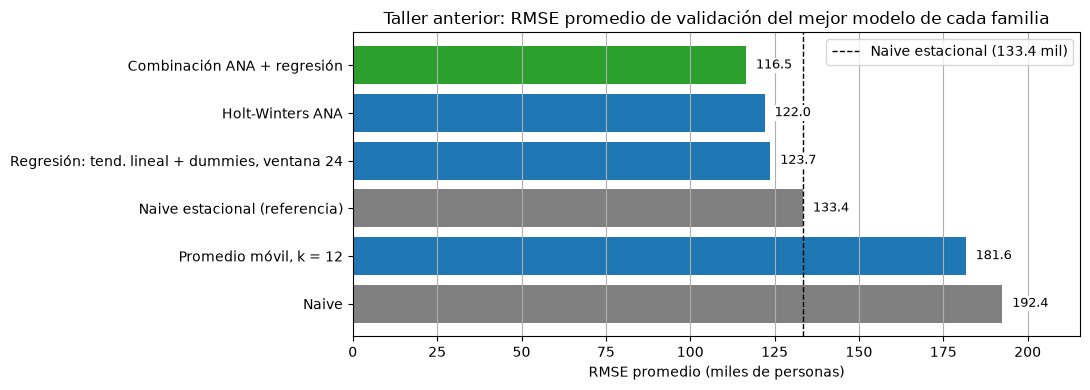

In [14]:
# --- Combinación del taller anterior y verificación de los 25 modelos ---
# Funciones creadoras por familia, para construir combinaciones a partir de las configuraciones
FABRICAS_PRONOSTICO = {"ets": crear_pronostico_ets, "regresion": crear_pronostico_regresion}


def crear_pronostico_combinacion(config):
    """Promedio simple de los pronósticos de varios modelos.

    config["componentes"]: lista de {"modelo": clave de FABRICAS_PRONOSTICO, "config": configuración};
    cada componente se ajusta en cada corte solo con los datos disponibles hasta ese corte.
    """
    funciones = [FABRICAS_PRONOSTICO[componente["modelo"]](componente["config"])
                 for componente in config["componentes"]]

    def pronostico(serie_ajuste, h):
        return np.mean([np.asarray(funcion(serie_ajuste, h), dtype=float) for funcion in funciones], axis=0)

    return pronostico


nombre_ets = "HW adit. sin tend. (ANA)"
nombre_combinacion = "Combinación ANA + regresión"
config_combinacion = {"componentes": [
    {"modelo": "ets", "config": configuraciones_ets[nombre_ets]},
    {"modelo": "regresion", "config": configuraciones_regresion[nombre_regresion]},
]}
registrar_configuracion(nombre_combinacion, "Combinación", crear_pronostico_combinacion, config_combinacion)
modelos_taller_anterior = (modelos_referencia + modelos_promedio_movil + modelos_ets
                           + modelos_regresion + [nombre_combinacion])

# Resultados de validación del taller anterior (RMSE y MAPE promedio de los 6 cortes, redondeados a 2 decimales)
VALIDACION_TALLER_ANTERIOR = pd.DataFrame.from_dict({
    "Naive":                                   (192.42, 1.41),
    "Naive estacional":                        (133.36, 1.05),
    "MA k=2":                                  (206.68, 1.52),
    "MA k=3":                                  (217.38, 1.66),
    "MA k=4":                                  (217.16, 1.67),
    "MA k=6":                                  (223.48, 1.71),
    "MA k=12":                                 (181.58, 1.38),
    "SES (ANN)":                               (202.39, 1.48),
    "Holt (AAN)":                              (215.74, 1.74),
    "Holt amort. (AAdN)":                      (205.08, 1.53),
    "HW adit. sin tend. (ANA)":                (122.02, 0.98),
    "HW adit. (AAA)":                          (145.96, 1.20),
    "HW adit. amort. (AAdA)":                  (125.05, 0.98),
    "HW mult. sin tend. (MNM)":                (137.99, 1.07),
    "HW mult. (MAM)":                          (158.93, 1.28),
    "HW mult. amort. (MAdM)":                  (137.95, 1.10),
    "Tend. cúbica":                            (262.15, 2.15),
    "Tend. lineal + dummies":                  (361.44, 3.24),
    "Tend. cúbica + dummies":                  (222.08, 1.91),
    "Tend. grado 5 + dummies":                 (129.50, 1.04),
    "Tend. cuadrática + dummies, ventana 36":  (137.44, 1.09),
    "Tend. lineal + Fourier K=5, ventana 24":  (124.33, 0.97),
    "Log: Tend. lineal + dummies, ventana 24": (124.00, 0.94),
    "Tend. lineal + dummies, ventana 24":      (123.68, 0.94),
    "Combinación ANA + regresión":             (116.47, 0.92),
}, orient="index", columns=["RMSE promedio", "MAPE promedio (%)"])

# Verificación: los 25 modelos reproducen el error de validación del taller anterior
assert list(VALIDACION_TALLER_ANTERIOR.index) == modelos_taller_anterior
assert all(validacion[nombre]["convergio"].all() for nombre in modelos_ets), "alguna configuración ETS no convergió"
resumen_taller_anterior = resumir_validacion(modelos_taller_anterior)
diferencias = (resumen_taller_anterior[VALIDACION_TALLER_ANTERIOR.columns].round(2)
               - VALIDACION_TALLER_ANTERIOR.loc[resumen_taller_anterior.index]).abs()
assert (diferencias <= 0.01).all().all(), f"No coinciden con el taller anterior:\n{diferencias[diferencias > 0.01].dropna(how='all')}"
print("Verificación: los 25 modelos reproducen el RMSE y el MAPE de validación del taller anterior.\n")

resumen_taller_anterior.insert(0, "Familia", pd.Series(familias))
print("Validación de los modelos del taller anterior (RMSE en miles de personas):")
print(resumen_taller_anterior.round(2).to_string())

# Mejor modelo de cada familia del taller anterior en la validación
mejores_taller_anterior = {
    "Naive": "Naive",
    "Naive estacional (referencia)": "Naive estacional",
    "Promedio móvil, k = 12": "MA k=12",
    "Holt-Winters ANA": nombre_ets,
    "Regresión: tend. lineal + dummies, ventana 24": nombre_regresion,
    "Combinación ANA + regresión": nombre_combinacion,
}
graficar_resumen_validacion(
    mejores_taller_anterior, destacado="Combinación ANA + regresión",
    titulo="Taller anterior: RMSE promedio de validación del mejor modelo de cada familia",
);

### Lectura de los modelos del taller anterior

Los 25 modelos reproducen el RMSE y el MAPE de validación del taller anterior, y las 9 configuraciones de suavización exponencial convergen en los 6 cortes, de modo que las funciones de la sección 3 y el caché no cambian ningún resultado. En la gráfica «Taller anterior: RMSE promedio de validación del mejor modelo de cada familia», la combinación del Holt-Winters ANA y de la regresión con tendencia lineal y dummies estimada con los últimos 24 meses tiene el menor error, 116.47 mil personas, con un MAPE de 0.92 %. La siguen sus dos componentes: el Holt-Winters ANA, con 122.02 mil, y la regresión, con 123.68 mil.

Solo 7 de los 25 modelos tienen un RMSE promedio menor que el del naive estacional (133.36 mil): la combinación, los Holt-Winters aditivos sin tendencia (ANA) y amortiguado (AAdA), las tres regresiones estimadas con los últimos 24 meses y la regresión con tendencia de grado 5 y dummies. Además, ninguno de ellos supera al naive estacional en más de 4 de los 6 cortes, y la combinación lo supera solo en 3. El margen de los mejores modelos frente a la referencia es, por lo tanto, moderado y depende del semestre.

Estos 25 modelos quedan en el registro común con sus resultados por corte, y son el punto de partida contra el que se comparan los modelos de las secciones siguientes.

## 5. Búsqueda de hiperparámetros de las familias del taller anterior

En el taller anterior, los hiperparámetros de cada familia se eligieron con grillas pequeñas: unas pocas estructuras de suavización exponencial, cinco ventanas de estimación y algunas combinaciones de tendencia y estacionalidad en la regresión. En esta sección se vuelven a elegir con búsquedas más amplias, usando solo el entrenamiento y los mismos 6 cortes de validación:

- **Suavización exponencial:** optimización bayesiana de la estructura, la ventana de estimación y los parámetros de suavización, que son continuos.
- **Regresión:** búsqueda en grilla completa de la tendencia, la estacionalidad, la ventana de estimación y la escala de la serie. Todos sus hiperparámetros son discretos, y cada ajuste por mínimos cuadrados toma milisegundos, de modo que se pueden evaluar todas las combinaciones; una búsqueda bayesiana solo exploraría una parte de ese espacio.
- **Promedio móvil:** búsqueda en grilla del tamaño de la ventana $k$, por la misma razón: tiene un solo hiperparámetro entero y se ajusta casi sin costo.

### Suavización exponencial

En el taller anterior, los parámetros de suavización $\alpha$, $\beta$, $\gamma$ y $\phi$ se estimaron por máxima verosimilitud. La máxima verosimilitud elige los parámetros que mejor explican cada mes a partir de los meses anteriores, es decir, minimiza el error de pronóstico a un mes. Sin embargo, el modelo se evalúa y se usa para pronosticar 6 meses, y los parámetros que mejor pronostican un mes adelante no tienen por qué ser los que mejor pronostican seis.

Aquí, la optimización bayesiana elige los parámetros de suavización directamente con el criterio con el que se evalúa el modelo: el RMSE promedio de los pronósticos a 6 meses en los cortes de validación. Los estados iniciales del modelo (nivel, pendiente y efectos estacionales iniciales) se siguen estimando por máxima verosimilitud en cada corte. La estructura y la ventana de estimación entran en la misma búsqueda. Como el taller anterior mostró que los modelos sin estacionalidad tienen errores mayores que el naive, todas las estructuras del espacio son de Holt-Winters, es decir, tienen componente estacional.

| Hiperparámetro | Valores | Justificación |
|---|---|---|
| Tendencia | ninguna, aditiva o aditiva amortiguada | La tendencia cambió en 2016 (sección 2); se incluye la opción sin tendencia y la amortiguada, que aplana la pendiente con el horizonte |
| Estacionalidad | aditiva (con error aditivo) o multiplicativa (con error multiplicativo) | Los rasgos de la sección 2 no permiten descartar ninguna de las dos; la estacionalidad multiplicativa se combina con error multiplicativo para evitar la inestabilidad numérica de la combinación con error aditivo |
| Ventana de estimación | 24, 36, 48, 60, 72, 96, 120 o 144 meses, o recursiva | Las opciones del taller anterior, más 72, 120 y 144 meses, para cubrir con más detalle los periodos entre 5 años y la historia completa |
| $\alpha$ (nivel) | 0.01 a 0.99 | Rango admisible completo |
| $\beta$ (pendiente) | fracción de $\alpha$, de 0.01 a 0.99 | Solo si hay tendencia; se busca como fracción de $\alpha$ para cumplir la restricción $\beta < \alpha$ |
| $\gamma$ (estacionalidad) | fracción de $1 - \alpha$, de 0.001 a 0.99 | Se busca como fracción de $1 - \alpha$ para cumplir $\gamma < 1 - \alpha$; el límite inferior permite un patrón estacional prácticamente fijo |
| $\phi$ (amortiguamiento) | 0.80 a 0.98 | Solo con tendencia amortiguada; son los límites usuales de este parámetro |

Las restricciones $\beta < \alpha$ y $\gamma < 1 - \alpha$ son las condiciones usuales para que los parámetros de un modelo ETS estén en la región admisible. Buscarlos como fracciones de su límite hace que toda combinación propuesta por Optuna sea válida, en lugar de descartar las que no cumplen las restricciones. Si la estimación de los estados iniciales no converge en algún corte, el intento se descarta, igual que cualquier otro fallo del ajuste. Las 6 configuraciones de Holt-Winters de la sección 4 tienen estructuras de este espacio con ventana recursiva; la diferencia es que en ellas los parámetros de suavización se estimaron por máxima verosimilitud.

Intentos: 300 | completos: 300 | fallidos: 0 | repetidos (resultado reutilizado): 0
Cortes leídos del caché: 1800 de 1800 (configuraciones completas distintas)
Tiempo total: 0.0 min | por intento evaluado: 0.00 s
Mejor RMSE promedio: 103.63 (intento 223)

Mejores intentos:
        tendencia estacionalidad  ventana  alpha  gamma_relativo  beta_relativo  phi  RMSE promedio  MAPE promedio (%)  Cortes mejores que Naive estacional
Intento                                                                                                                                                    
223       ninguna        aditiva    144.0  0.185           0.091            NaN  NaN        103.629              0.853                                    6
233       ninguna        aditiva    144.0  0.183           0.099            NaN  NaN        103.683              0.852                                    6
274       ninguna        aditiva    144.0  0.195           0.114            NaN  NaN        103.686   

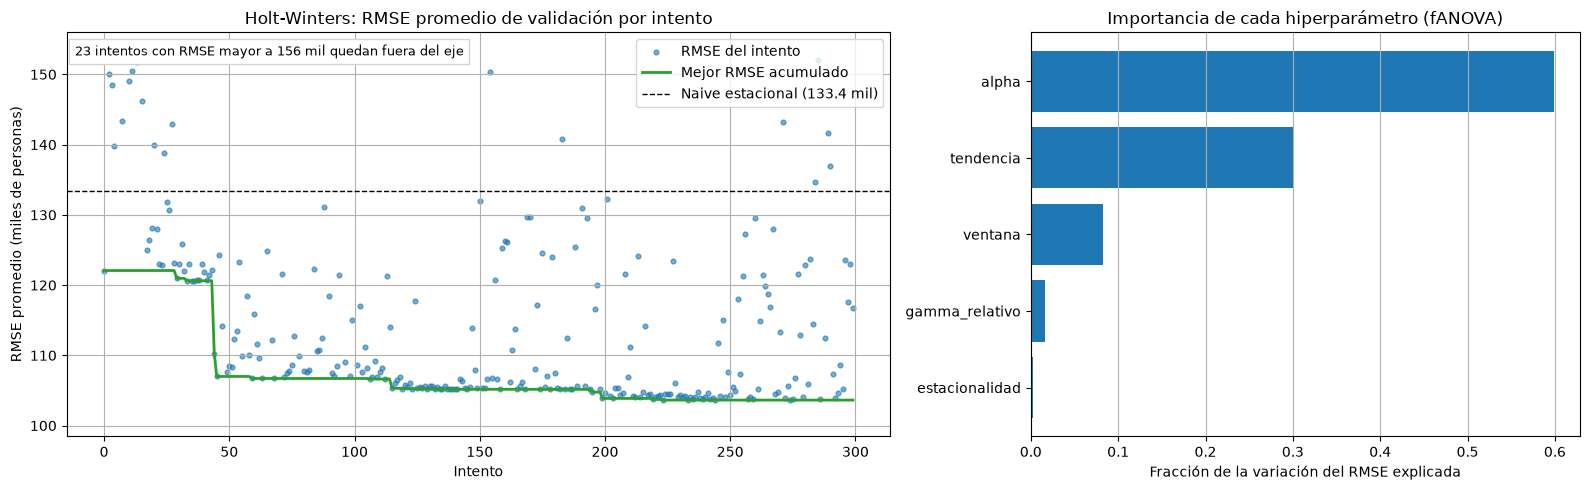


Revisión de bordes del mejor intento:
                   Valor                                     Rango En el borde
Hiperparámetro                                                                
tendencia        ninguna     ['ninguna', 'aditiva', 'amortiguada']   no aplica
estacionalidad   aditiva             ['aditiva', 'multiplicativa']   no aplica
ventana              144  [24, 36, 48, 60, 72, 96, 120, 144, None]          no
alpha           0.185484                              [0.01, 0.99]          no
gamma_relativo  0.091098                             [0.001, 0.99]          no


In [15]:
# --- Suavización exponencial: estructura, ventana y parámetros de suavización con Optuna ---
# Los ajustes de cada intento se hacen en paralelo por corte (no cambia ningún resultado)
PROCESOS_POR_MODELO["crear_pronostico_hw"] = N_PROCESOS

# Valores de cada hiperparámetro estructural y su traducción a los argumentos de ETSModel
TENDENCIAS_HW = {
    "ninguna":     dict(trend=None,  damped_trend=False),
    "aditiva":     dict(trend="add", damped_trend=False),
    "amortiguada": dict(trend="add", damped_trend=True),
}
ESTACIONALIDADES_HW = {
    "aditiva":        dict(error="add", seasonal="add"),
    "multiplicativa": dict(error="mul", seasonal="mul"),
}
VENTANAS_HW = [24, 36, 48, 60, 72, 96, 120, 144, None]   # meses; None = ventana recursiva


def sugerir_configuracion_hw(trial, ventanas=VENTANAS_HW):
    """Espacio de búsqueda del Holt-Winters; los hiperparámetros condicionales solo se proponen
    cuando la estructura los necesita."""
    config = {
        "tendencia": trial.suggest_categorical("tendencia", list(TENDENCIAS_HW)),
        "estacionalidad": trial.suggest_categorical("estacionalidad", list(ESTACIONALIDADES_HW)),
        "ventana": trial.suggest_categorical("ventana", ventanas),
        "alpha": trial.suggest_float("alpha", 0.01, 0.99),
        "gamma_relativo": trial.suggest_float("gamma_relativo", 0.001, 0.99),
    }
    if config["tendencia"] != "ninguna":
        config["beta_relativo"] = trial.suggest_float("beta_relativo", 0.01, 0.99)
    if config["tendencia"] == "amortiguada":
        config["phi"] = trial.suggest_float("phi", 0.80, 0.98)
    return config


def parametros_suavizacion(config):
    """Parámetros de suavización de ETSModel a partir de una configuración, con beta < alpha y gamma < 1 - alpha."""
    alpha = config["alpha"]
    parametros = {"smoothing_level": alpha, "smoothing_seasonal": config["gamma_relativo"] * (1 - alpha)}
    if "beta_relativo" in config:
        parametros["smoothing_trend"] = config["beta_relativo"] * alpha
    if "phi" in config:
        parametros["damping_trend"] = config["phi"]
    return parametros


def crear_pronostico_hw(config):
    """Holt-Winters con parámetros de suavización fijos, elegidos por la optimización bayesiana.

    Los estados iniciales (nivel, pendiente y efectos estacionales) se estiman por máxima verosimilitud
    en cada corte; si esa estimación no converge, se lanza un error y el intento se descarta.
    """
    parametros_modelo = {**TENDENCIAS_HW[config["tendencia"]], **ESTACIONALIDADES_HW[config["estacionalidad"]]}
    parametros_fijos = parametros_suavizacion(config)

    def pronostico(serie_ajuste, h):
        ajuste = ajustar_ets(serie_ajuste, parametros_modelo, ventana=config["ventana"],
                             parametros_fijos=parametros_fijos)
        if not ajuste.mle_retvals["converged"]:
            raise RuntimeError("la estimación de los estados iniciales no convergió")
        return ajuste.forecast(h).to_numpy()

    return pronostico


# Optimización bayesiana del Holt-Winters con los 6 cortes de la Parte 1
N_INTENTOS_HW = 300
estudio_hw = optimizar(sugerir_configuracion_hw, crear_pronostico_hw, N_INTENTOS_HW)

print("\nMejores intentos:")
print(resumir_estudio(estudio_hw).round(3).to_string())

graficar_estudio(estudio_hw, "Holt-Winters")

print("\nRevisión de bordes del mejor intento:")
print(revisar_bordes(estudio_hw, categoricos_ordenados=("ventana",)).to_string())

### Lectura de la primera etapa

Los 300 intentos se completaron sin fallos. En la gráfica «Holt-Winters: RMSE promedio de validación por intento», el mejor RMSE acumulado empieza cerca de 122 mil, baja a cerca de 107 mil alrededor del intento 45 y llega a 103.6 mil cerca del intento 200, sin cambios importantes después. Desde ese punto, buena parte de los intentos se ubican cerca del mínimo, porque el algoritmo propone sobre todo valores parecidos a los de los mejores intentos. Los 23 intentos con errores mayores a 156 mil quedan fuera del eje.

El mejor intento obtiene un RMSE promedio de 103.63 mil personas y un MAPE de 0.85 %, y supera al naive estacional en los 6 cortes. Los 10 mejores intentos comparten la misma estructura: sin tendencia y con estacionalidad aditiva, la del Holt-Winters ANA del taller anterior, pero estimada con los últimos 144 meses en lugar de toda la historia. Lo que cambia entre ellos son los parámetros de suavización: $\alpha$ está entre 0.178 y 0.195 y la fracción de $\gamma$ entre 0.091 y 0.129, con errores entre 103.63 y 103.81 mil. Que el mínimo esté en una zona amplia, donde cambios pequeños en los parámetros casi no alteran el error, indica que el resultado no depende de un valor exacto encontrado por azar.

En la gráfica «Importancia de cada hiperparámetro (fANOVA)», $\alpha$ explica cerca del 60 % de la variación del error entre intentos y el tipo de tendencia cerca del 30 %; la ventana explica cerca del 8 %, y la fracción de $\gamma$ y el tipo de estacionalidad casi nada. Esto es coherente con los rasgos de la sección 2: en un pronóstico a 6 meses, todos los meses parten del nivel estimado en el corte, y $\alpha$ controla qué tan de cerca sigue ese nivel a los últimos meses observados; una tendencia sin amortiguar, por su parte, extiende el crecimiento anterior a 2016. La importancia mide cuánto cambia el error en todo el espacio explorado, no en la zona del mínimo, por lo que una importancia baja de $\gamma$ no significa que su valor sea indiferente en el mejor modelo.

La revisión de bordes no marca ningún hiperparámetro numérico, y la ventana de 144 meses no es la última opción de su rango. Sin embargo, entre 144 meses y la ventana recursiva, que en los cortes usa entre 180 y 210 meses, no se evaluó ninguna ventana, y el mejor valor está justo al lado de ese hueco. Por eso se hace una segunda etapa que agrega las ventanas de 132, 156 y 168 meses y empieza evaluando los 10 mejores intentos de la primera.

Intentos: 300 | completos: 300 | fallidos: 0 | repetidos (resultado reutilizado): 0
Cortes leídos del caché: 1800 de 1800 (configuraciones completas distintas)
Tiempo total: 0.0 min | por intento evaluado: 0.00 s
Mejor RMSE promedio: 103.63 (intento 0)

Mejores intentos:
        tendencia estacionalidad  ventana  alpha  gamma_relativo  RMSE promedio  MAPE promedio (%)  Cortes mejores que Naive estacional  beta_relativo  phi
Intento                                                                                                                                                    
0         ninguna        aditiva    144.0  0.185           0.091        103.629              0.853                                    6            NaN  NaN
191       ninguna        aditiva    144.0  0.174           0.098        103.682              0.848                                    6            NaN  NaN
1         ninguna        aditiva    144.0  0.183           0.099        103.683              0.852      

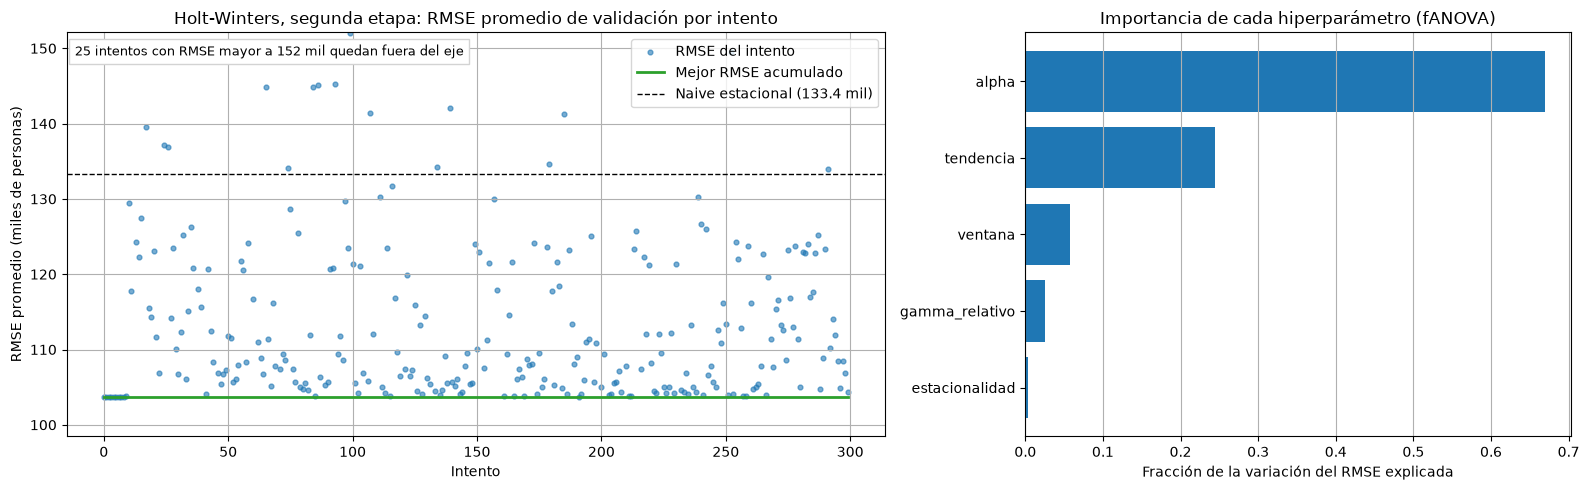


Revisión de bordes del mejor intento:
                   Valor                                                    Rango En el borde
Hiperparámetro                                                                               
tendencia        ninguna                    ['ninguna', 'aditiva', 'amortiguada']   no aplica
estacionalidad   aditiva                            ['aditiva', 'multiplicativa']   no aplica
ventana              144  [24, 36, 48, 60, 72, 96, 120, 132, 144, 156, 168, None]          no
alpha           0.185484                                             [0.01, 0.99]          no
gamma_relativo  0.091098                                            [0.001, 0.99]          no

Menor RMSE promedio por ventana de estimación (miles), en las dos etapas:
           Menor RMSE promedio  Intentos
Ventana                                 
24                      120.60        43
36                      121.08        29
48                      122.95        27
60                     

In [16]:
# --- Segunda etapa del Holt-Winters: ventanas intermedias entre 120 meses y la ventana recursiva ---
# El espacio contiene al de la primera etapa; solo se agregan las ventanas de 132, 156 y 168 meses
VENTANAS_HW_ETAPA_2 = [24, 36, 48, 60, 72, 96, 120, 132, 144, 156, 168, None]


def mejores_intentos(estudio, n=10):
    """Hiperparámetros de los n mejores intentos completos de un estudio, sin repetidos."""
    completos = [t for t in estudio.trials
                 if t.state == optuna.trial.TrialState.COMPLETE and not t.user_attrs.get("repetido")]
    return [t.params for t in sorted(completos, key=lambda t: t.value)[:n]]


# La segunda etapa empieza evaluando los 10 mejores intentos de la primera (leídos del caché)
estudio_hw_2 = optimizar(
    lambda trial: sugerir_configuracion_hw(trial, ventanas=VENTANAS_HW_ETAPA_2),
    crear_pronostico_hw, N_INTENTOS_HW, intentos_iniciales=mejores_intentos(estudio_hw),
)
assert estudio_hw_2.best_value <= estudio_hw.best_value + 1e-9, "la segunda etapa no puede empeorar a la primera"

print("\nMejores intentos:")
print(resumir_estudio(estudio_hw_2).round(3).to_string())

graficar_estudio(estudio_hw_2, "Holt-Winters, segunda etapa")

print("\nRevisión de bordes del mejor intento:")
print(revisar_bordes(estudio_hw_2, categoricos_ordenados=("ventana",)).to_string())

# Menor RMSE promedio alcanzado con cada ventana, sumando los intentos completos de las dos etapas
filas = [{"Ventana": "Recursiva" if t.params["ventana"] is None else int(t.params["ventana"]), "RMSE": t.value}
         for estudio in (estudio_hw, estudio_hw_2) for t in estudio.trials
         if t.state == optuna.trial.TrialState.COMPLETE]
rmse_por_ventana = (pd.DataFrame(filas).groupby("Ventana", sort=False)["RMSE"].agg(["min", "size"])
                    .rename(columns={"min": "Menor RMSE promedio", "size": "Intentos"})
                    .reindex(["Recursiva" if v is None else v for v in VENTANAS_HW_ETAPA_2])
                    .fillna({"Intentos": 0}).astype({"Intentos": int}))
print("\nMenor RMSE promedio por ventana de estimación (miles), en las dos etapas:")
print(rmse_por_ventana.round(2).to_string())

### Lectura de la segunda etapa

Los 300 intentos se completaron sin fallos, y los 10 primeros, que repiten los mejores de la primera etapa, se leyeron del caché. La segunda etapa no mejora el resultado: el mejor intento sigue siendo el de la primera etapa, y en la gráfica «Holt-Winters, segunda etapa: RMSE promedio de validación por intento» el mejor RMSE acumulado no cambia desde el primer intento. Ninguno de los intentos con ventanas de 132, 156 o 168 meses lo supera. La gráfica de importancia de esta etapa repite el orden de la primera: $\alpha$ y el tipo de tendencia explican la mayor parte de la variación del error.

La tabla del menor RMSE promedio por ventana muestra cómo cambia el error con la cantidad de historia que usa el modelo. El error baja de forma casi continua al pasar de ventanas cortas a largas, de 120.60 mil personas con 24 meses a 107.17 mil con 120 meses, alcanza su mínimo con 144 meses (103.63 mil) y vuelve a subir con 156 y 168 meses (cerca de 104.95 mil) y con la ventana recursiva (106.63 mil). El mínimo está en el interior del rango y sus vecinos tienen errores apenas mayores, de modo que la ventana de 144 meses no es un resultado aislado. Con esta ventana, el modelo deja por fuera los primeros años de la serie: el primer corte se estima con los datos desde enero de 2004 y el último, desde julio de 2006.

Las diferencias entre 144 meses y las ventanas más largas son de 1 a 3 mil personas, pequeñas frente a la variación del error entre cortes. La configuración elegida se somete, por eso, a una revisión de robustez antes de compararla con los modelos del taller anterior.

### Robustez del resultado y comparación con la máxima verosimilitud

Como los hiperparámetros se eligieron con los mismos 6 cortes con los que se mide el error, el RMSE del mejor intento puede ser algo optimista. Se hacen tres revisiones antes de registrar el modelo de esta familia. Primero, se repite la búsqueda con otra semilla y sin intentos iniciales, para comprobar que llega a la misma configuración y no depende de la secuencia de intentos. Segundo, se ajusta la misma estructura con la misma ventana, pero con los parámetros de suavización estimados por máxima verosimilitud; así se separa cuánto de la mejora proviene de la ventana y cuánto de elegir los parámetros con el error a 6 meses. Tercero, se compara el error por corte con el del naive estacional, el Holt-Winters ANA y la combinación del taller anterior, para ver si la mejora se repite en los distintos semestres o proviene de unos pocos cortes.

Intentos: 300 | completos: 300 | fallidos: 0 | repetidos (resultado reutilizado): 0
Cortes leídos del caché: 1800 de 1800 (configuraciones completas distintas)
Tiempo total: 0.0 min | por intento evaluado: 0.00 s
Mejor RMSE promedio: 103.60 (intento 223)

Mejor intento de cada estudio:
               Semilla 2026 Semilla 2027
tendencia           ninguna      ninguna
estacionalidad      aditiva      aditiva
ventana                 144          144
alpha              0.185484      0.18126
gamma_relativo     0.091098     0.099907
RMSE promedio    103.629488   103.599082

Parámetros de suavización estimados con todo el entrenamiento:
                        Máxima verosimilitud, ventana recursiva  Máxima verosimilitud, ventana 144  Optuna
alpha (nivel)                                            0.5914                             0.4439  0.1855
gamma (estacionalidad)                                   0.0000                             0.1900  0.0742

Resumen de la validación:
              

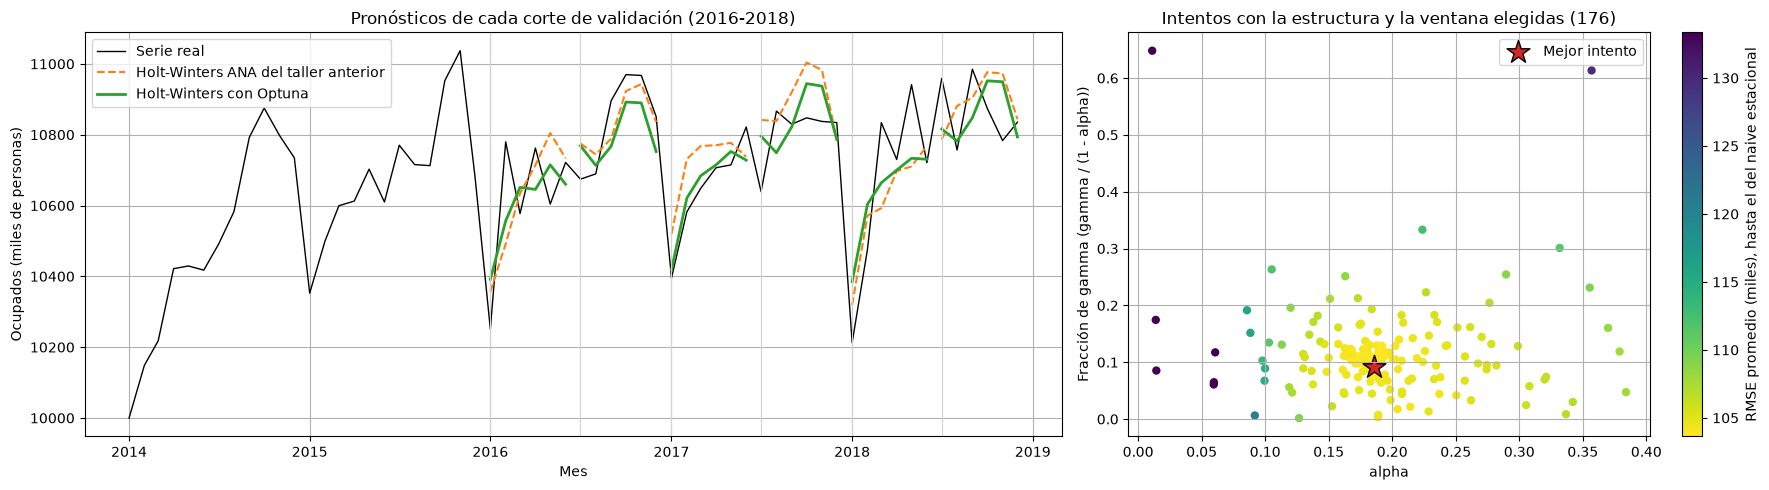

In [17]:
# --- Robustez del Holt-Winters con Optuna y comparación con la máxima verosimilitud ---
def parametros_estimados(ajuste):
    """Parámetros de un ajuste de statsmodels como una serie con sus nombres.

    statsmodels entrega los valores con un índice numérico y los nombres por separado (param_names).
    """
    return pd.Series(np.asarray(ajuste.params), index=ajuste.param_names)


# 1. Estudio independiente con otra semilla y el espacio de la segunda etapa, sin intentos iniciales
estudio_hw_semilla_2 = optimizar(
    lambda trial: sugerir_configuracion_hw(trial, ventanas=VENTANAS_HW_ETAPA_2),
    crear_pronostico_hw, N_INTENTOS_HW, semilla=SEMILLA + 1,
)
mejores_por_semilla = pd.DataFrame({
    f"Semilla {semilla}": {**estudio.best_trial.user_attrs["config"], "RMSE promedio": estudio.best_value}
    for semilla, estudio in [(SEMILLA, estudio_hw_2), (SEMILLA + 1, estudio_hw_semilla_2)]
})
print("\nMejor intento de cada estudio:")
print(mejores_por_semilla.to_string())

# 2. Registro del mejor intento de la segunda etapa como modelo de la familia
nombre_hw_optuna = "Holt-Winters con Optuna"
config_hw = registrar_mejor(estudio_hw_2, nombre_hw_optuna, "Suavización exponencial", crear_pronostico_hw)

# Misma estructura y ventana con los parámetros de máxima verosimilitud, para separar el efecto de la
# ventana del efecto de elegir los parámetros de suavización con el error a 6 meses
estructura_hw = {**TENDENCIAS_HW[config_hw["tendencia"]], **ESTACIONALIDADES_HW[config_hw["estacionalidad"]]}
nombre_hw_mle = f"Holt-Winters, ventana {config_hw['ventana']}, máxima verosimilitud"
registrar_configuracion(nombre_hw_mle, "Suavización exponencial", crear_pronostico_ets,
                        {**estructura_hw, "ventana": config_hw["ventana"]})
assert validacion[nombre_hw_mle]["convergio"].all(), "la máxima verosimilitud no convergió en algún corte"

# Parámetros de suavización estimados con todo el entrenamiento por máxima verosimilitud (toda la historia,
# como en el taller anterior, y la ventana elegida) frente a los elegidos por Optuna
nombres_parametros = {"smoothing_level": "alpha (nivel)", "smoothing_trend": "beta (pendiente)",
                      "smoothing_seasonal": "gamma (estacionalidad)", "damping_trend": "phi (amortiguamiento)"}
tabla_parametros = pd.DataFrame({
    "Máxima verosimilitud, ventana recursiva": parametros_estimados(ajustar_ets(train, estructura_hw)),
    f"Máxima verosimilitud, ventana {config_hw['ventana']}": parametros_estimados(
        ajustar_ets(train, estructura_hw, ventana=config_hw["ventana"])),
    "Optuna": pd.Series(parametros_suavizacion(config_hw)),
}).loc[lambda tabla: tabla.index.isin(nombres_parametros)].rename(index=nombres_parametros)
print("\nParámetros de suavización estimados con todo el entrenamiento:")
print(tabla_parametros.round(4).to_string())

# 3. Error por corte frente a las referencias, al Holt-Winters ANA y a la combinación del taller anterior
modelos_comparacion_hw = ["Naive estacional", nombre_ets, nombre_combinacion, nombre_hw_mle, nombre_hw_optuna]
print("\nResumen de la validación:")
print(resumir_validacion(modelos_comparacion_hw, referencias=("Naive estacional", nombre_combinacion))
      .round(2).to_string())
print("\nRMSE por corte (miles):")
print(error_por_corte(modelos_comparacion_hw).round(1).to_string())

# Gráficas: pronósticos de cada corte, y error según alpha y la fracción de gamma con la estructura y la ventana elegidas
fig, axes = plt.subplots(1, 2, figsize=(18, 5), gridspec_kw={"width_ratios": [3, 2]})

axes[0].plot(train.loc["2014":], color="black", linewidth=1, label="Serie real")
for numero, (idx_ajuste, idx_validacion) in enumerate(tscv.split(train), start=1):
    serie_ajuste = train.iloc[idx_ajuste]
    fechas_validacion = train.index[idx_validacion]
    axes[0].plot(fechas_validacion, funciones_pronostico[nombre_ets](serie_ajuste, horizonte), color="C1",
                 linestyle="--", label="Holt-Winters ANA del taller anterior" if numero == 1 else None)
    axes[0].plot(fechas_validacion, funciones_pronostico[nombre_hw_optuna](serie_ajuste, horizonte),
                 color="C2", linewidth=2, label=nombre_hw_optuna if numero == 1 else None)
    axes[0].axvline(fechas_validacion[0], color="lightgray", linewidth=0.8)
axes[0].set_title("Pronósticos de cada corte de validación (2016-2018)")
axes[0].set_xlabel("Mes")
axes[0].set_ylabel("Ocupados (miles de personas)")
axes[0].legend(loc="upper left")
axes[0].grid()

intentos_elegidos = [t for estudio in (estudio_hw, estudio_hw_2) for t in estudio.trials
                     if t.state == optuna.trial.TrialState.COMPLETE and not t.user_attrs.get("repetido")
                     and t.params["tendencia"] == config_hw["tendencia"]
                     and t.params["estacionalidad"] == config_hw["estacionalidad"]
                     and t.params["ventana"] == config_hw["ventana"]]
puntos = axes[1].scatter([t.params["alpha"] for t in intentos_elegidos],
                         [t.params["gamma_relativo"] for t in intentos_elegidos],
                         c=[t.value for t in intentos_elegidos], cmap="viridis_r", s=25,
                         vmax=validacion["Naive estacional"]["rmse"].mean())
axes[1].scatter(config_hw["alpha"], config_hw["gamma_relativo"], marker="*", s=300, color="C3",
                edgecolor="black", label="Mejor intento")
fig.colorbar(puntos, ax=axes[1], label="RMSE promedio (miles), hasta el del naive estacional")
axes[1].set_title(f"Intentos con la estructura y la ventana elegidas ({len(intentos_elegidos)})")
axes[1].set_xlabel("alpha")
axes[1].set_ylabel("Fracción de gamma (gamma / (1 - alpha))")
axes[1].legend(loc="upper right")
axes[1].grid()

fig.tight_layout()
plt.show()

### Resultados de la robustez y elección del modelo de suavización exponencial

**Segunda semilla.** La búsqueda con la semilla 2027, sin intentos iniciales, llega a la misma estructura y la misma ventana (sin tendencia, estacionalidad aditiva y 144 meses) y a parámetros casi iguales: $\alpha = 0.181$ frente a 0.185, y una fracción de $\gamma$ de 0.100 frente a 0.091. Su RMSE, 103.60 mil, es apenas 0.03 mil menor que el de la segunda etapa, una diferencia sin importancia práctica. La configuración no depende de la secuencia de intentos, y se registra la de la segunda etapa, que fue la búsqueda principal.

**Efecto de la ventana y de los parámetros.** Con la misma estructura ANA, la mejora frente al taller anterior se divide en dos partes:

| Modelo | Ventana | Parámetros de suavización | RMSE promedio (miles) | MAPE promedio (%) |
|---|---|---|---|---|
| Holt-Winters ANA (taller anterior) | recursiva | máxima verosimilitud | 122.02 | 0.98 |
| Holt-Winters ANA | 144 meses | máxima verosimilitud | 115.20 | 0.91 |
| Holt-Winters con Optuna | 144 meses | Optuna | **103.63** | **0.85** |

Limitar la historia a los últimos 144 meses reduce el RMSE en cerca de 7 mil personas, y elegir los parámetros de suavización con el error a 6 meses lo reduce en cerca de 12 mil más. Los parámetros estimados con todo el entrenamiento muestran la diferencia entre los dos criterios:

| Parámetro | Máxima verosimilitud, ventana recursiva | Máxima verosimilitud, ventana 144 | Optuna |
|---|---|---|---|
| $\alpha$ (nivel) | 0.5914 | 0.4439 | 0.1855 |
| $\gamma$ (estacionalidad) | 0.0000 | 0.1900 | 0.0742 |

La máxima verosimilitud, que minimiza el error a un mes, elige un nivel que se actualiza rápido. Optuna, que minimiza el error a 6 meses, elige un nivel que se actualiza más despacio. En un pronóstico a 6 meses, todos los meses parten del nivel estimado en el corte; con $\alpha$ alto, ese nivel sigue de cerca al último mes observado, y si ese mes es atípico, el error se traslada a los 6 meses pronosticados. En cuanto a la estacionalidad, con toda la historia la máxima verosimilitud deja el patrón estacional fijo ($\gamma = 0$), mientras que con la ventana de 144 meses y con Optuna el patrón se actualiza con los años, lo que permite incorporar el cambio de la caída de enero descrito en la sección 2. En la gráfica «Intentos con la estructura y la ventana elegidas (176)», los intentos con menor error forman una zona amplia con $\alpha$ entre 0.15 y 0.25 y una fracción de $\gamma$ entre 0.05 y 0.15, y los valores de $\alpha$ menores a 0.06 tienen errores cercanos al del naive estacional.

**Error por corte.**

| Inicio del corte | Naive estacional | ANA (taller anterior) | Combinación (taller anterior) | ANA, ventana 144, máx. verosimilitud | Holt-Winters con Optuna |
|---|---|---|---|---|---|
| 2016-01 | 149.4 | 152.8 | 152.3 | 154.7 | **132.2** |
| 2016-07 | 113.5 | 67.8 | **53.3** | 83.6 | 89.1 |
| 2017-01 | 122.8 | 105.8 | 77.2 | 75.2 | **47.6** |
| 2017-07 | 107.3 | 127.6 | 124.3 | 120.7 | **100.0** |
| 2018-01 | 153.3 | 150.1 | 161.5 | 143.1 | **140.8** |
| 2018-07 | 153.9 | 128.0 | 130.2 | 113.9 | **112.0** |
| **RMSE promedio** | 133.36 | 122.02 | 116.47 | 115.20 | **103.63** |
| **MAPE promedio (%)** | 1.05 | 0.98 | 0.92 | 0.91 | **0.85** |

*RMSE en miles de personas.*

El Holt-Winters con Optuna reduce el RMSE promedio del mejor modelo del taller anterior, la combinación, en cerca de 11 %, y es el único de la tabla que supera al naive estacional en los 6 cortes. Supera a la combinación en 5 de los 6 cortes; la excepción es julio de 2016, donde su error (89.1 mil) es mayor que el de los dos modelos del taller anterior. En la gráfica «Pronósticos de cada corte de validación (2016-2018)», sus pronósticos quedan más cerca de la serie real que los del ANA del taller anterior en los máximos de fin de 2017, donde el ANA sobreestima la serie, y al inicio de 2017.

Hay que tener en cuenta que los hiperparámetros se eligieron con los mismos 6 cortes con los que se mide el error, después de evaluar más de 600 configuraciones, por lo que el RMSE de 103.63 mil es probablemente algo optimista. La muestra de prueba, que no se ha usado, permitirá comprobar en la sección 9 si la mejora se mantiene.

Se elige el **Holt-Winters aditivo sin tendencia (ANA), estimado con los últimos 144 meses y con parámetros de suavización elegidos por Optuna** ($\alpha = 0.185$, $\gamma = 0.074$) como el modelo de suavización exponencial. Tiene el menor RMSE y el menor MAPE de la familia, supera al naive estacional en los 6 cortes y su configuración se repite con otra semilla.

### Regresión

La grilla combina todas las opciones de los cuatro hiperparámetros de la regresión:

| Hiperparámetro | Valores | Justificación |
|---|---|---|
| Tendencia | polinomio en el tiempo de grado 0 a 5 | Los grados del taller anterior; el grado 5 fue el límite de esa búsqueda |
| Estacionalidad | 11 dummies de mes, o $K$ pares de términos de Fourier con $K$ de 1 a 5 | Con $K = 6$, los términos de Fourier equivalen a las 11 dummies |
| Ventana de estimación | 24, 36, 48, 60, 72, 96, 120, 132, 144, 156 o 168 meses, o recursiva | Las mismas opciones de la suavización exponencial, para que las dos familias se comparen con los mismos periodos de estimación |
| Escala | original o logarítmica | La escala logarítmica es el equivalente multiplicativo de la regresión (sección 2) |

En total son $6 \times 6 \times 12 \times 2 = 864$ configuraciones, cada una evaluada en los 6 cortes de validación y guardada en el caché. Después de la grilla se resume el menor error alcanzado con cada valor de cada hiperparámetro, se revisa si el mejor modelo quedó en el borde de alguna opción ordenada (grado de la tendencia, ventana y número de términos de Fourier) y se compara su error por corte con la regresión y la combinación del taller anterior y con el Holt-Winters elegido.

In [18]:
# --- Regresión: búsqueda en grilla completa de tendencia, estacionalidad, ventana y escala ---
def evaluar_grilla(crear_pronostico, configuraciones, serie=train, cv=tscv, referencia="Naive estacional"):
    """Evalúa todas las configuraciones de una grilla con evaluar_validacion, usando el caché.

    Devuelve una tabla con el número de cada configuración en la grilla, sus hiperparámetros, el RMSE y
    el MAPE promedio y, si se evalúa sobre el entrenamiento, el número de cortes en que supera a la
    referencia, ordenada por RMSE. También devuelve las configuraciones que fallaron en algún corte,
    con su motivo; esas configuraciones no entran en la tabla.
    """
    rmse_referencia = validacion[referencia]["rmse"].to_numpy() if serie is train else None
    filas, fallidas = [], {}
    for numero, config in enumerate(configuraciones):
        try:
            resultado = evaluar_validacion(crear_pronostico(config), serie=serie, cv=cv,
                                           identidad=identidad_cache(crear_pronostico, config))
        except ErrorDeAjuste as error:
            fallidas[numero] = str(error)
            continue
        fila = {"Configuración": numero, **config,
                "RMSE promedio": resultado["rmse"].mean(), "MAPE promedio (%)": resultado["mape"].mean()}
        if rmse_referencia is not None:
            fila[f"Cortes mejores que {referencia}"] = int((resultado["rmse"].to_numpy() < rmse_referencia).sum())
        filas.append(fila)
    tabla = pd.DataFrame(filas).sort_values("RMSE promedio").set_index("Configuración")
    return tabla, fallidas


def revisar_bordes_grilla(mejor, opciones_ordenadas):
    """Indica si el mejor valor de cada hiperparámetro ordenado es la primera o la última opción de su grilla."""
    filas = []
    for nombre, opciones in opciones_ordenadas.items():
        posicion = opciones.index(mejor[nombre])
        en_borde = "inferior" if posicion == 0 else "superior" if posicion == len(opciones) - 1 else "no"
        descripcion = str(opciones) if len(opciones) <= 12 else f"{opciones[0]} a {opciones[-1]} ({len(opciones)} valores)"
        filas.append({"Hiperparámetro": nombre, "Valor": mejor[nombre], "Opciones": descripcion,
                      "En el borde": en_borde})
    return pd.DataFrame(filas).set_index("Hiperparámetro")


# Grilla: tendencias de grado 0 a 5, 11 dummies o Fourier con K de 1 a 5, las mismas ventanas del
# Holt-Winters y escala original o logarítmica (con K = 6, Fourier equivale a las 11 dummies)
TENDENCIAS_REGRESION = list(GRADOS_TENDENCIA)                       # de "ninguna" a "grado_5"
ESTACIONALIDADES_REGRESION = [("dummies", None)] + [("fourier", K) for K in range(1, 6)]
VENTANAS_REGRESION = VENTANAS_HW_ETAPA_2
ESCALAS_REGRESION = ["original", "log"]

configuraciones_grilla_regresion = [
    {"tendencia": tendencia, "estacionalidad": estacionalidad, "K": K, "ventana": ventana, "escala": escala}
    for tendencia in TENDENCIAS_REGRESION
    for estacionalidad, K in ESTACIONALIDADES_REGRESION
    for ventana in VENTANAS_REGRESION
    for escala in ESCALAS_REGRESION
]
inicio = pd.Timestamp.now()
grilla_regresion, fallidas_regresion = evaluar_grilla(crear_pronostico_regresion, configuraciones_grilla_regresion)
print(f"Configuraciones: {len(configuraciones_grilla_regresion)} | completas: {len(grilla_regresion)} "
      f"| fallidas: {len(fallidas_regresion)} | tiempo: {(pd.Timestamp.now() - inicio).total_seconds() / 60:.1f} min")

# Etiquetas legibles de la estacionalidad y la ventana de cada configuración, para los resúmenes
etiqueta_estacionalidad = {numero: "dummies" if config["K"] is None else f"Fourier K={config['K']}"
                           for numero, config in enumerate(configuraciones_grilla_regresion)}
etiqueta_ventana = {numero: "Recursiva" if config["ventana"] is None else str(config["ventana"])
                    for numero, config in enumerate(configuraciones_grilla_regresion)}
grilla_regresion["Estacionalidad"] = grilla_regresion.index.map(etiqueta_estacionalidad)
grilla_regresion["Ventana"] = grilla_regresion.index.map(etiqueta_ventana)
columnas_resumen = ["tendencia", "Estacionalidad", "Ventana", "escala", "RMSE promedio", "MAPE promedio (%)",
                    "Cortes mejores que Naive estacional"]
print("\nMejores configuraciones:")
print(grilla_regresion[columnas_resumen].head(10).round(2).to_string())

# Menor RMSE promedio alcanzado con cada valor de cada hiperparámetro
orden_ventanas = ["Recursiva" if ventana is None else str(ventana) for ventana in VENTANAS_REGRESION]
for columna, orden in [("tendencia", TENDENCIAS_REGRESION), ("Ventana", orden_ventanas)]:
    print(f"\nMenor RMSE promedio por {columna.lower()} (miles):")
    print(grilla_regresion.groupby(columna)["RMSE promedio"].min().reindex(orden).round(2).to_string())
print("\nMenor RMSE promedio por estacionalidad y escala (miles):")
print(grilla_regresion.pivot_table(index="Estacionalidad", columns="escala", values="RMSE promedio", aggfunc="min")
      .reindex(["dummies"] + [f"Fourier K={K}" for K in range(1, 6)])[ESCALAS_REGRESION].round(2).to_string())

# Revisión de bordes de los hiperparámetros ordenados del mejor modelo (las dummies equivalen a K = 6)
config_regresion_grilla = configuraciones_grilla_regresion[grilla_regresion.index[0]]
print("\nRevisión de bordes del mejor modelo:")
print(revisar_bordes_grilla(
    {**config_regresion_grilla, "K": config_regresion_grilla["K"] or 6},
    {"tendencia": TENDENCIAS_REGRESION, "ventana": VENTANAS_REGRESION, "K": [1, 2, 3, 4, 5, 6]},
).to_string())

# Registro del mejor modelo de la grilla
nombre_regresion_grilla = "Regresión con grilla completa"
registrar_configuracion(nombre_regresion_grilla, "Regresión", crear_pronostico_regresion, config_regresion_grilla)
assert np.isclose(validacion[nombre_regresion_grilla]["rmse"].mean(), grilla_regresion["RMSE promedio"].iloc[0])

modelos_comparacion_regresion = ["Naive estacional", nombre_regresion, nombre_combinacion, nombre_hw_optuna,
                                 nombre_regresion_grilla]
print("\nResumen de la validación:")
print(resumir_validacion(modelos_comparacion_regresion, referencias=("Naive estacional", nombre_combinacion))
      .round(2).to_string())
print("\nRMSE por corte (miles):")
print(error_por_corte(modelos_comparacion_regresion).round(1).to_string())

Configuraciones: 864 | completas: 864 | fallidas: 0 | tiempo: 0.0 min

Mejores configuraciones:
              tendencia Estacionalidad Ventana    escala  RMSE promedio  MAPE promedio (%)  Cortes mejores que Naive estacional
Configuración                                                                                                                  
740             grado_5        dummies     168  original         110.99               0.89                                    5
860             grado_5    Fourier K=5     168  original         112.84               0.90                                    5
591             grado_4        dummies     132       log         115.63               0.92                                    4
590             grado_4        dummies     132  original         116.18               0.94                                    4
741             grado_5        dummies     168       log         117.08               0.96                                    5
711     

### Lectura de la primera etapa de la grilla

Las 864 configuraciones se ajustaron en los 6 cortes sin fallos. La mejor tiene tendencia de grado 5, dummies de mes, ventana de 168 meses y escala original, con un RMSE promedio de 110.99 mil personas y un MAPE de 0.89 %, y supera al naive estacional en 5 de los 6 cortes. Las 10 mejores configuraciones combinan tendencias de grado 4 o 5 con ventanas de 132 a 168 meses.

Los resúmenes por hiperparámetro muestran dos formas de adaptarse al cambio de la tendencia en 2016. El menor error por grado baja casi de forma continua al aumentar el grado, de 141.78 mil sin tendencia y 123.68 mil con tendencia lineal a 110.99 mil con grado 5. Por ventana, en cambio, el error no tiene una forma simple: es bajo con 24 meses (123.68 mil, la regresión elegida en el taller anterior), sube con 36 a 60 meses y vuelve a bajar con las ventanas largas, hasta 110.99 mil con 168 meses. Una ventana corta con tendencia lineal usa solo los años en que la serie ya no crecía; una ventana larga incluye el crecimiento hasta 2015 y el aplanamiento posterior, y un polinomio de grado alto puede curvarse para seguir los dos. Esta segunda forma depende de cómo el polinomio se extiende más allá de los datos, por lo que su buen desempeño en los cortes no garantiza que se mantenga en otros periodos.

En la estacionalidad, las dummies tienen el menor error (110.99 mil), seguidas de cerca por los términos de Fourier con $K = 5$ (112.84 mil), mientras que con $K = 1$ el error sube a 155.56 mil: la caída brusca de enero descrita en la sección 2 necesita términos de alta frecuencia. La escala logarítmica no mejora la original con ninguna estacionalidad.

En la comparación por corte, la mejor configuración de la grilla supera a la combinación del taller anterior en 4 de los 6 cortes, pero su RMSE promedio sigue siendo mayor que el del Holt-Winters elegido (103.63 mil), y en el corte de enero de 2016 su error (153.8 mil) es mayor que el del naive estacional.

La revisión de bordes marca la tendencia: el grado 5 es el mayor de la grilla. Por eso se hace una segunda etapa con tendencias de grado 6 y 7, con las mismas opciones de estacionalidad, ventana y escala. Los otros dos bordes no se pueden ampliar: con $K = 6$, los términos de Fourier equivalen a las dummies, y la ventana de 168 meses no es la última opción de su rango.

In [19]:
# --- Segunda etapa de la grilla de la regresión: tendencias de grado 6 y 7 ---
# El resto del espacio es igual; las 864 configuraciones de la primera etapa se leen del caché
GRADOS_TENDENCIA.update({"grado_6": 6, "grado_7": 7})
TENDENCIAS_REGRESION_ETAPA_2 = list(GRADOS_TENDENCIA)               # de "ninguna" a "grado_7"


def grilla_configuraciones_regresion(tendencias):
    """Todas las combinaciones de tendencia, estacionalidad, ventana y escala de la regresión."""
    return [
        {"tendencia": tendencia, "estacionalidad": estacionalidad, "K": K, "ventana": ventana, "escala": escala}
        for tendencia in tendencias
        for estacionalidad, K in ESTACIONALIDADES_REGRESION
        for ventana in VENTANAS_REGRESION
        for escala in ESCALAS_REGRESION
    ]


def describir_regresion(config):
    """Descripción corta de una configuración de regresión: tendencia, estacionalidad, ventana y escala."""
    estacionalidad = "dummies" if config["K"] is None else f"Fourier K={config['K']}"
    ventana = "recursiva" if config["ventana"] is None else f"ventana {config['ventana']}"
    escala = ", log" if config["escala"] == "log" else ""
    return f"Tend. {config['tendencia']} + {estacionalidad}, {ventana}{escala}"


def rango_incompleto(config, serie=train, cv=tscv):
    """Indica si en algún corte la matriz de regresores de la configuración tiene rango incompleto, es decir,
    si sus columnas son linealmente dependientes y MCO no determina los coeficientes de forma única."""
    for idx_ajuste, _ in cv.split(serie):
        fechas = serie.index[idx_ajuste]
        if config["ventana"] is not None:
            fechas = fechas[-config["ventana"]:]
        X = construir_regresores(fechas, config["tendencia"], config["estacionalidad"], config["K"]).to_numpy()
        if np.linalg.matrix_rank(X) < X.shape[1]:
            return True
    return False


configuraciones_regresion_etapa_2 = grilla_configuraciones_regresion(TENDENCIAS_REGRESION_ETAPA_2)
inicio = pd.Timestamp.now()
with warnings.catch_warnings():
    # statsmodels advierte en cada ajuste con rango incompleto; esas configuraciones se identifican abajo
    warnings.filterwarnings("ignore", message="The design matrix is rank-deficient")
    grilla_regresion_2, fallidas_regresion_2 = evaluar_grilla(crear_pronostico_regresion,
                                                              configuraciones_regresion_etapa_2)
print(f"Configuraciones: {len(configuraciones_regresion_etapa_2)} | completas: {len(grilla_regresion_2)} "
      f"| fallidas: {len(fallidas_regresion_2)} | tiempo: {(pd.Timestamp.now() - inicio).total_seconds() / 60:.1f} min")
assert grilla_regresion_2["RMSE promedio"].iloc[0] <= grilla_regresion["RMSE promedio"].iloc[0] + 1e-9

# Configuraciones cuya matriz de regresores tiene rango incompleto en algún corte, por tendencia
grilla_regresion_2["Rango incompleto"] = grilla_regresion_2.index.map(
    lambda numero: rango_incompleto(configuraciones_regresion_etapa_2[numero]))
print("\nConfiguraciones con rango incompleto en algún corte y menor RMSE promedio entre ellas, por tendencia:")
print(grilla_regresion_2[grilla_regresion_2["Rango incompleto"]].groupby("tendencia")["RMSE promedio"]
      .agg(["size", "min"]).rename(columns={"size": "Configuraciones", "min": "Menor RMSE promedio"})
      .round(2).to_string())
assert not grilla_regresion_2["Rango incompleto"].head(10).any(), "alguna de las 10 mejores tiene rango incompleto"

grilla_regresion_2["Modelo"] = grilla_regresion_2.index.map(
    lambda numero: describir_regresion(configuraciones_regresion_etapa_2[numero]))
print("\nMejores configuraciones de las dos etapas:")
print(grilla_regresion_2.set_index("Modelo")[["RMSE promedio", "MAPE promedio (%)", "Cortes mejores que Naive estacional"]]
      .head(10).round(2).to_string())
print("\nMenor RMSE promedio por tendencia (miles):")
print(grilla_regresion_2.groupby("tendencia")["RMSE promedio"].min().reindex(TENDENCIAS_REGRESION_ETAPA_2)
      .round(2).to_string())

config_regresion_grilla = configuraciones_regresion_etapa_2[grilla_regresion_2.index[0]]
print("\nRevisión de bordes del mejor modelo:")
print(revisar_bordes_grilla(
    {**config_regresion_grilla, "K": config_regresion_grilla["K"] or 6},
    {"tendencia": TENDENCIAS_REGRESION_ETAPA_2, "ventana": VENTANAS_REGRESION, "K": [1, 2, 3, 4, 5, 6]},
).to_string())

Configuraciones: 1152 | completas: 1152 | fallidas: 0 | tiempo: 0.0 min

Configuraciones con rango incompleto en algún corte y menor RMSE promedio entre ellas, por tendencia:
           Configuraciones  Menor RMSE promedio
tendencia                                      
grado_6                 36               327.80
grado_7                 72               246.78

Mejores configuraciones de las dos etapas:
                                               RMSE promedio  MAPE promedio (%)  Cortes mejores que Naive estacional
Modelo                                                                                                              
Tend. grado_5 + dummies, ventana 168                  110.99               0.89                                    5
Tend. grado_5 + Fourier K=5, ventana 168              112.84               0.90                                    5
Tend. grado_4 + dummies, ventana 132, log             115.63               0.92                                    4
Tend

### Lectura de la segunda etapa de la grilla

Las 288 configuraciones nuevas se ajustaron en los 6 cortes sin fallos, y la mejor de las dos etapas sigue siendo la de la primera: tendencia de grado 5, dummies de mes, ventana de 168 meses y escala original. El menor error con tendencia de grado 6 es de 130.56 mil personas, y con grado 7 de 140.84 mil, ambos mayores que con grado 5 (110.99 mil), y la revisión de bordes ya no marca la tendencia; el único borde que queda es el de los términos de Fourier, que no se puede ampliar porque con $K = 6$ equivalen a las dummies.

Con grados altos, las potencias del tiempo toman valores muy distintos entre sí y crecen casi en la misma dirección, sobre todo con ventanas cortas, en las que el tiempo varía poco. La matriz de regresores queda entonces tan mal condicionada que, en algunas configuraciones, su rango numérico es incompleto en algún corte, como muestra la tabla de configuraciones con rango incompleto: sus coeficientes no se pueden estimar de forma estable, y el pronóstico depende de la precisión numérica del cálculo. Por eso, ampliar el grado más allá de 7 no aportaría información confiable. Ninguna de esas configuraciones está entre las 10 mejores, que son las que pasan a la revisión de los supuestos.

### Supuestos de la regresión

En el taller anterior, la regresión no se eligió solo por su error de validación: sus candidatos se revisaron en orden de RMSE, y se elegía el primero cuyos errores cumplieran los supuestos de independencia, varianza constante y normalidad. Si los errores no cumplen estos supuestos, los pronósticos puntuales pueden seguir siendo útiles, pero los errores estándar de los coeficientes no son confiables y los intervalos de predicción calculados con mínimos cuadrados no tienen la cobertura que indican. Para que la regresión de este taller se elija con el mismo criterio, se aplica aquí la misma regla, fijada antes de revisar los candidatos:

- **Candidatos:** las 10 configuraciones con menor RMSE de validación de las dos etapas de la grilla, en ese orden. Se elige la primera que cumpla los tres supuestos; si ninguna los cumple, se conserva la de menor RMSE, y sus intervalos de predicción se construyen con sus errores de pronóstico observados.
- **Residuales evaluados:** los del modelo ajustado con su ventana completa al final del entrenamiento, que es el modelo que se usaría para pronosticar la muestra de prueba. En el taller anterior se usaron errores de pronóstico a un mes, porque con la ventana de 24 meses cada mes tenía solo dos observaciones y los residuales del segundo año repetían los del primero con el signo invertido. Con las ventanas largas de los mejores candidatos, cada mes tiene más de 10 observaciones y esa restricción desaparece; en cambio, los errores a un mes de los primeros años se calcularían con ventanas incompletas, es decir, con un modelo distinto del candidato. Para que todos los candidatos se evalúen sobre los mismos meses y con la misma potencia, se usan los residuales de los meses que cubre la ventana más corta entre ellos.
- **Independencia:** se cumple si la prueba de Ljung-Box no rechaza la ausencia de autocorrelación en la mayoría de los rezagos 1 a 24, que cubren dos ciclos estacionales completos.
- **Varianza constante:** se cumple con la misma regla, aplicada a la prueba de Ljung-Box sobre los residuales centrados al cuadrado.
- **Normalidad:** se cumple si ni la prueba de Jarque-Bera ni la de Shapiro-Wilk rechazan la hipótesis nula.

Todas las pruebas usan un nivel de 0.05, y la prueba de rachas y la prueba ARCH-LM se reportan como complemento. Las mismas funciones se usan en la sección 8 con los residuales del mejor modelo ARIMA, el otro modelo estadístico de la comparación: en la regresión y en ARIMA, los errores estándar de los coeficientes y los intervalos de predicción que entrega el modelo dependen de estos supuestos. La suavización exponencial y el promedio móvil no se someten a esta revisión, y los intervalos de predicción del pronóstico final de este trabajo se construyen con los errores de pronóstico observados, que no dependen de ellos.

Residuales por candidato: 132, de 2008-01 a 2018-12

Supuestos de los candidatos, en orden de RMSE de validación:
Candidato                          1. Tend. grado_5 + dummies, ventana 168 2. Tend. grado_5 + Fourier K=5, ventana 168 3. Tend. grado_4 + dummies, ventana 132, log 4. Tend. grado_4 + dummies, ventana 132 5. Tend. grado_5 + dummies, ventana 168, log 6. Tend. grado_4 + Fourier K=5, ventana 132, log 7. Tend. grado_4 + Fourier K=5, ventana 132 8. Tend. grado_4 + dummies, ventana 144, log 9. Tend. grado_5 + Fourier K=5, ventana 168, log 10. Tend. grado_4 + dummies, ventana 144
RMSE promedio                                                      110.995                                     112.839                                      115.634                                 116.184                                      117.079                                          117.286                                     117.468                                      119.374                       

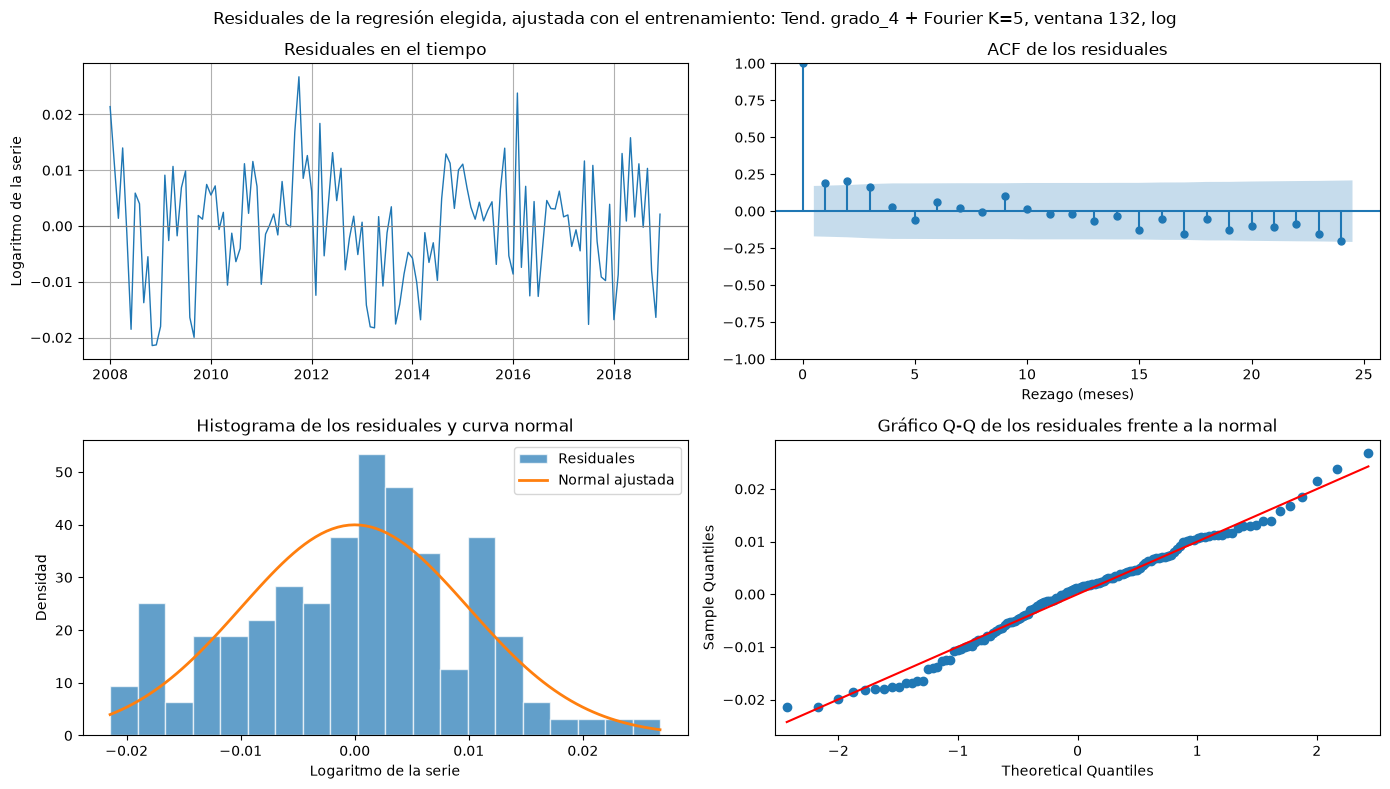

Resumen de la validación:
                                    RMSE promedio  MAPE promedio (%)  Cortes mejores que Naive estacional  Cortes mejores que Combinación ANA + regresión
Holt-Winters con Optuna                    103.63               0.85                                    6                                               5
Combinación ANA + regresión                116.47               0.92                                    3                                               0
Regresión con grilla completa              117.29               0.93                                    4                                               3
Tend. lineal + dummies, ventana 24         123.68               0.94                                    3                                               1
Naive estacional                           133.36               1.05                                    0                                               3

RMSE por corte (miles):
                   Naive 

In [20]:
# --- Supuestos de la regresión con la regla del taller anterior ---
REZAGO_MAXIMO_SUPUESTOS = 24   # dos ciclos estacionales completos
ALFA_SUPUESTOS = 0.05


def evaluar_supuestos(errores, coeficientes_arma=0, rezago_maximo=REZAGO_MAXIMO_SUPUESTOS, alfa=ALFA_SUPUESTOS):
    """Pruebas de los supuestos de unos residuales y regla de decisión del taller anterior.

    Independencia: Ljung-Box no rechaza en la mayoría de los rezagos revisados. Si los residuales son de un
    modelo ARMA, los grados de libertad se reducen en el número de coeficientes estimados (coeficientes_arma)
    y solo se revisan los rezagos mayores que ese número. Varianza constante: la misma regla con Ljung-Box
    sobre los residuales centrados al cuadrado. Normalidad: no rechazan ni Jarque-Bera ni Shapiro-Wilk.
    La prueba de rachas y la ARCH-LM se reportan como complemento.
    """
    rezagos_independencia = list(range(coeficientes_arma + 1, rezago_maximo + 1))
    rezagos_varianza = list(range(1, rezago_maximo + 1))
    centrados = errores - errores.mean()
    rechazos_independencia = int((acorr_ljungbox(errores, lags=rezagos_independencia, model_df=coeficientes_arma,
                                                 return_df=True)["lb_pvalue"] < alfa).sum())
    rechazos_varianza = int((acorr_ljungbox(centrados ** 2, lags=rezagos_varianza,
                                            return_df=True)["lb_pvalue"] < alfa).sum())
    p_jarque_bera = stats.jarque_bera(errores).pvalue
    p_shapiro_wilk = stats.shapiro(errores).pvalue

    independencia = rechazos_independencia < len(rezagos_independencia) / 2
    varianza_constante = rechazos_varianza < len(rezagos_varianza) / 2
    normalidad = p_jarque_bera >= alfa and p_shapiro_wilk >= alfa
    return {
        "Observaciones": len(errores),
        "Rachas (p-valor)": runstest_1samp(errores, cutoff=0, correction=False)[1],
        "Rechazos Ljung-Box": f"{rechazos_independencia} de {len(rezagos_independencia)}",
        "Rechazos Ljung-Box sobre cuadrados": f"{rechazos_varianza} de {len(rezagos_varianza)}",
        "ARCH-LM, 12 rezagos (p-valor)": het_arch(centrados, nlags=12, result_object=True).lmpval,
        "Jarque-Bera (p-valor)": p_jarque_bera,
        "Shapiro-Wilk (p-valor)": p_shapiro_wilk,
        "Independencia": independencia,
        "Varianza constante": varianza_constante,
        "Normalidad": normalidad,
        "Cumple los supuestos": independencia and varianza_constante and normalidad,
    }


def graficar_diagnostico(errores, titulo, unidad="Miles de personas", rezago_maximo=REZAGO_MAXIMO_SUPUESTOS):
    """Residuales en el tiempo, su ACF, su histograma con la curva normal y su gráfico Q-Q."""
    fig, axes = plt.subplots(2, 2, figsize=(14, 8))
    axes[0, 0].plot(errores, linewidth=1)
    axes[0, 0].axhline(0, color="gray", linewidth=0.8)
    axes[0, 0].set_title("Residuales en el tiempo")
    axes[0, 0].set_ylabel(unidad)
    axes[0, 0].grid()
    plot_acf(errores, lags=rezago_maximo, ax=axes[0, 1], title="ACF de los residuales")
    axes[0, 1].set_xlabel("Rezago (meses)")
    media_normal, desviacion_normal = stats.norm.fit(errores)
    valores_x = np.linspace(errores.min(), errores.max(), 100)
    axes[1, 0].hist(errores, bins=20, density=True, edgecolor="white", alpha=0.7, label="Residuales")
    axes[1, 0].plot(valores_x, stats.norm.pdf(valores_x, media_normal, desviacion_normal), color="C1",
                    linewidth=2, label="Normal ajustada")
    axes[1, 0].set_title("Histograma de los residuales y curva normal")
    axes[1, 0].set_xlabel(unidad)
    axes[1, 0].set_ylabel("Densidad")
    axes[1, 0].legend()
    sm.qqplot(errores, line="s", ax=axes[1, 1])   # recta ajustada a los cuantiles de los residuales
    axes[1, 1].set_title("Gráfico Q-Q de los residuales frente a la normal")
    fig.suptitle(titulo)
    fig.tight_layout()
    plt.show()


# Candidatos: las 10 configuraciones de la grilla con menor RMSE de validación, en ese orden. Cada una se
# ajusta con su ventana completa al final del entrenamiento, que es el modelo que se usaría en la prueba
N_CANDIDATOS_REGRESION = 10
candidatos_regresion = [configuraciones_regresion_etapa_2[numero]
                        for numero in grilla_regresion_2.index[:N_CANDIDATOS_REGRESION]]
residuales_candidatos = {describir_regresion(config): ajustar_regresion(train, config).resid
                         for config in candidatos_regresion}

# Todos los candidatos se evalúan en los mismos meses: los cubiertos por la ventana más corta entre ellos
meses_comunes = min(len(residuales) for residuales in residuales_candidatos.values())
residuales_candidatos = {nombre: residuales.iloc[-meses_comunes:] for nombre, residuales in residuales_candidatos.items()}
periodo = next(iter(residuales_candidatos.values())).index
print(f"Residuales por candidato: {meses_comunes}, de {periodo[0]:%Y-%m} a {periodo[-1]:%Y-%m}")

tabla_supuestos_regresion = pd.DataFrame([
    {"Candidato": f"{posicion}. {nombre}", "RMSE promedio": grilla_regresion_2["RMSE promedio"].iloc[posicion - 1],
     **evaluar_supuestos(residuales)}
    for posicion, (nombre, residuales) in enumerate(residuales_candidatos.items(), start=1)
]).set_index("Candidato")
print("\nSupuestos de los candidatos, en orden de RMSE de validación:")
print(tabla_supuestos_regresion.map(lambda v: round(v, 3) if isinstance(v, float) else v).T.to_string())

# Elección: el primer candidato que cumple los tres supuestos; si ninguno, el de menor RMSE
posicion_elegida = next((posicion for posicion, cumple in enumerate(tabla_supuestos_regresion["Cumple los supuestos"])
                         if cumple), None)
REGRESION_CUMPLE_SUPUESTOS = posicion_elegida is not None
config_regresion_elegida = candidatos_regresion[posicion_elegida if REGRESION_CUMPLE_SUPUESTOS else 0]
nombre_regresion_elegida = describir_regresion(config_regresion_elegida)
print(f"\nModelo de regresión elegido: {nombre_regresion_elegida} "
      f"({'cumple los supuestos' if REGRESION_CUMPLE_SUPUESTOS else 'ningún candidato cumple los supuestos'})")

graficar_diagnostico(residuales_candidatos[nombre_regresion_elegida],
                     f"Residuales de la regresión elegida, ajustada con el entrenamiento: {nombre_regresion_elegida}",
                     unidad="Logaritmo de la serie" if config_regresion_elegida["escala"] == "log" else "Miles de personas")

# Registro de la regresión elegida y comparación con los modelos de referencia
nombre_regresion_grilla = "Regresión con grilla completa"
registrar_configuracion(nombre_regresion_grilla, "Regresión", crear_pronostico_regresion, config_regresion_elegida)
modelos_comparacion_regresion = ["Naive estacional", nombre_regresion, nombre_combinacion, nombre_hw_optuna,
                                 nombre_regresion_grilla]
print("Resumen de la validación:")
print(resumir_validacion(modelos_comparacion_regresion, referencias=("Naive estacional", nombre_combinacion))
      .round(2).to_string())
print("\nRMSE por corte (miles):")
print(error_por_corte(modelos_comparacion_regresion).round(1).to_string())

### Resultados de los supuestos y elección del modelo de regresión

| Candidato, en orden de RMSE | RMSE de validación (miles) | Rechazos Ljung-Box (de 24) | Rechazos Ljung-Box sobre cuadrados (de 24) | Jarque-Bera / Shapiro-Wilk (p-valor) | Cumple los supuestos |
|---|---|---|---|---|---|
| 1. Grado 5 + dummies, ventana 168 | 110.99 | 15 | 0 | 0.748 / 0.333 | No |
| 2. Grado 5 + Fourier $K=5$, ventana 168 | 112.84 | 14 | 0 | 0.791 / 0.382 | No |
| 3. Grado 4 + dummies, ventana 132, log | 115.63 | 12 | 1 | 0.757 / 0.399 | No |
| 4. Grado 4 + dummies, ventana 132 | 116.18 | 16 | 0 | 0.691 / 0.336 | No |
| 5. Grado 5 + dummies, ventana 168, log | 117.08 | 14 | 1 | 0.922 / 0.394 | No |
| **6. Grado 4 + Fourier $K=5$, ventana 132, log** | **117.29** | **11** | **0** | **0.697 / 0.194** | **Sí** |
| 7. Grado 4 + Fourier $K=5$, ventana 132 | 117.47 | 14 | 0 | 0.678 / 0.393 | No |
| 8. Grado 4 + dummies, ventana 144, log | 119.37 | 15 | 0 | 0.941 / 0.653 | No |
| 9. Grado 5 + Fourier $K=5$, ventana 168, log | 119.50 | 10 | 0 | 0.930 / 0.239 | Sí |
| 10. Grado 4 + dummies, ventana 144 | 119.87 | 16 | 0 | 0.765 / 0.557 | No |

*Pruebas sobre los residuales de enero de 2008 a diciembre de 2018 (132 meses), con un nivel de 0.05.*

Los residuales de los 10 candidatos se evaluaron en los mismos 132 meses, los que cubre la ventana más corta entre ellos. Todos cumplen la varianza constante, porque la prueba de Ljung-Box sobre los residuales al cuadrado rechaza a lo sumo en 1 de los 24 rezagos, y la normalidad, porque ni Jarque-Bera ni Shapiro-Wilk la rechazan. La diferencia entre ellos está en la independencia: la prueba de Ljung-Box rechaza la ausencia de autocorrelación en 10 a 16 de los 24 rezagos, y solo los candidatos 6 y 9 quedan por debajo de la mitad.

Según la regla, se elige el primero que cumple los tres supuestos, el candidato 6: **tendencia de grado 4 y 5 pares de términos de Fourier, estimada con los últimos 132 meses y en escala logarítmica**,

$$\log y_t = \beta_0 + \sum_{k=1}^{4} \beta_k t^k + \sum_{j=1}^{5} \left[ a_j \sin\left(\frac{2\pi j\, m_t}{12}\right) + b_j \cos\left(\frac{2\pi j\, m_t}{12}\right) \right] + \varepsilon_t,$$

donde $t$ es el tiempo en años y $m_t$ el número del mes. El pronóstico se devuelve a miles de personas con la exponencial. Su RMSE de validación, 117.29 mil personas, es 6.30 mil mayor que el del candidato con menor error, y queda apenas por encima del de la combinación del taller anterior (116.47 mil); supera al naive estacional en 4 de los 6 cortes.

El cumplimiento de la independencia es estrecho por dos razones. Primero, el candidato elegido rechaza en 11 de 24 rezagos, y el candidato 3, con 12 rechazos, no la cumple por un solo rezago. Segundo, los residuales provienen del mismo ajuste que estimó los coeficientes: un polinomio de grado 4 estimado sobre esos 132 meses se curva para seguir sus oscilaciones lentas, de modo que absorbe parte de la autocorrelación que tendrían sus errores al pronosticar meses que no usó. En la gráfica «Residuales de la regresión elegida, ajustada con el entrenamiento: Tend. grado_4 + Fourier K=5, ventana 132, log», la ACF tiene todavía autocorrelaciones cercanas a 0.2 en los rezagos 1 a 3, en el límite de la banda de significancia, y cercanas a -0.2 hacia el rezago 24. Los residuales se mantienen entre -2 % y 2.5 % del nivel de la serie, sin periodos con una variabilidad claramente mayor, y el gráfico Q-Q sigue la recta normal. La dependencia entre meses consecutivos que queda en los residuales es precisamente la que modelan los modelos ARIMA de las secciones siguientes.

### Sensibilidad de la regresión elegida

La regresión elegida combina una ventana larga, de 132 meses, con una tendencia polinómica de grado 4. Con esa ventana, el modelo incluye el crecimiento hasta 2015 y el aplanamiento posterior, y el polinomio se curva para seguir los dos tramos; su pronóstico depende, por lo tanto, de cómo continúa esa curva después del último mes observado, y la extrapolación de un polinomio de grado alto puede cambiar mucho con pequeños cambios en los datos. Además, los candidatos salieron de 1,152 configuraciones evaluadas con solo 6 cortes, todos en el periodo en que la serie ya no crecía, de modo que su RMSE de validación puede ser optimista.

Para dimensionar este riesgo se revisan dos cosas: cómo cambia el error de validación con la ventana, con la estacionalidad y la escala de la regresión elegida y con tendencias de distinto grado, y cómo se comporta la tendencia estimada en cada corte cuando se prolonga a los 6 meses validados. Como referencia, la segunda gráfica incluye la tendencia de la descomposición clásica de la sección 2, que se calcula con promedios móviles centrados sobre todo el entrenamiento y solo sirve para describir la serie.

RMSE promedio de validación por ventana, con Fourier K=5 y escala logarítmica (miles):
tendencia  lineal  grado_4  grado_5
Ventana                            
24         124.90   699.14  4314.01
36         159.58   290.41   334.72
48         200.30   251.32   298.09
60         239.81   233.63   277.28
72         296.67   189.80   280.74
96         452.78   157.89   218.95
120        567.17   124.04   153.69
132        585.97   117.29   139.23
144        591.38   121.43   144.41
156        573.70   137.55   130.14
168        559.79   174.65   119.49
Recursiva  544.59   232.30   126.03


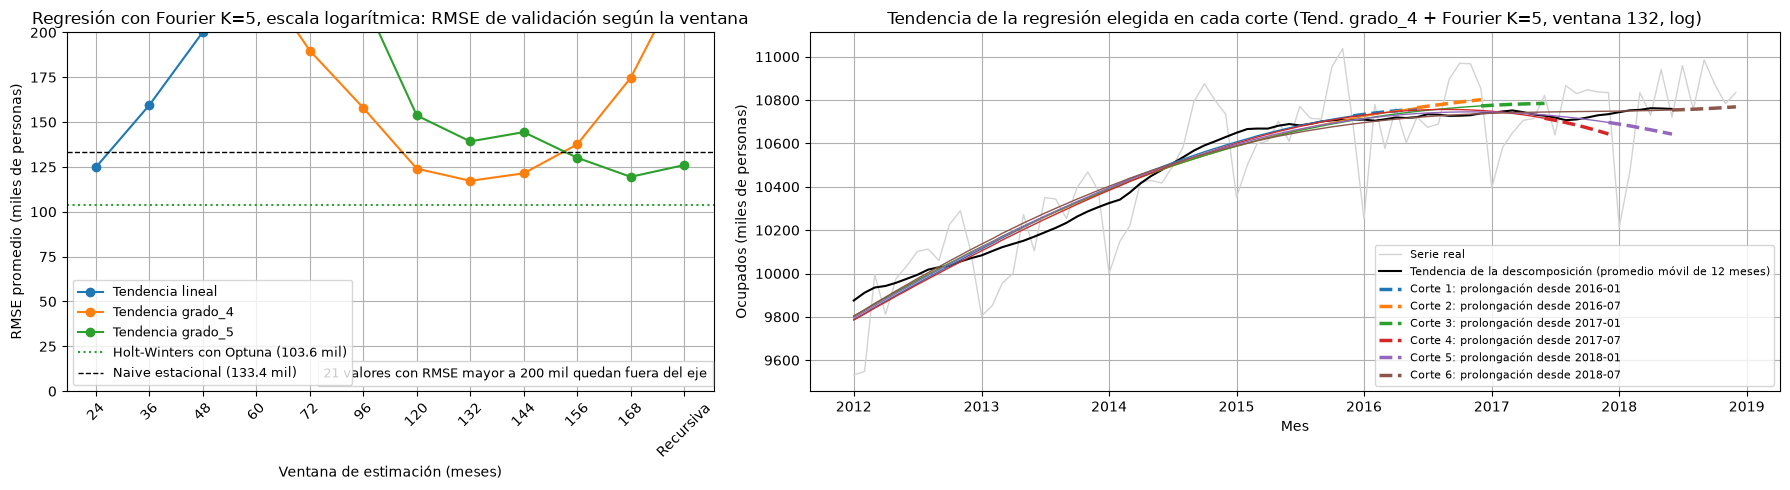

In [21]:
# --- Sensibilidad de la regresión elegida a la ventana y comportamiento de su tendencia ---
def tendencia_regresion(serie_ajuste, config, h):
    """Tendencia estimada por una regresión en su ventana de ajuste y prolongada h meses.

    Es el polinomio en el tiempo más el efecto estacional promedio del año (con las dummies, enero es la
    categoría base; con Fourier, el efecto promedio es cero), en miles de personas.
    """
    ajuste = ajustar_regresion(serie_ajuste, config)
    serie_ventana = serie_ajuste if config["ventana"] is None else serie_ajuste.iloc[-config["ventana"]:]
    fechas = serie_ventana.index.append(fechas_siguientes(serie_ajuste, h))
    X_tendencia = construir_regresores(fechas, config["tendencia"])          # constante y potencias de t
    parametros = ajuste.params
    efecto_estacional_medio = parametros[parametros.index.str.startswith("mes_")].sum() / 12
    tendencia = X_tendencia.to_numpy() @ parametros[X_tendencia.columns].to_numpy() + efecto_estacional_medio
    return pd.Series(np.exp(tendencia) if config["escala"] == "log" else tendencia, index=fechas)


# 1. RMSE promedio de validación por ventana con la estacionalidad y la escala de la regresión elegida,
#    para la tendencia lineal, la de la regresión elegida y la de grado 5
grilla_regresion_2["Ventana"] = grilla_regresion_2.index.map(
    lambda numero: "Recursiva" if configuraciones_regresion_etapa_2[numero]["ventana"] is None
    else str(configuraciones_regresion_etapa_2[numero]["ventana"]))
misma_estructura = np.array([
    all(configuraciones_regresion_etapa_2[numero][clave] == config_regresion_elegida[clave]
        for clave in ("estacionalidad", "K", "escala"))
    for numero in grilla_regresion_2.index])
grados_sensibilidad = list(dict.fromkeys(["lineal", config_regresion_elegida["tendencia"], "grado_5"]))
sensibilidad_ventana = (grilla_regresion_2[misma_estructura & grilla_regresion_2["tendencia"].isin(grados_sensibilidad)]
                        .pivot_table(index="Ventana", columns="tendencia", values="RMSE promedio")
                        .reindex(index=orden_ventanas, columns=grados_sensibilidad))
estructura_elegida = "dummies" if config_regresion_elegida["K"] is None else f"Fourier K={config_regresion_elegida['K']}"
escala_elegida = "logarítmica" if config_regresion_elegida["escala"] == "log" else "original"
print(f"RMSE promedio de validación por ventana, con {estructura_elegida} y escala {escala_elegida} (miles):")
print(sensibilidad_ventana.round(2).to_string())

fig, axes = plt.subplots(1, 2, figsize=(18, 5), gridspec_kw={"width_ratios": [2, 3]})

for tendencia in grados_sensibilidad:
    axes[0].plot(sensibilidad_ventana.index, sensibilidad_ventana[tendencia], marker="o", label=f"Tendencia {tendencia}")
axes[0].axhline(validacion[nombre_hw_optuna]["rmse"].mean(), color="C2", linestyle=":", linewidth=1.5,
                label=f"{nombre_hw_optuna} ({validacion[nombre_hw_optuna]['rmse'].mean():.1f} mil)")
axes[0].axhline(validacion["Naive estacional"]["rmse"].mean(), color="black", linestyle="--", linewidth=1,
                label=f"Naive estacional ({validacion['Naive estacional']['rmse'].mean():.1f} mil)")
# El eje va de 0 a 1.5 veces el RMSE del naive estacional; los valores mayores se cuentan en una nota
limite_rmse = 1.5 * validacion["Naive estacional"]["rmse"].mean()
fuera_del_eje = int((sensibilidad_ventana > limite_rmse).sum().sum())
axes[0].set_ylim(0, limite_rmse)
if fuera_del_eje:
    axes[0].text(0.99, 0.03, f"{fuera_del_eje} {'valor' if fuera_del_eje == 1 else 'valores'} con RMSE mayor a "
                 f"{limite_rmse:.0f} mil {'queda' if fuera_del_eje == 1 else 'quedan'} fuera del eje",
                 transform=axes[0].transAxes, ha="right", va="bottom", fontsize=9,
                 bbox=dict(facecolor="white", edgecolor="lightgray"))
axes[0].set_title(f"Regresión con {estructura_elegida}, escala {escala_elegida}: RMSE de validación según la ventana")
axes[0].set_xlabel("Ventana de estimación (meses)")
axes[0].set_ylabel("RMSE promedio (miles de personas)")
axes[0].tick_params(axis="x", rotation=45)
axes[0].legend(loc="lower left", fontsize=9)
axes[0].grid()

# 2. Tendencia de la regresión elegida en cada corte: tramo ajustado (línea continua) y prolongación (discontinua)
axes[1].plot(train.loc["2012":], color="lightgray", linewidth=1, label="Serie real")
axes[1].plot(desc_aditiva.trend.loc["2012":], color="black", linewidth=1.5,
             label="Tendencia de la descomposición (promedio móvil de 12 meses)")
for numero, (idx_ajuste, _) in enumerate(tscv.split(train), start=1):
    serie_ajuste = train.iloc[idx_ajuste]
    tendencia = tendencia_regresion(serie_ajuste, config_regresion_elegida, horizonte)
    color = f"C{numero - 1}"
    axes[1].plot(tendencia.loc["2012":serie_ajuste.index[-1]], color=color, linewidth=1)
    axes[1].plot(tendencia.loc[serie_ajuste.index[-1]:], color=color, linewidth=2.5, linestyle="--",
                 label=f"Corte {numero}: prolongación desde {serie_ajuste.index[-1] + pd.DateOffset(months=1):%Y-%m}")
axes[1].set_title(f"Tendencia de la regresión elegida en cada corte ({describir_regresion(config_regresion_elegida)})")
axes[1].set_xlabel("Mes")
axes[1].set_ylabel("Ocupados (miles de personas)")
axes[1].legend(loc="lower right", fontsize=8)
axes[1].grid()

fig.tight_layout()
plt.show()

### Lectura de la sensibilidad

| Ventana (meses) | Tendencia lineal | Tendencia de grado 4 | Tendencia de grado 5 |
|---|---|---|---|
| 24 | **124.90** | 699.14 | 4,314.01 |
| 96 | 452.78 | 157.89 | 218.95 |
| 120 | 567.17 | 124.04 | 153.69 |
| 132 | 585.97 | **117.29** | 139.23 |
| 144 | 591.38 | 121.43 | 144.41 |
| 156 | 573.70 | 137.55 | 130.14 |
| 168 | 559.79 | 174.65 | **119.49** |
| Recursiva | 544.59 | 232.30 | 126.03 |

*RMSE promedio de validación en miles de personas, con 5 pares de términos de Fourier y escala logarítmica. En negrilla, la mejor ventana de cada grado.*

La tabla y la gráfica «Regresión con Fourier K=5, escala logarítmica: RMSE de validación según la ventana» muestran que el grado de la tendencia y la ventana no se pueden elegir por separado: cada grado tiene su propia ventana óptima, que se alarga a medida que el grado aumenta, de 24 meses con la tendencia lineal a 132 meses con grado 4 y 168 meses con grado 5. Una recta solo describe bien los últimos dos años, en los que la serie ya no crecía; un polinomio de grado más alto necesita más historia para estimar su curvatura, y solo con la ventana adecuada esa curvatura termina aplanándose en el último tramo. Con grado 4, el mínimo es más estable que con grado 5: las ventanas de 120 y 144 meses tienen errores de 124.04 y 121.43 mil, 4 a 7 mil mayores que con 132 meses, mientras que con grado 5 el error sube de 119.49 mil con 168 meses a 130.14 mil con 156 meses.

En la gráfica «Tendencia de la regresión elegida en cada corte (Tend. grado_4 + Fourier K=5, ventana 132, log)», el polinomio de cada corte sigue de cerca la tendencia de la descomposición en el tramo ajustado, pero su prolongación cambia de dirección de un corte a otro. En los cortes de 2016 y de enero de 2017, la tendencia prolongada sigue subiendo por encima de la de la descomposición; en los cortes de julio de 2017 y enero de 2018, se curva hacia abajo y queda por debajo de ella. La curvatura en el extremo del polinomio depende de los últimos meses de cada ventana, y su prolongación amplifica esas diferencias: es el riesgo propio de extrapolar un polinomio de grado alto.

La regresión elegida se conserva, porque así lo indica la regla de elección fijada antes de ver los resultados, con esta reserva: su pronóstico depende de cómo se curva el polinomio en el último tramo de la ventana. La muestra de prueba, y en la Parte 2 la evaluación con muchos orígenes, incluidos los años en que la serie todavía crecía, permitirán comprobar si su desempeño se mantiene.

### Promedio móvil

En el taller anterior se evaluaron ventanas de 2, 3, 4, 6 y 12 meses. Aquí se evalúan todas las ventanas de 2 a 48 meses, es decir, hasta 4 años de historia; con $k = 1$, el promedio móvil es igual al naive. Esta familia no modela la tendencia ni la estacionalidad, pero se mantiene en la comparación porque forma parte de los modelos que deben evaluarse en las dos partes del trabajo, y la ventana elegida aquí es la que la representa.

Mejores ventanas:
    RMSE promedio  MAPE promedio (%)  Cortes mejores que Naive estacional
k                                                                        
25         171.51               1.29                                    0
26         173.31               1.29                                    0
24         173.64               1.31                                    0
13         175.51               1.33                                    1
27         176.05               1.31                                    0

Revisión de bordes:
                Valor             Opciones En el borde
Hiperparámetro                                        
k                  25  2 a 48 (47 valores)          no


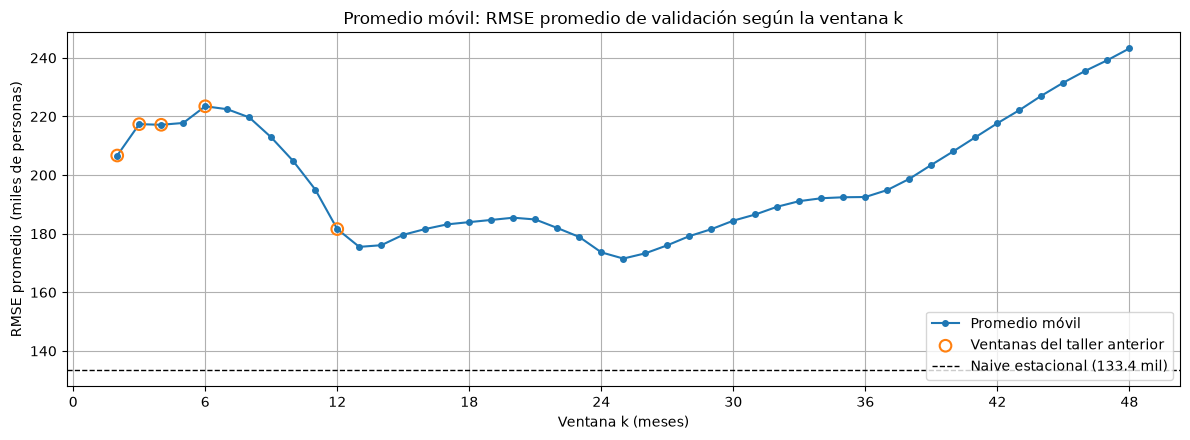

In [22]:
# --- Promedio móvil: búsqueda en grilla de la ventana k ---
VENTANAS_K = list(range(2, 49))   # de 2 meses a 4 años (k = 1 es el naive)
grilla_ma, fallidas_ma = evaluar_grilla(crear_pronostico_ma, [{"k": k} for k in VENTANAS_K])
assert not fallidas_ma
grilla_ma = grilla_ma.set_index("k").sort_index()

mejor_k = int(grilla_ma["RMSE promedio"].idxmin())
nombre_ma_grilla = f"MA k={mejor_k}"
if nombre_ma_grilla not in validacion:   # si el mejor k es uno del taller anterior, ya está registrado
    registrar_configuracion(nombre_ma_grilla, "Promedio móvil", crear_pronostico_ma, {"k": mejor_k})
print("Mejores ventanas:")
print(grilla_ma.sort_values("RMSE promedio").head(5).round(2).to_string())
print("\nRevisión de bordes:")
print(revisar_bordes_grilla({"k": mejor_k}, {"k": VENTANAS_K}).to_string())

# RMSE promedio por ventana, con las ventanas del taller anterior y el naive estacional como referencia
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(grilla_ma.index, grilla_ma["RMSE promedio"], marker="o", markersize=4, color="C0", label="Promedio móvil")
ax.scatter(ventanas_promedio_movil, grilla_ma.loc[ventanas_promedio_movil, "RMSE promedio"], s=70,
           facecolors="none", edgecolors="C1", linewidths=1.5, label="Ventanas del taller anterior", zorder=3)
ax.axhline(validacion["Naive estacional"]["rmse"].mean(), color="black", linestyle="--", linewidth=1,
           label=f"Naive estacional ({validacion['Naive estacional']['rmse'].mean():.1f} mil)")
ax.set_xticks(range(0, 49, 6))
ax.set_title("Promedio móvil: RMSE promedio de validación según la ventana k")
ax.set_xlabel("Ventana k (meses)")
ax.set_ylabel("RMSE promedio (miles de personas)")
ax.legend(loc="lower right")
ax.grid()
plt.tight_layout()
plt.show()

### Lectura del promedio móvil

La mejor ventana es de 25 meses, con un RMSE promedio de 171.51 mil personas y un MAPE de 1.29 %, y no supera al naive estacional en ninguno de los 6 cortes. La revisión de bordes no marca la ventana, que queda en el interior del rango de 2 a 48 meses.

En la gráfica «Promedio móvil: RMSE promedio de validación según la ventana k», el error tiene dos mínimos locales, cerca de $k = 13$ y $k = 25$, es decir, con ventanas de alrededor de uno y dos años completos. Con esas ventanas, el promedio incluye cada mes del año casi el mismo número de veces, de modo que el efecto estacional se compensa y el pronóstico se acerca al nivel promedio del último año o los dos últimos años; con otras ventanas, el promedio queda inclinado hacia los meses que incluye más veces. La ventana de 12 meses del taller anterior (181.58 mil) está cerca del primer mínimo. Con más de 30 meses, el error vuelve a subir, porque el promedio incluye niveles de años anteriores. Todas las ventanas quedan por encima del naive estacional (133.36 mil): un pronóstico plano no puede reproducir la caída de enero ni el aumento de fin de año. El promedio móvil de 25 meses es el representante de esta familia en las comparaciones siguientes.

### Cierre de la sección 5

| Familia | Modelo elegido en la sección | Búsqueda | RMSE promedio (miles) | MAPE promedio (%) | Cortes mejores que el naive estacional |
|---|---|---|---|---|---|
| Suavización exponencial | Holt-Winters ANA, ventana 144, parámetros elegidos por Optuna | Bayesiana | **103.63** | **0.85** | 6 |
| Combinación (taller anterior) | Holt-Winters ANA + regresión lineal con dummies, ventana 24 | — | 116.47 | 0.92 | 3 |
| Regresión | Tendencia de grado 4 + Fourier $K = 5$, ventana 132, escala logarítmica | Grilla completa y supuestos | 117.29 | 0.93 | 4 |
| Referencia | Naive estacional | — | 133.36 | 1.05 | — |
| Promedio móvil | $k = 25$ | Grilla completa | 171.51 | 1.29 | 0 |

La búsqueda más amplia mejora sobre todo a la suavización exponencial. El Holt-Winters elegido reduce el RMSE de la combinación del taller anterior en cerca de 11 % y supera al naive estacional en los 6 cortes; además, su configuración se repite con otra semilla y las ventanas vecinas tienen errores parecidos, lo que hace de él un resultado estable. En la regresión, la grilla encontró configuraciones con menor error que la regresión del taller anterior, pero la que cumple los supuestos tiene un RMSE similar al de la combinación, y su pronóstico depende de cómo se curva un polinomio de grado 4 al final de la ventana. El promedio móvil no alcanza al naive estacional con ninguna ventana.

Estos modelos, junto con los 25 del taller anterior, pasan a la comparación en la muestra de prueba de la sección 9. Antes se agregan los modelos ARIMA, que pueden modelar la dependencia entre meses consecutivos que queda en los residuales de la regresión.

## 6. Identificación de los modelos ARIMA

Los supuestos de la regresión mostraron que sus errores de pronóstico tienen autocorrelación positiva en los primeros rezagos: la serie tiene una dependencia entre meses consecutivos que una función del tiempo y del mes no captura. Un modelo ARIMA modela directamente esa dependencia, porque describe cada valor de la serie a partir de sus valores y errores anteriores. A cambio, requiere que la serie, o alguna de sus diferencias, sea estacionaria: con media y varianza constantes y una dependencia entre meses que no cambia en el tiempo. La serie de ocupados no lo es en su nivel, porque tiene tendencia y un patrón estacional. Las dos transformaciones habituales son la primera diferencia, $\Delta y_t = y_t - y_{t-1}$, que elimina la tendencia, y la diferencia estacional, $\Delta_{12}\, y_t = y_t - y_{t-12}$, que compara cada mes con el mismo mes del año anterior y elimina el patrón estacional.

Para elegir el orden de diferenciación se aplican dos pruebas complementarias a la serie de entrenamiento y a sus diferencias:

- **Dickey-Fuller aumentada (ADF):** la hipótesis nula es que la serie tiene raíz unitaria (no es estacionaria).
- **KPSS:** la hipótesis nula es que la serie es estacionaria.

La regla de decisión se fija antes de ver los resultados: una transformación se considera estacionaria si la prueba ADF rechaza la raíz unitaria y la prueba KPSS no rechaza la estacionariedad, ambas con un nivel de 0.05, y se prefiere la que lo logra con menos diferencias. Como complemento, se reportan los órdenes de diferenciación que sugieren las pruebas automáticas de pmdarima, incluidas dos pruebas de raíz unitaria estacional. Las pruebas dan indicios y no una conclusión definitiva, porque el cambio de tendencia de 2016 puede afectarlas; por eso, los órdenes no se fijan aquí, sino que se usan para acotar el espacio de búsqueda de la sección siguiente, donde la validación decide.

Pruebas de estacionariedad sobre el entrenamiento:
                              Observaciones ADF p-valor KPSS p-valor ADF rechaza raíz unitaria KPSS no rechaza estacionariedad Estacionaria según la regla
Nivel (y)                               216      0.6822       0.0100                     False                           False                       False
Primera diferencia (Δy)                 215      0.0098       0.1000                      True                            True                        True
Diferencia estacional (Δ12 y)           204      0.4995       0.0959                     False                            True                       False
Ambas diferencias (Δ Δ12 y)             203      0.0000       0.1000                      True                            True                        True

Órdenes de diferenciación sugeridos por pmdarima:
  d (ADF):  1  |  d (KPSS): 1
  D (OCSB): 0  |  D (Canova-Hansen): 0


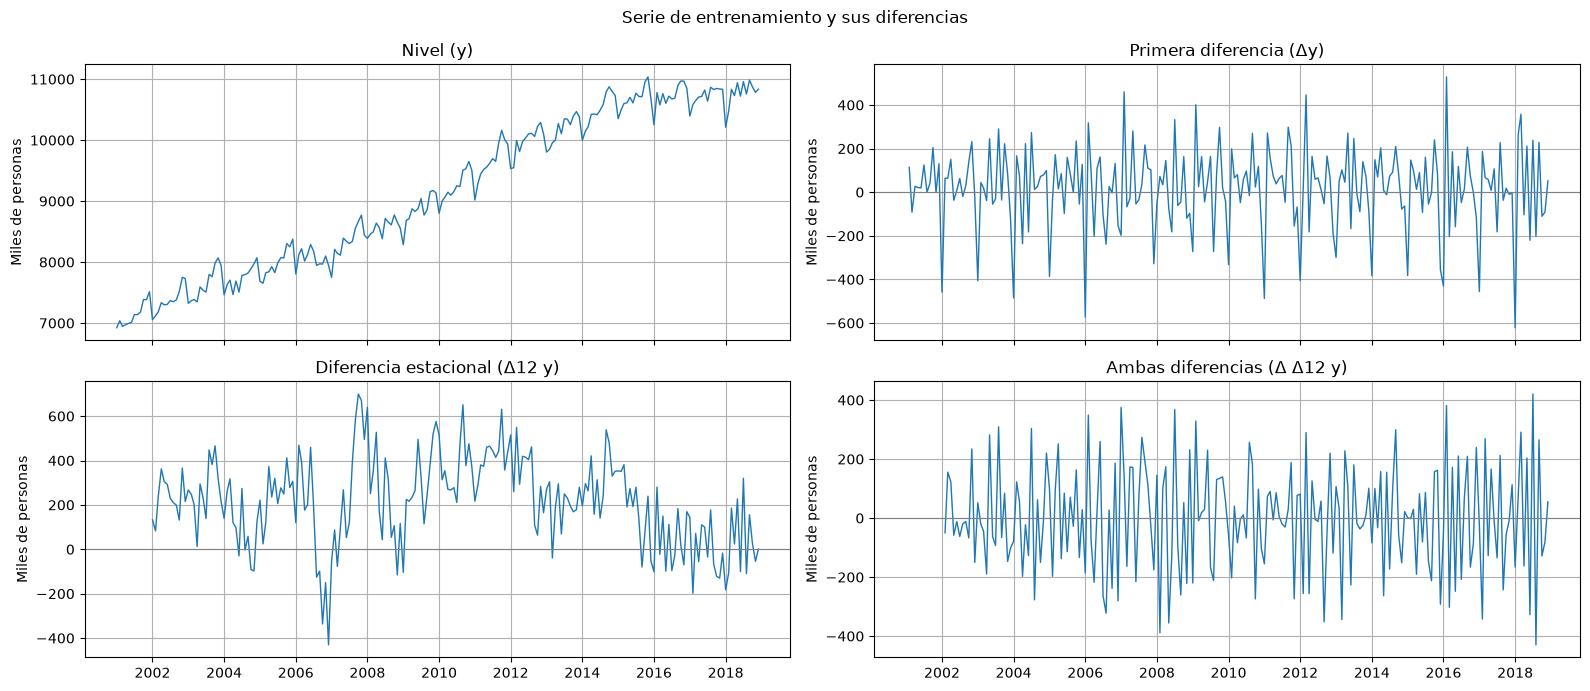

In [23]:
# Serie de entrenamiento y sus diferencias (se eliminan los valores iniciales que la diferencia deja vacíos)
transformaciones = {
    "Nivel (y)": train,
    "Primera diferencia (Δy)": train.diff().dropna(),
    "Diferencia estacional (Δ12 y)": train.diff(12).dropna(),
    "Ambas diferencias (Δ Δ12 y)": train.diff(12).diff().dropna(),
}


def pruebas_estacionariedad(serie, alfa=0.05):
    """Pruebas ADF (H0: raíz unitaria) y KPSS (H0: estacionariedad) con la regla de decisión de la sección.

    KPSS solo tabula p-valores entre 0.01 y 0.10: fuera de ese rango devuelve el extremo y emite un
    aviso, que se silencia porque la decisión con un nivel de 0.05 no cambia. result_object=False
    mantiene el resultado como tupla, que es el comportamiento actual de statsmodels.
    """
    p_adf = adfuller(serie, regression="c", autolag="AIC", result_object=False)[1]
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", InterpolationWarning)
        p_kpss = kpss(serie, regression="c", nlags="auto", result_object=False)[1]
    return {
        "Observaciones": len(serie),
        "ADF p-valor": p_adf,
        "KPSS p-valor": p_kpss,
        "ADF rechaza raíz unitaria": p_adf < alfa,
        "KPSS no rechaza estacionariedad": p_kpss >= alfa,
        "Estacionaria según la regla": (p_adf < alfa) and (p_kpss >= alfa),
    }


tabla_estacionariedad = pd.DataFrame({nombre: pruebas_estacionariedad(serie)
                                      for nombre, serie in transformaciones.items()}).T
print("Pruebas de estacionariedad sobre el entrenamiento:")
print(tabla_estacionariedad.to_string(formatters={"ADF p-valor": "{:.4f}".format, "KPSS p-valor": "{:.4f}".format}))

# Órdenes sugeridos por pmdarima: d con ADF y KPSS, y D con las pruebas estacionales OCSB y Canova-Hansen
print("\nÓrdenes de diferenciación sugeridos por pmdarima:")
print(f"  d (ADF):  {ndiffs(train, test='adf')}  |  d (KPSS): {ndiffs(train, test='kpss')}")
print(f"  D (OCSB): {nsdiffs(train, m=12, test='ocsb')}  |  D (Canova-Hansen): {nsdiffs(train, m=12, test='ch')}")

# Gráfica de la serie y de sus tres diferencias
fig, axes = plt.subplots(2, 2, figsize=(16, 7), sharex=True)
for ax, (nombre, serie) in zip(axes.flat, transformaciones.items()):
    ax.plot(serie, linewidth=1)
    if nombre != "Nivel (y)":
        ax.axhline(0, color="gray", linewidth=0.8)
    ax.set_title(nombre)
    ax.set_ylabel("Miles de personas")
    ax.grid()
fig.suptitle("Serie de entrenamiento y sus diferencias")
fig.tight_layout()
plt.show()

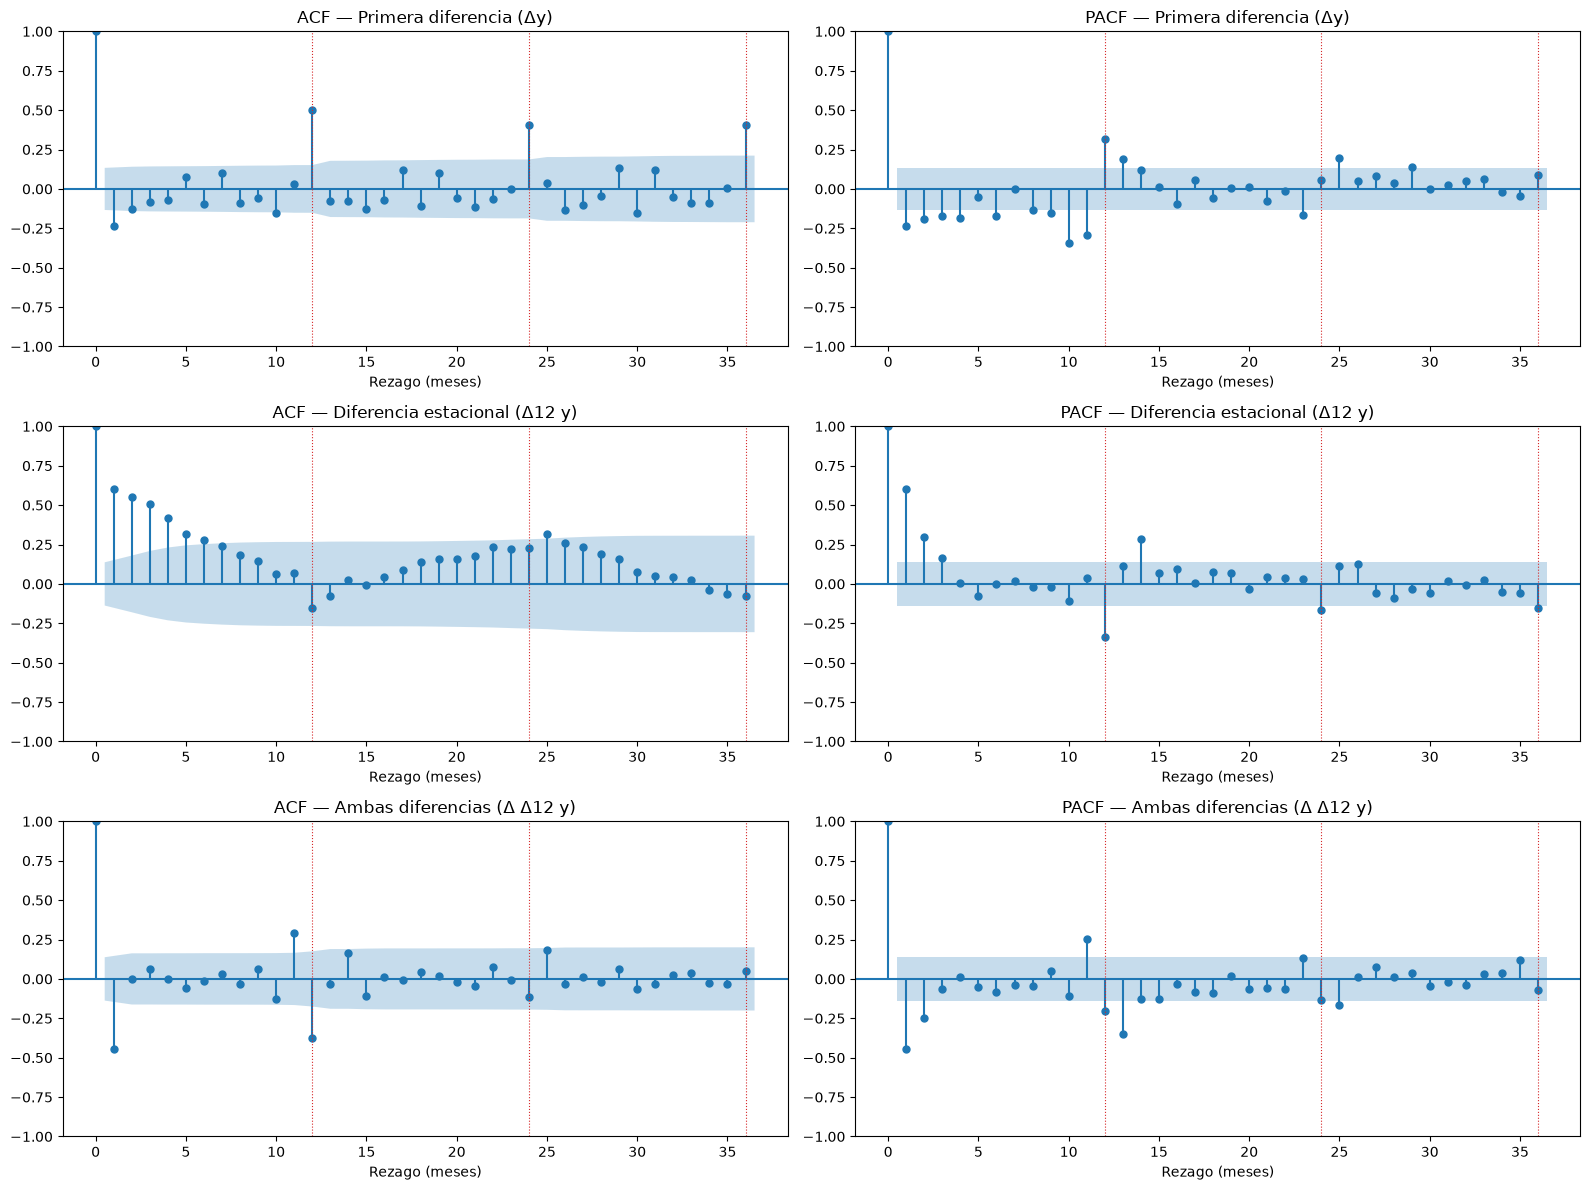

Banda aproximada de la PACF: ±0.134

Autocorrelaciones en los rezagos clave:
          Primera diferencia (Δy)        Diferencia estacional (Δ12 y)        Ambas diferencias (Δ Δ12 y)       
                              ACF   PACF                           ACF   PACF                         ACF   PACF
Rezago 1                   -0.232 -0.232                         0.599  0.599                      -0.444 -0.444
Rezago 2                   -0.124 -0.189                         0.550  0.297                      -0.003 -0.249
Rezago 3                   -0.081 -0.175                         0.506  0.165                       0.062 -0.066
Rezago 6                   -0.095 -0.171                         0.281 -0.003                      -0.011 -0.084
Rezago 11                   0.034 -0.290                         0.071  0.040                       0.291  0.251
Rezago 12                   0.499  0.319                        -0.153 -0.336                      -0.372 -0.204
Rezago 13          

In [24]:
# ACF y PACF de las tres diferencias, hasta 36 rezagos (3 años). El nivel no se incluye porque
# no es estacionario, y su ACF quedaría dominada por la tendencia.
diferencias = ["Primera diferencia (Δy)", "Diferencia estacional (Δ12 y)", "Ambas diferencias (Δ Δ12 y)"]
rezagos_clave = [1, 2, 3, 6, 11, 12, 13, 24, 36]

fig, axes = plt.subplots(len(diferencias), 2, figsize=(16, 4 * len(diferencias)))
valores_autocorrelacion = {}
for fila, nombre in enumerate(diferencias):
    serie = transformaciones[nombre]
    plot_acf(serie, lags=36, ax=axes[fila, 0], title=f"ACF — {nombre}")
    plot_pacf(serie, lags=36, ax=axes[fila, 1], method="ywm", title=f"PACF — {nombre}")
    for ax in axes[fila]:
        ax.set_xlabel("Rezago (meses)")
        for rezago_estacional in (12, 24, 36):
            ax.axvline(rezago_estacional, color="C3", linestyle=":", linewidth=0.8)
    valores_autocorrelacion[(nombre, "ACF")] = acf(serie, nlags=36)[rezagos_clave]
    valores_autocorrelacion[(nombre, "PACF")] = pacf(serie, nlags=36, method="ywm")[rezagos_clave]
fig.tight_layout()
plt.show()

# Banda aproximada de significancia al 95 % para la PACF (la de la ACF se ensancha con el rezago)
print(f"Banda aproximada de la PACF: ±{1.96 / np.sqrt(len(transformaciones[diferencias[0]])):.3f}")
print("\nAutocorrelaciones en los rezagos clave:")
print(pd.DataFrame(valores_autocorrelacion, index=[f"Rezago {r}" for r in rezagos_clave]).round(3).to_string())

### Lectura de la identificación

**Orden de diferenciación no estacional ($d$).** La serie en niveles no es estacionaria: la prueba ADF no rechaza la raíz unitaria (p-valor de 0.68) y la KPSS rechaza la estacionariedad (p-valor de 0.01 o menor). Con una primera diferencia, las dos pruebas coinciden en que la serie es estacionaria (p-valores de 0.0098 en ADF y de 0.10 o más en KPSS), y las dos pruebas de pmdarima sugieren $d = 1$. La diferencia estacional por sí sola no basta: la prueba ADF no rechaza la raíz unitaria (p-valor de 0.50); en la gráfica «ACF — Diferencia estacional (Δ12 y)», la autocorrelación baja lentamente desde 0.60 en el rezago 1; y en el panel «Diferencia estacional (Δ12 y)» de la gráfica «Serie de entrenamiento y sus diferencias», la serie diferenciada cambia de nivel, con valores altos entre 2008 y 2012 y cercanos a cero desde 2016, el mismo cambio de régimen de la sección 2. Por eso, los modelos usarán una primera diferencia ($d = 1$).

**Orden de diferenciación estacional ($D$).** Aquí la evidencia no es concluyente. Las pruebas estacionales de pmdarima (OCSB y Canova-Hansen) sugieren $D = 0$, es decir, un patrón estacional estable que no requiere diferenciación. Sin embargo, en la gráfica «ACF — Primera diferencia (Δy)», las autocorrelaciones en los rezagos estacionales son altas y casi no decaen: 0.50 en el rezago 12, 0.41 en el 24 y 0.41 en el 36. Esa persistencia puede representarse de dos formas: con $D = 0$ y términos autorregresivos estacionales, o con $D = 1$. Como las dos opciones son razonables, $D$ no se fija aquí, y entra en la búsqueda con los valores 0 y 1.

**Órdenes ARMA.** Con ambas diferencias, que es la transformación con menos autocorrelación remanente, la gráfica «ACF — Ambas diferencias (Δ Δ12 y)» tiene dos valores claramente significativos: -0.44 en el rezago 1 y -0.37 en el rezago 12, con un valor de 0.29 en el rezago 11 que acompaña al del rezago 12. La gráfica «PACF — Ambas diferencias (Δ Δ12 y)», en cambio, decae: -0.44 y -0.25 en los rezagos 1 y 2, y -0.35 en el rezago 13. Una ACF que se corta en los rezagos 1 y 12 junto con una PACF que decae es el patrón de un componente MA(1) no estacional y un MA(1) estacional, es decir, un $\text{SARIMA}(0,1,1)(0,1,1)_{12}$. Con la primera diferencia sola, la gráfica «PACF — Primera diferencia (Δy)» tiene valores significativos en varios rezagos de corto plazo y en el rezago 12, coherente con términos autorregresivos de bajo orden y un AR estacional.

En resumen, la identificación sugiere $d = 1$, deja abierto $D$ entre 0 y 1, y apunta a órdenes ARMA bajos: hasta 2 o 3 en la parte no estacional y hasta 1 o 2 en la estacional. Estos indicios acotan el espacio de búsqueda de la sección siguiente, en la que la validación decide entre las alternativas.

## 7. ARIMA y SARIMA

Un modelo $\text{SARIMA}(p,d,q)(P,D,Q)_{12}$ combina una parte no estacional, con $p$ términos autorregresivos y $q$ de media móvil sobre la serie con $d$ diferencias, y una parte estacional, con $P$ y $Q$ términos que relacionan cada mes con el mismo mes de años anteriores, después de $D$ diferencias estacionales. Cuando $P = D = Q = 0$, el modelo es un ARIMA sin componente estacional.

La especificación se elige de dos formas. Primero, con el procedimiento automático `auto_arima`, que elige los órdenes con un criterio de información calculado dentro de la muestra. Después, con optimización bayesiana, que elige los órdenes, la escala y la ventana de estimación con el mismo criterio que las demás familias: el error de pronóstico a 6 meses en los cortes de validación. Comparar los dos resultados permite ver si el criterio con el que se elige el modelo cambia su desempeño.

### Selección automática con `auto_arima`

`auto_arima`, de pmdarima, elige el orden de diferenciación $d$ con la prueba KPSS y el estacional $D$ con la prueba OCSB. Luego recorre los órdenes de forma escalonada: parte de un modelo inicial y prueba cambios de una unidad en cada orden hasta encontrar el de menor AIC (criterio de información de Akaike), que mide qué tan bien se ajusta el modelo dentro de la muestra penalizando el número de coeficientes. Se usan sus valores por defecto: órdenes no estacionales hasta 5 y estacionales hasta 2, y una constante que solo puede incluirse cuando $d + D < 2$ y que la búsqueda decide si conserva. Se cambian dos valores: el periodo estacional se fija en 12 meses, porque por defecto el modelo no tiene parte estacional, y el número máximo de iteraciones del optimizador se fija en 500 en lugar de 50, como en la búsqueda con Optuna.

Primero se aplica con todo el entrenamiento, para ver el modelo que elige y sus coeficientes. Después se evalúa el mismo procedimiento en los 6 cortes de validación: en cada corte, `auto_arima` vuelve a elegir el modelo solo con los datos disponibles hasta ese corte, con toda la historia y en escala original, y se registra la especificación elegida en cada uno.

In [25]:
# --- auto_arima: selección automática de un SARIMA por criterio de información ---
ESTACIONALIDAD_SARIMA = 12
MAX_ITERACIONES_SARIMA = 500    # statsmodels y pmdarima usan 50 por defecto, que no alcanzan con términos estacionales
CONFIG_AUTO_ARIMA = {"m": ESTACIONALIDAD_SARIMA, "criterio": "aic"}


def ajustar_auto_arima(serie_ajuste, config):
    """Elige y estima un SARIMA con auto_arima: d con la prueba KPSS, D con la prueba OCSB y los órdenes
    por búsqueda escalonada con el criterio de información indicado. Los demás valores son los de pmdarima."""
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        return auto_arima(serie_ajuste, seasonal=True, m=config["m"], information_criterion=config["criterio"],
                          maxiter=MAX_ITERACIONES_SARIMA, error_action="ignore", suppress_warnings=True)


def describir_auto_arima(modelo):
    """Especificación elegida por auto_arima, por ejemplo "SARIMA(2,1,0)(1,0,1)12 con constante"."""
    (p, d, q), (P, D, Q, m) = modelo.order, modelo.seasonal_order
    return f"SARIMA({p},{d},{q})({P},{D},{Q}){m}" + (" con constante" if modelo.with_intercept else "")


def crear_pronostico_auto_arima(config):
    """Función de pronóstico que, en cada corte, elige un SARIMA con auto_arima y pronostica con él.

    El modelo elegido en el corte se guarda en los atributos del pronóstico, para registrarlo con las métricas.
    """
    def pronostico(serie_ajuste, h):
        modelo = ajustar_auto_arima(serie_ajuste, config)
        salida = pd.Series(np.asarray(modelo.predict(n_periods=h), dtype=float))
        salida.attrs["Modelo elegido"] = describir_auto_arima(modelo)
        return salida

    return pronostico


# 1. Modelo que auto_arima elige con todo el entrenamiento
modelo_auto_arima = ajustar_auto_arima(train, CONFIG_AUTO_ARIMA)
print(f"Modelo elegido con todo el entrenamiento: {describir_auto_arima(modelo_auto_arima)}\n")
print(modelo_auto_arima.summary())

# 2. El mismo procedimiento en los 6 cortes de validación: en cada corte, auto_arima vuelve a elegir el modelo
#    solo con los datos disponibles hasta ese corte
PROCESOS_POR_MODELO["crear_pronostico_auto_arima"] = N_PROCESOS
nombre_auto_arima = "auto_arima (SARIMA elegido por AIC en cada corte)"
registrar_configuracion(nombre_auto_arima, "ARIMA", crear_pronostico_auto_arima, CONFIG_AUTO_ARIMA)
print("\nModelo elegido y error en cada corte:")
print(validacion[nombre_auto_arima].round(2).to_string())

modelos_comparacion_auto_arima = ["Naive estacional", nombre_combinacion, nombre_hw_optuna, nombre_auto_arima]
print("\nResumen de la validación:")
print(resumir_validacion(modelos_comparacion_auto_arima, referencias=("Naive estacional", nombre_combinacion))
      .round(2).to_string())

Modelo elegido con todo el entrenamiento: SARIMA(2,1,0)(1,0,1)12 con constante

                                      SARIMAX Results                                       
Dep. Variable:                                    y   No. Observations:                  216
Model:             SARIMAX(2, 1, 0)x(1, 0, [1], 12)   Log Likelihood               -1350.561
Date:                              Mon, 23 Nov 2026   AIC                           2713.123
Time:                                      16:05:02   BIC                           2733.347
Sample:                                  01-01-2001   HQIC                          2721.294
                                       - 12-01-2018                                         
Covariance Type:                                opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept      0.2

### Lectura de `auto_arima`

Con todo el entrenamiento, `auto_arima` elige un $\text{SARIMA}(2,1,0)(1,0,1)_{12}$ con constante. Sus órdenes de diferenciación coinciden con la identificación de la sección 6 ($d = 1$ y $D = 0$), y sus dos coeficientes autorregresivos no estacionales (-0.50 y -0.23) son significativos. El coeficiente autorregresivo estacional es de 0.99, prácticamente 1: el efecto de cada mes se repite casi igual de un año al siguiente, lo que equivale en la práctica a una diferencia estacional, y confirma que la persistencia de los rezagos 12, 24 y 36 de la sección 6 podía representarse de las dos formas. La constante no es significativa (p-valor de 0.627).

En los 6 cortes de validación, `auto_arima` elige la misma especificación. Su RMSE promedio, 141.64 mil personas, y su MAPE, 1.19 %, son mayores que los del naive estacional (133.36 mil y 1.05 %), aunque lo supera en 4 de los 6 cortes; el promedio sube por los cortes de julio de 2017 y julio de 2018, con errores de 190.7 y 166.6 mil. Frente a la combinación del taller anterior, tiene menor error solo en 2 de los 6 cortes. El AIC elige el modelo que mejor se ajusta dentro de la muestra a un paso, penalizando el número de coeficientes, y no el que mejor pronostica 6 meses fuera de ella, que es el objetivo de este trabajo. La optimización bayesiana de la subsección siguiente elige la especificación con ese segundo criterio.

### Optimización bayesiana de la especificación

Aquí la optimización bayesiana elige la especificación del modelo (los órdenes, la escala y la ventana), y los coeficientes de cada especificación se estiman por máxima verosimilitud en cada corte. El espacio de búsqueda se define a partir de la identificación de la sección anterior:

| Hiperparámetro | Valores | Justificación |
|---|---|---|
| $d$ | 1 (fijo) | Las pruebas ADF y KPSS coinciden en que basta una primera diferencia |
| $D$ | 0 o 1 | Las pruebas estacionales sugieren 0, pero la ACF de la primera diferencia muestra una estacionalidad muy persistente |
| $p$, $q$ | 0 a 3 | La ACF y la PACF de la serie diferenciada sugieren órdenes no estacionales de 1 a 2; se agrega un orden más para revisar el borde |
| $P$, $Q$ | 0 a 2 | Autocorrelaciones significativas en los rezagos 12 y 24 |
| Término determinístico | sin constante o con deriva, solo si $D = 0$ | Con $d = 1$, una constante equivale a una tendencia lineal en el nivel. Con $D = 1$ se omite, porque implicaría una tendencia cuadrática |
| Escala | original o logarítmica | Versión aditiva o multiplicativa de la estacionalidad: en escala logarítmica, los efectos estacionales son proporcionales al nivel, y los rasgos de la sección 2 no permiten descartar ninguna de las dos |
| Ventana de estimación | 48, 60, 72, 96, 120, 144 o 168 meses, o recursiva | Las ventanas de la suavización exponencial y la regresión desde 48 meses: con diferenciación estacional y términos estacionales de orden 2, las ventanas de 24 y 36 meses dejan muy pocas observaciones efectivas para estimar los coeficientes |

Los coeficientes se restringen a la región estacionaria e invertible y se estiman con el optimizador L-BFGS; si este no converge, se intenta con Powell, que no usa gradientes y es más estable cuando la verosimilitud es muy plana. Si ninguno converge en algún corte, el intento se descarta. En escala logarítmica, el pronóstico se devuelve a miles de personas con la exponencial, que corresponde a la mediana del pronóstico; con errores cercanos al 1 %, la diferencia con la media es despreciable. Como el espacio tiene unas 9,000 combinaciones, se usan 300 intentos, como en la suavización exponencial, y la revisión de bordes indica si hace falta una segunda etapa.

Intentos: 300 | completos: 293 | fallidos: 7 | repetidos (resultado reutilizado): 107
Cortes leídos del caché: 1116 de 1116 (configuraciones completas distintas)
Tiempo total: 0.0 min | por intento evaluado: 0.01 s
Motivos de los intentos fallidos:
LinAlgError: LU decomposition error.    7
Mejor RMSE promedio: 122.52 (intento 22)

Mejores intentos:
         p  d  q  P  D  Q    escala  ventana tendencia  RMSE promedio  MAPE promedio (%)  Cortes mejores que Naive estacional
Intento                                                                                                                      
22       2  1  3  2  0  0       log     72.0         n        122.516              0.968                                    4
99       3  1  0  2  0  0  original     96.0         n        123.950              0.996                                    4
33       0  1  3  2  0  0       log     72.0         n        123.979              0.974                                    4
52       0  1  3  2

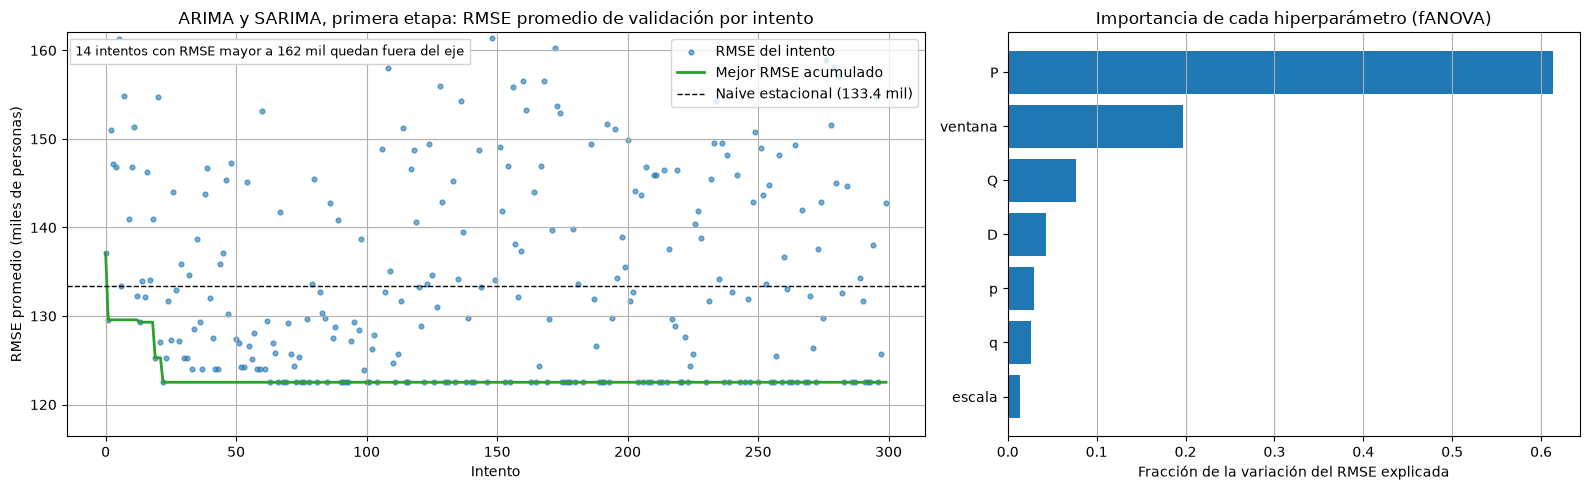


Revisión de bordes del mejor intento:
               Valor                                  Rango En el borde
Hiperparámetro                                                         
p                  2                                 [0, 3]          no
q                  3                                 [0, 3]    superior
P                  2                                 [0, 2]    superior
D                  0                                 [0, 1]   no aplica
Q                  0                                 [0, 2]          no
escala           log                    ['original', 'log']   no aplica
ventana           72  [48, 60, 72, 96, 120, 144, 168, None]          no
tendencia          n                             ['n', 'c']   no aplica
Configuraciones distintas evaluadas: 193 | fallidas: 7
                          Evaluadas  Fallidas  % fallidas
Hiperparámetro Valor                                     
D              0                122         7         5.7
            

In [26]:
# --- ARIMA y SARIMA con optimización bayesiana de la especificación ---
# Ventanas de estimación: las de la suavización exponencial y la regresión desde 48 meses (con términos
# estacionales, 24 y 36 meses dejan muy pocas observaciones efectivas); None = ventana recursiva
VENTANAS_SARIMA = [48, 60, 72, 96, 120, 144, 168, None]
# Si L-BFGS no converge en MAX_ITERACIONES_SARIMA iteraciones (por ejemplo, cuando la verosimilitud es muy
# plana cerca del borde de la región invertible), se intenta con Powell, que no usa gradientes. Así, un
# fallo indica un problema de la especificación y no del optimizador.
OPTIMIZADORES_SARIMA = ("lbfgs", "powell")


def espacio_sarima(max_p=3, max_q=3, max_P=2, max_Q=2):
    """Devuelve la función que define el espacio de búsqueda de ARIMA y SARIMA con los órdenes máximos
    indicados. Los valores por defecto son los de la primera etapa, acotados con la sección 6."""
    def sugerir_configuracion_sarima(trial):
        config = {
            "p": trial.suggest_int("p", 0, max_p),
            "d": 1,
            "q": trial.suggest_int("q", 0, max_q),
            "P": trial.suggest_int("P", 0, max_P),
            "D": trial.suggest_int("D", 0, 1),
            "Q": trial.suggest_int("Q", 0, max_Q),
            "escala": trial.suggest_categorical("escala", ["original", "log"]),
            "ventana": trial.suggest_categorical("ventana", VENTANAS_SARIMA),
        }
        # Con D = 1 no se incluye término determinístico; con D = 0 se elige entre sin constante y con deriva
        config["tendencia"] = trial.suggest_categorical("tendencia", ["n", "c"]) if config["D"] == 0 else "n"
        return config

    return sugerir_configuracion_sarima


def ordenes_sarima(config):
    """Órdenes no estacional y estacional de SARIMAX; si no hay parte estacional, el modelo es un ARIMA."""
    orden_estacional = (config["P"], config["D"], config["Q"], ESTACIONALIDAD_SARIMA)
    if orden_estacional[:3] == (0, 0, 0):
        orden_estacional = (0, 0, 0, 0)
    return (config["p"], config["d"], config["q"]), orden_estacional


def ajustar_sarima(serie_ajuste, config):
    """Estima por máxima verosimilitud un SARIMA con la configuración indicada.

    Respeta la ventana de estimación y la escala de la configuración. Prueba los optimizadores de
    OPTIMIZADORES_SARIMA en orden y devuelve el primer ajuste que converge; si ninguno converge,
    lanza un error. Los avisos de statsmodels durante la estimación se silencian, porque la
    convergencia se revisa aquí.
    """
    if config["ventana"] is not None:
        serie_ajuste = serie_ajuste.iloc[-config["ventana"]:]
    y = np.log(serie_ajuste) if config["escala"] == "log" else serie_ajuste
    orden, orden_estacional = ordenes_sarima(config)
    modelo = SARIMAX(y, order=orden, seasonal_order=orden_estacional, trend=config["tendencia"],
                     enforce_stationarity=True, enforce_invertibility=True)
    for optimizador in OPTIMIZADORES_SARIMA:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            ajuste = modelo.fit(disp=False, method=optimizador, maxiter=MAX_ITERACIONES_SARIMA)
        if ajuste.mle_retvals.get("converged", False):
            return ajuste
    raise RuntimeError("la estimación por máxima verosimilitud no convergió con ningún optimizador")


def crear_pronostico_sarima(config):
    """Función de pronóstico de una configuración SARIMA, en miles de personas."""
    def pronostico(serie_ajuste, h):
        prediccion = np.asarray(ajustar_sarima(serie_ajuste, config).forecast(h))
        # En escala logarítmica, la exponencial devuelve el pronóstico a miles de personas
        return np.exp(prediccion) if config["escala"] == "log" else prediccion

    return pronostico


# Argumentos de la revisión de bordes de SARIMA: los órdenes pueden valer 0, que es su mínimo
# posible, y D solo admite 0 o 1, de modo que en él no hay borde que ampliar
BORDES_SARIMA = dict(categoricos_ordenados=("ventana",), minimos_naturales=("p", "q", "P", "Q"),
                     sin_ampliacion=("D",))

# Primera etapa de la optimización bayesiana de ARIMA y SARIMA
N_INTENTOS_SARIMA = 300
estudio_sarima = optimizar(espacio_sarima(), crear_pronostico_sarima, N_INTENTOS_SARIMA)

print("\nMejores intentos:")
print(resumir_estudio(estudio_sarima).round(3).to_string())

graficar_estudio(estudio_sarima, "ARIMA y SARIMA, primera etapa")

print("\nRevisión de bordes del mejor intento:")
print(revisar_bordes(estudio_sarima, **BORDES_SARIMA).to_string())


def diagnosticar_fallos(estudio, hiperparametros=("D", "escala", "p", "q", "P", "Q", "ventana")):
    """Proporción de configuraciones distintas que no se pudieron estimar, según cada hiperparámetro.

    Si los fallos se concentran en ciertos valores, la búsqueda explora menos esa parte del espacio,
    y conviene tenerlo en cuenta al leer el resultado. Devuelve la tabla con un bloque por hiperparámetro.
    """
    intentos = pd.DataFrame([
        {**t.params, "Falló": "error" in t.user_attrs}
        for t in estudio.trials if not t.user_attrs.get("repetido")
    ])
    # La ventana recursiva se guarda como None; se convierte a texto para poder agruparla
    intentos["ventana"] = ["recursiva" if pd.isna(ventana) else str(int(ventana)) for ventana in intentos["ventana"]]
    tabla = pd.concat({
        hiperparametro: intentos.groupby(hiperparametro)["Falló"].agg(Evaluadas="size", Fallidas="sum")
        for hiperparametro in hiperparametros
    }, names=["Hiperparámetro", "Valor"])
    tabla["% fallidas"] = 100 * tabla["Fallidas"] / tabla["Evaluadas"]
    print(f"Configuraciones distintas evaluadas: {len(intentos)} | fallidas: {intentos['Falló'].sum()}")
    return tabla


print(diagnosticar_fallos(estudio_sarima).round(1).to_string())

### Lectura de la primera etapa

De los 300 intentos, 193 corresponden a configuraciones distintas, y los demás repiten configuraciones ya evaluadas, porque el espacio es discreto y el algoritmo vuelve a proponer las de menor error. Solo 7 configuraciones fallaron, todas por un error numérico de la estimación (una descomposición LU) y no por falta de convergencia; los fallos se concentran en la ventana recursiva (16.7 % de sus configuraciones) y en la escala original (8.2 %), pero con tan pocos ninguna región del espacio quedó sin explorar.

El mejor intento es un $\text{SARIMA}(2,1,3)(2,0,0)_{12}$ en escala logarítmica, sin término determinístico y estimado con los últimos 72 meses, con un RMSE promedio de 122.52 mil personas y un MAPE de 0.97 %. Supera al naive estacional en 4 de los 6 cortes y reduce el error de `auto_arima` en 19.1 mil personas, aunque sigue por encima de la combinación del taller anterior (116.47 mil) y del Holt-Winters elegido (103.63 mil). Hay que tener en cuenta que la comparación con `auto_arima` no es del todo pareja: `auto_arima` es un solo procedimiento con toda la historia y en escala original, mientras que el mejor intento de Optuna se eligió entre 193 configuraciones con los mismos 6 cortes, por lo que su RMSE es probablemente algo optimista. En la gráfica «ARIMA y SARIMA, primera etapa: RMSE promedio de validación por intento», el mejor RMSE acumulado llega a 122.5 mil cerca del intento 22 y no cambia después, y el algoritmo vuelve muchas veces a configuraciones cercanas.

Los 10 mejores intentos comparten la estructura estacional: todos tienen $D = 0$, dos términos autorregresivos estacionales ($P = 2$), ningún término de media móvil estacional ($Q = 0$) y ningún término determinístico, y 9 de los 10 usan la escala logarítmica. Que ninguno incluya constante es coherente con el cambio de tendencia: con $d = 1$, una constante extendería una pendiente promedio que incluye el crecimiento anterior a 2016. En la gráfica de importancia (fANOVA), $P$ explica cerca del 60 % de la variación del error entre intentos y la ventana cerca del 20 %; la mitad de los 10 mejores usa la ventana de 72 meses.

La revisión de bordes muestra que $q$ y $P$ quedaron en el límite superior de su rango. Por eso, la búsqueda se repite en una segunda etapa que amplía los órdenes no estacionales $p$ y $q$ hasta 5 y el autorregresivo estacional $P$ hasta 3; $Q$ conserva su rango, porque no quedó en el borde. La segunda etapa empieza evaluando los 10 mejores intentos de la primera y usa 300 intentos. Órdenes más altos dan más flexibilidad al modelo y, con ella, más riesgo de ajustarse a las particularidades de los 6 cortes, de modo que una mejora pequeña frente a la primera etapa no justificaría por sí sola un modelo con muchos más coeficientes.

Intentos: 300 | completos: 292 | fallidos: 8 | repetidos (resultado reutilizado): 103
Cortes leídos del caché: 1134 de 1134 (configuraciones completas distintas)
Tiempo total: 0.0 min | por intento evaluado: 0.01 s
Motivos de los intentos fallidos:
LinAlgError: LU decomposition error.    8
Mejor RMSE promedio: 120.11 (intento 75)

Mejores intentos:
         p  d  q  P  D  Q    escala  ventana tendencia  RMSE promedio  MAPE promedio (%)  Cortes mejores que Naive estacional
Intento                                                                                                                      
75       0  1  5  2  0  0       log     72.0         n        120.109              0.915                                    4
107      1  1  5  2  0  0       log     72.0         n        121.880              0.932                                    4
94       2  1  5  2  0  0       log     72.0         n        122.352              0.947                                    4
0        2  1  3  2

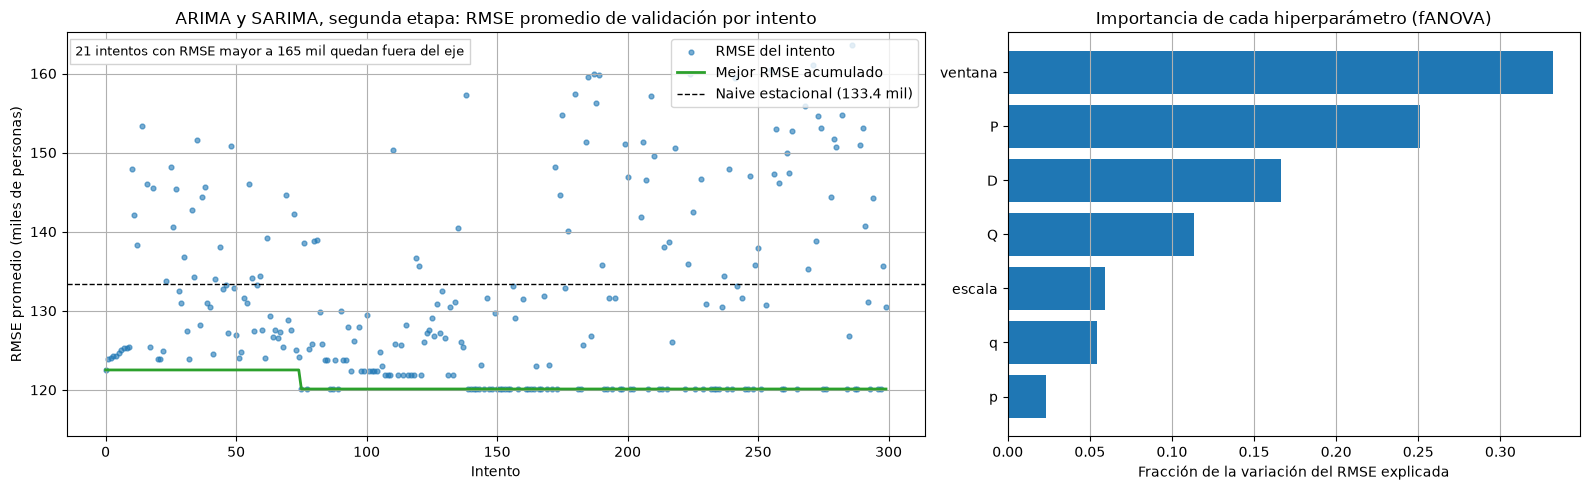


Revisión de bordes del mejor intento:
               Valor                                  Rango En el borde
Hiperparámetro                                                         
p                  0                                 [0, 5]          no
q                  5                                 [0, 5]    superior
P                  2                                 [0, 3]          no
D                  0                                 [0, 1]   no aplica
Q                  0                                 [0, 2]          no
escala           log                    ['original', 'log']   no aplica
ventana           72  [48, 60, 72, 96, 120, 144, 168, None]          no
tendencia          n                             ['n', 'c']   no aplica

Diagnóstico de los intentos fallidos:
Configuraciones distintas evaluadas: 197 | fallidas: 8
                          Evaluadas  Fallidas  % fallidas
Hiperparámetro Valor                                     
D              0               

In [27]:
# --- Segunda etapa de ARIMA y SARIMA: órdenes no estacionales hasta 5 y autorregresivo estacional hasta 3 ---
# Empieza evaluando los 10 mejores intentos de la primera etapa (se leen del caché)
N_INTENTOS_SARIMA_ETAPA_2 = 300
estudio_sarima_2 = optimizar(espacio_sarima(max_p=5, max_q=5, max_P=3), crear_pronostico_sarima,
                             N_INTENTOS_SARIMA_ETAPA_2, intentos_iniciales=mejores_intentos(estudio_sarima))
assert estudio_sarima_2.best_value <= estudio_sarima.best_value + 1e-9, \
    "la segunda etapa no puede terminar peor que la primera, porque parte de sus mejores intentos"

print("\nMejores intentos:")
print(resumir_estudio(estudio_sarima_2).round(3).to_string())

graficar_estudio(estudio_sarima_2, "ARIMA y SARIMA, segunda etapa")

print("\nRevisión de bordes del mejor intento:")
print(revisar_bordes(estudio_sarima_2, **BORDES_SARIMA).to_string())

print("\nDiagnóstico de los intentos fallidos:")
print(diagnosticar_fallos(estudio_sarima_2).round(1).to_string())


def numero_coeficientes_arma(config):
    """Número de coeficientes autorregresivos y de media móvil de una configuración SARIMA."""
    return config["p"] + config["q"] + config["P"] + config["Q"]


# Mejor configuración de cada etapa
mejores_por_etapa = pd.DataFrame({
    nombre: {**estudio.best_trial.user_attrs["config"],
             "Coeficientes ARMA": numero_coeficientes_arma(estudio.best_trial.user_attrs["config"]),
             "RMSE promedio": estudio.best_value,
             "MAPE promedio (%)": np.mean(estudio.best_trial.user_attrs["mape_cortes"])}
    for nombre, estudio in [("Primera etapa", estudio_sarima), ("Segunda etapa", estudio_sarima_2)]
})
print("\nMejor intento de cada etapa:")
print(mejores_por_etapa.to_string())

### Lectura de la segunda etapa

De los 300 intentos, 197 corresponden a configuraciones distintas. Fallaron 8, por el mismo error numérico de la primera etapa, y se concentran en las configuraciones con un término de media móvil estacional ($Q = 1$, 22 % de ellas) y con ventana recursiva (14 %); con tan pocos fallos, ninguna región del espacio quedó sin explorar.

El mejor intento es un $\text{SARIMA}(0,1,5)(2,0,0)_{12}$ en escala logarítmica, sin término determinístico y estimado con los últimos 72 meses, con un RMSE promedio de 120.11 mil personas y un MAPE de 0.91 %. Reduce el error de la primera etapa en 2.41 mil personas (2 %) con el mismo número de coeficientes ARMA (7), y supera al naive estacional en 4 de los 6 cortes. En la gráfica «ARIMA y SARIMA, segunda etapa: RMSE promedio de validación por intento», el mejor RMSE acumulado parte del mejor intento de la primera etapa (122.52), baja a 120.11 cerca del intento 75 y no cambia después. Los 10 mejores intentos conservan la estructura estacional de la primera etapa ($D = 0$, $P = 2$, $Q = 0$ y sin término determinístico), y los tres mejores tienen cinco términos de media móvil no estacionales. En la gráfica de importancia (fANOVA) de esta etapa, la ventana es el hiperparámetro que más explica la variación del error, seguida de $P$ y de $D$.

La revisión de bordes muestra que $q$ volvió a quedar en el límite superior de su rango. Por eso se hace una tercera etapa que amplía $q$ hasta 8, con los demás rangos iguales, y que empieza evaluando los 10 mejores intentos de la segunda.

Intentos: 300 | completos: 300 | fallidos: 0 | repetidos (resultado reutilizado): 108
Cortes leídos del caché: 1152 de 1152 (configuraciones completas distintas)
Tiempo total: 0.0 min | por intento evaluado: 0.01 s
Mejor RMSE promedio: 118.90 (intento 166)

Mejores intentos:
         p  d  q  P  D  Q    escala  ventana tendencia  RMSE promedio  MAPE promedio (%)  Cortes mejores que Naive estacional
Intento                                                                                                                      
166      2  1  7  2  0  0       log     96.0         n        118.899              0.916                                    4
111      2  1  6  2  0  0       log     72.0         n        119.086              0.889                                    4
177      1  1  7  2  0  0       log     96.0         n        119.989              0.930                                    4
0        0  1  5  2  0  0       log     72.0         n        120.109              0.915      

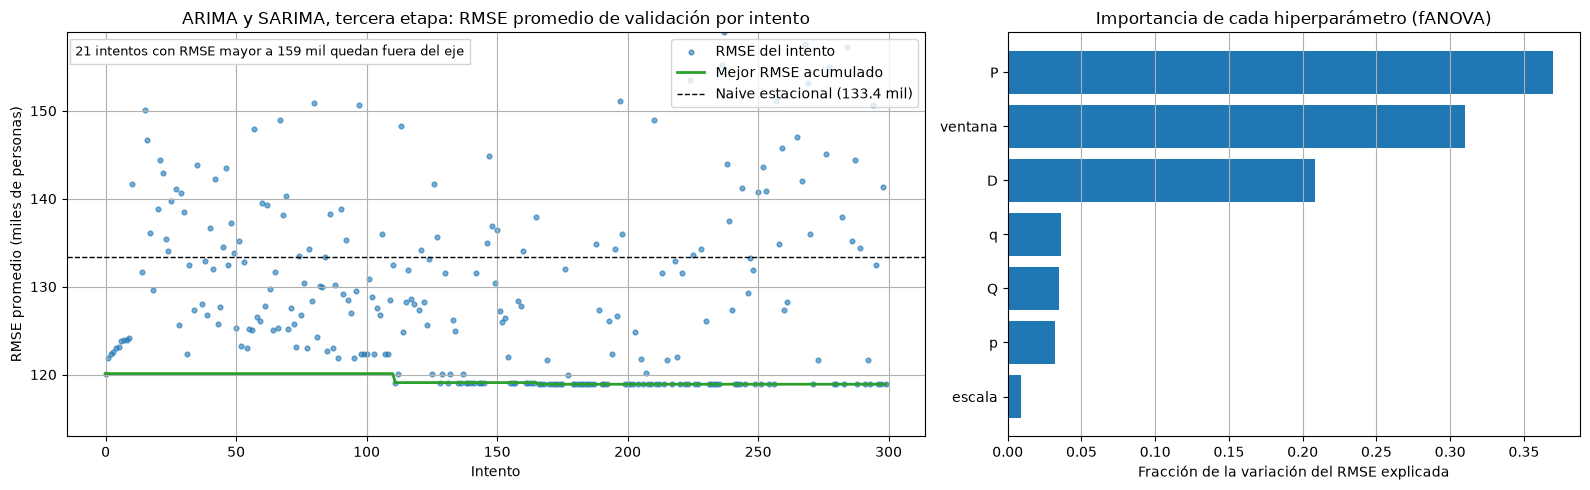


Revisión de bordes del mejor intento:
               Valor                                  Rango En el borde
Hiperparámetro                                                         
p                  2                                 [0, 5]          no
q                  7                                 [0, 8]          no
P                  2                                 [0, 3]          no
D                  0                                 [0, 1]   no aplica
Q                  0                                 [0, 2]          no
escala           log                    ['original', 'log']   no aplica
ventana           96  [48, 60, 72, 96, 120, 144, 168, None]          no
tendencia          n                             ['n', 'c']   no aplica

Diagnóstico de los intentos fallidos:
Configuraciones distintas evaluadas: 192 | fallidas: 0
                          Evaluadas  Fallidas  % fallidas
Hiperparámetro Valor                                     
D              0               

In [28]:
# --- Tercera etapa de ARIMA y SARIMA: orden de media móvil no estacional hasta 8 ---
# Empieza evaluando los 10 mejores intentos de la segunda etapa (se leen del caché)
N_INTENTOS_SARIMA_ETAPA_3 = 300
estudio_sarima_3 = optimizar(espacio_sarima(max_p=5, max_q=8, max_P=3), crear_pronostico_sarima,
                             N_INTENTOS_SARIMA_ETAPA_3, intentos_iniciales=mejores_intentos(estudio_sarima_2))
assert estudio_sarima_3.best_value <= estudio_sarima_2.best_value + 1e-9, \
    "la tercera etapa no puede terminar peor que la segunda, porque parte de sus mejores intentos"

print("\nMejores intentos:")
print(resumir_estudio(estudio_sarima_3).round(3).to_string())

graficar_estudio(estudio_sarima_3, "ARIMA y SARIMA, tercera etapa")

print("\nRevisión de bordes del mejor intento:")
print(revisar_bordes(estudio_sarima_3, **BORDES_SARIMA).to_string())

print("\nDiagnóstico de los intentos fallidos:")
print(diagnosticar_fallos(estudio_sarima_3).round(1).to_string())

# Mejor configuración de cada etapa
mejores_por_etapa = pd.DataFrame({
    nombre: {**estudio.best_trial.user_attrs["config"],
             "Coeficientes ARMA": numero_coeficientes_arma(estudio.best_trial.user_attrs["config"]),
             "RMSE promedio": estudio.best_value,
             "MAPE promedio (%)": np.mean(estudio.best_trial.user_attrs["mape_cortes"])}
    for nombre, estudio in [("Primera etapa", estudio_sarima), ("Segunda etapa", estudio_sarima_2),
                            ("Tercera etapa", estudio_sarima_3)]
})
print("\nMejor intento de cada etapa:")
print(mejores_por_etapa.to_string())

### Lectura de la tercera etapa

De los 300 intentos, 192 corresponden a configuraciones distintas, y ninguno falló. El mejor intento es un $\text{SARIMA}(2,1,7)(2,0,0)_{12}$ en escala logarítmica, sin término determinístico y estimado con los últimos 96 meses, con un RMSE promedio de 118.90 mil personas y un MAPE de 0.92 %; supera al naive estacional en 4 de los 6 cortes. En la gráfica «ARIMA y SARIMA, tercera etapa: RMSE promedio de validación por intento», el mejor RMSE acumulado parte del mejor intento de la segunda etapa (120.11), baja a cerca de 119.1 alrededor del intento 110 y a 118.9 cerca del intento 166, y no cambia después. En la gráfica de importancia (fANOVA), $P$, la ventana y $D$ explican la mayor parte de la variación del error, y los órdenes no estacionales $p$ y $q$ explican poco.

La revisión de bordes no muestra ningún hiperparámetro en el límite de su rango, así que la búsqueda termina aquí. La tabla «Mejor intento de cada etapa» resume su evolución: cada etapa redujo el RMSE en 1 a 2 %, la última a cambio de 4 coeficientes ARMA más (11 frente a 7). Los 10 mejores intentos tienen errores entre 118.9 y 122.4 mil, con la misma estructura estacional ($D = 0$, $P = 2$, $Q = 0$ y sin término determinístico), de modo que las diferencias entre ellos son pequeñas frente a la variación del error entre cortes. El modelo de la familia se elige en la sección siguiente, con la revisión de los supuestos de sus residuales.

## 8. Supuestos del mejor modelo ARIMA

El mejor modelo ARIMA se define por su RMSE de validación, y sus supuestos se revisan con la misma regla aplicada a la regresión en la sección 5: los candidatos se recorren en orden de RMSE y se elige el primero cuyos residuales cumplan los supuestos de independencia, varianza constante y normalidad; si ninguno los cumple, se conserva el de menor RMSE, y sus intervalos de predicción se construyen con sus errores de pronóstico observados. La revisión se hace en dos pasos:

- **Paso a, elección del modelo.** Los residuales de cada candidato se calculan con el modelo ajustado con su ventana al final del entrenamiento, que es el que se usaría para pronosticar la muestra de prueba. Así, la elección del modelo de la familia no usa ninguna observación de la prueba.
- **Paso b, diagnóstico con todos los datos.** El modelo elegido se ajusta con toda la serie, de enero de 2001 a junio de 2019, respetando su ventana de estimación, y se revisan sus residuales con las mismas pruebas. Es el modelo que se usaría para el pronóstico final si la familia ARIMA resulta elegida en la sección 9. Este diagnóstico se reporta, pero no cambia la elección del paso a.

Los candidatos son las configuraciones distintas de las tres etapas de la búsqueda con un RMSE de validación menor que el del naive estacional, porque un modelo que no mejora repetir los valores del año anterior no es útil para pronosticar. Por eso, el modelo de `auto_arima`, con un RMSE de 141.64 mil, no es candidato, aunque se incluye en la comparación de la sección 9.

En los residuales de un SARIMA se descartan las primeras observaciones, que la inicialización de la parte diferenciada del modelo deja sin un error de pronóstico interpretable. En la prueba de Ljung-Box, los grados de libertad se reducen en el número de coeficientes ARMA estimados ($p + q + P + Q$), y solo se revisan los rezagos mayores que ese número, hasta el 24. En los modelos en escala logarítmica, los residuales están en esa escala.

Candidatos con RMSE promedio menor que el del naive estacional (133.36): 190

Supuestos de los 10 primeros candidatos, en orden de RMSE de validación:
                                                 RMSE promedio  Observaciones  Rachas (p-valor) Rechazos Ljung-Box Rechazos Ljung-Box sobre cuadrados  ARCH-LM, 12 rezagos (p-valor)  Jarque-Bera (p-valor)  Shapiro-Wilk (p-valor)  Independencia  Varianza constante  Normalidad  Cumple los supuestos
Candidato                                                                                                                                                                                                                                                                                               
1. SARIMA(2,1,7)(2,0,0)12, log, ventana 96             118.899             95             0.244           13 de 13                           24 de 24                          0.101                  0.139                   0.148          False             

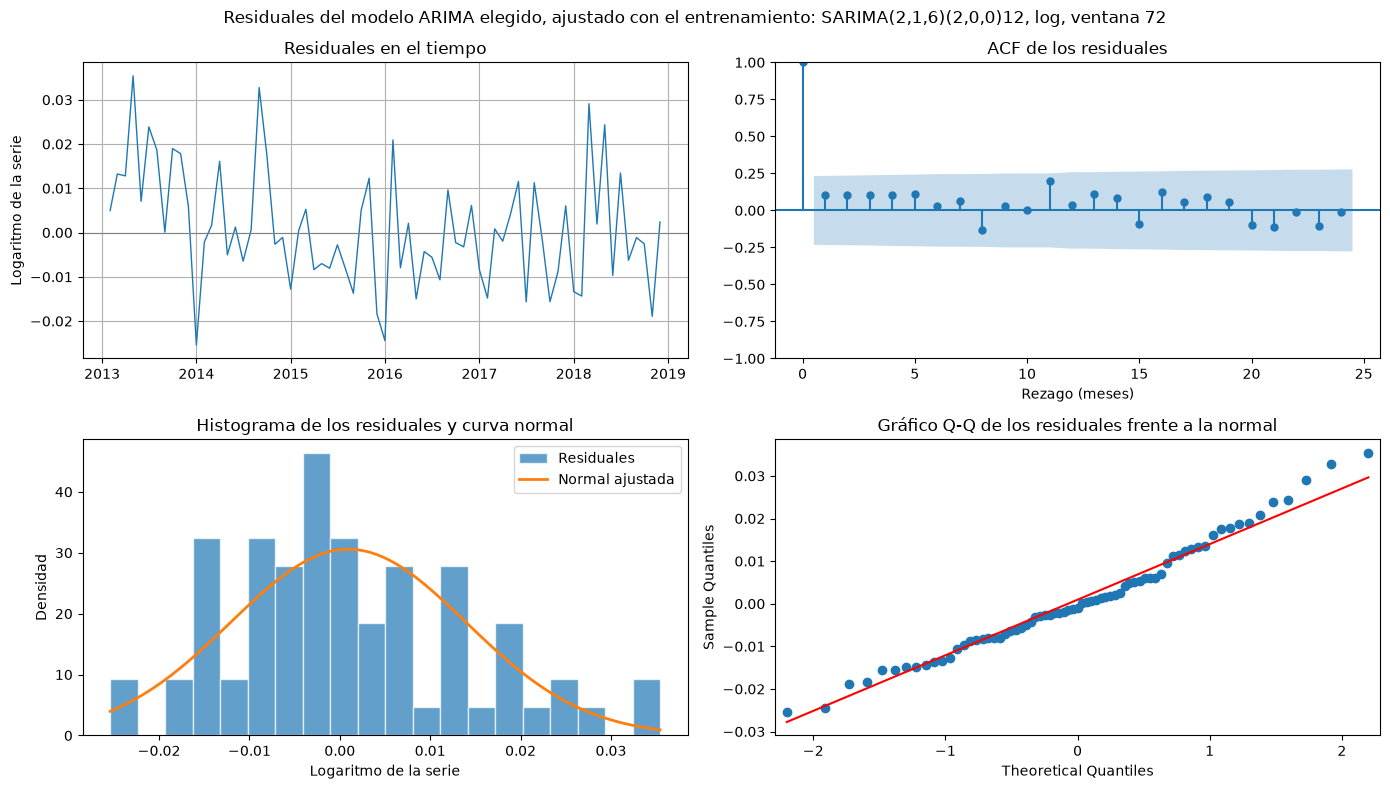

In [29]:
# --- Paso a: elección del modelo ARIMA con los supuestos de sus residuales en el entrenamiento ---
def candidatos_sarima(estudios, rmse_maximo):
    """Configuraciones distintas de los estudios con un RMSE promedio menor que rmse_maximo, en orden de RMSE."""
    candidatos = {}
    for estudio in estudios:
        for intento in estudio.trials:
            if intento.state != optuna.trial.TrialState.COMPLETE or intento.value >= rmse_maximo:
                continue
            config = intento.user_attrs["config"]
            candidatos.setdefault(tuple(sorted(config.items())), {
                "config": config, "RMSE promedio": intento.value, "rmse_cortes": intento.user_attrs["rmse_cortes"],
            })
    return sorted(candidatos.values(), key=lambda candidato: candidato["RMSE promedio"])


def describir_sarima(config):
    """Descripción corta de una configuración SARIMA: órdenes, escala, ventana y término determinístico."""
    (p, d, q), (P, D, Q, _) = ordenes_sarima(config)
    ventana = "recursiva" if config["ventana"] is None else f"ventana {config['ventana']}"
    constante = ", con deriva" if config["tendencia"] == "c" else ""
    return f"SARIMA({p},{d},{q})({P},{D},{Q})12, {config['escala']}, {ventana}{constante}"


def residuales_sarima(config, serie=train):
    """Residuales del SARIMA ajustado con su ventana al final de la serie, sin las observaciones iniciales que
    la inicialización difusa de la parte diferenciada deja sin un error interpretable (loglikelihood_burn)."""
    ajuste = ajustar_sarima(serie, config)
    return ajuste.resid.iloc[ajuste.loglikelihood_burn:]


def diagnosticar_candidato(config, serie=train):
    """Supuestos de los residuales de un candidato SARIMA ajustado con la serie indicada."""
    return evaluar_supuestos(residuales_sarima(config, serie), numero_coeficientes_arma(config))


# Candidatos: configuraciones de las tres etapas con menor RMSE que el naive estacional, en orden de RMSE
rmse_naive_estacional = validacion["Naive estacional"]["rmse"].mean()
candidatos = candidatos_sarima([estudio_sarima, estudio_sarima_2, estudio_sarima_3], rmse_naive_estacional)
print(f"Candidatos con RMSE promedio menor que el del naive estacional ({rmse_naive_estacional:.2f}): {len(candidatos)}")

# Supuestos de todos los candidatos, en paralelo; cada uno se ajusta con su ventana al final del entrenamiento
diagnosticos = Parallel(n_jobs=N_PROCESOS)(delayed(diagnosticar_candidato)(c["config"]) for c in candidatos)
tabla_supuestos_sarima = pd.DataFrame([
    {"Candidato": f"{posicion}. {describir_sarima(c['config'])}", "RMSE promedio": c["RMSE promedio"], **diagnostico}
    for posicion, (c, diagnostico) in enumerate(zip(candidatos, diagnosticos), start=1)
]).set_index("Candidato")

print("\nSupuestos de los 10 primeros candidatos, en orden de RMSE de validación:")
print(tabla_supuestos_sarima.head(10).map(lambda v: round(v, 3) if isinstance(v, float) else v).to_string())
print("\nCandidatos que cumplen cada supuesto:")
print(tabla_supuestos_sarima[["Independencia", "Varianza constante", "Normalidad", "Cumple los supuestos"]]
      .sum().astype(int).to_string())

# Elección: el primer candidato que cumple los tres supuestos; si ninguno, el de menor RMSE
posicion_elegida = next((i for i, d in enumerate(diagnosticos) if d["Cumple los supuestos"]), None)
SARIMA_CUMPLE_SUPUESTOS = posicion_elegida is not None
candidato_sarima = candidatos[posicion_elegida if SARIMA_CUMPLE_SUPUESTOS else 0]
config_sarima = candidato_sarima["config"]
if SARIMA_CUMPLE_SUPUESTOS:
    print(f"\nModelo elegido de la familia ARIMA: candidato {posicion_elegida + 1} de {len(candidatos)}, "
          f"{describir_sarima(config_sarima)} (RMSE {candidato_sarima['RMSE promedio']:.2f})")
    print(tabla_supuestos_sarima.iloc[[posicion_elegida]].map(lambda v: round(v, 3) if isinstance(v, float) else v)
          .T.to_string())
else:
    print(f"\nNingún candidato cumple los supuestos; se conserva el de menor RMSE: {describir_sarima(config_sarima)}")

graficar_diagnostico(residuales_sarima(config_sarima),
                     f"Residuales del modelo ARIMA elegido, ajustado con el entrenamiento: {describir_sarima(config_sarima)}",
                     unidad="Logaritmo de la serie" if config_sarima["escala"] == "log" else "Miles de personas")

# Registro del SARIMA elegido como modelo de la familia ARIMA
(p, d, q), (P, D, Q, _) = ordenes_sarima(config_sarima)
nombre_sarima = f"SARIMA({p},{d},{q})({P},{D},{Q})12 con Optuna"
registrar_configuracion(nombre_sarima, "ARIMA", crear_pronostico_sarima, config_sarima)
assert np.allclose(validacion[nombre_sarima]["rmse"], candidato_sarima["rmse_cortes"], rtol=1e-3), \
    "el error al reevaluar no coincide con el de la optimización"

### Lectura del paso a

De las configuraciones de las tres etapas, 190 tienen un RMSE de validación menor que el del naive estacional, y 89 de ellas cumplen los tres supuestos. Entre los 10 primeros candidatos, el patrón es claro: los que se estiman con 96 meses no cumplen la independencia ni la varianza constante, porque la prueba de Ljung-Box rechaza en todos los rezagos revisados, tanto sobre los residuales como sobre sus cuadrados, mientras que los que se estiman con 72 meses cumplen los tres supuestos.

El candidato con menor RMSE, un $\text{SARIMA}(2,1,7)(2,0,0)_{12}$ con ventana de 96 meses, no cumple los supuestos. Según la regla, se elige el candidato 2: un **$\text{SARIMA}(2,1,6)(2,0,0)_{12}$ en escala logarítmica, sin término determinístico y estimado con los últimos 72 meses**, con un RMSE de validación de 119.09 mil personas, apenas 0.19 mil más que el primero:

$$(1 - \phi_1 B - \phi_2 B^2)(1 - \Phi_1 B^{12} - \Phi_2 B^{24})(1 - B)\log y_t = (1 + \theta_1 B + \dots + \theta_6 B^6)\,\varepsilon_t,$$

donde $B$ es el operador de rezago ($B\, y_t = y_{t-1}$). En sus residuales, la prueba de Ljung-Box rechaza en 6 de los 14 rezagos revisados (del 11 al 24), menos de la mitad; la prueba sobre los cuadrados no rechaza en ninguno, y las de Jarque-Bera y Shapiro-Wilk no rechazan la normalidad (p-valores de 0.264 y 0.254). En la gráfica «Residuales del modelo ARIMA elegido, ajustado con el entrenamiento: SARIMA(2,1,6)(2,0,0)12, log, ventana 72», todas las autocorrelaciones quedan dentro de la banda de significancia, los residuales se mantienen entre -2.5 % y 3.5 % del nivel de la serie, y el gráfico Q-Q sigue la recta normal, con una cola derecha algo más larga.

                                      SARIMAX Results                                      
Dep. Variable:                            Ocupados   No. Observations:                   72
Model:             SARIMAX(2, 1, 6)x(2, 0, [], 12)   Log Likelihood                 210.232
Date:                             Mon, 23 Nov 2026   AIC                           -398.464
Time:                                     16:05:23   BIC                           -373.574
Sample:                                 07-01-2013   HQIC                          -388.566
                                      - 06-01-2019                                         
Covariance Type:                               opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.2073      2.719      0.076      0.939      -5.122       5.536
ar.L2          0.2963      

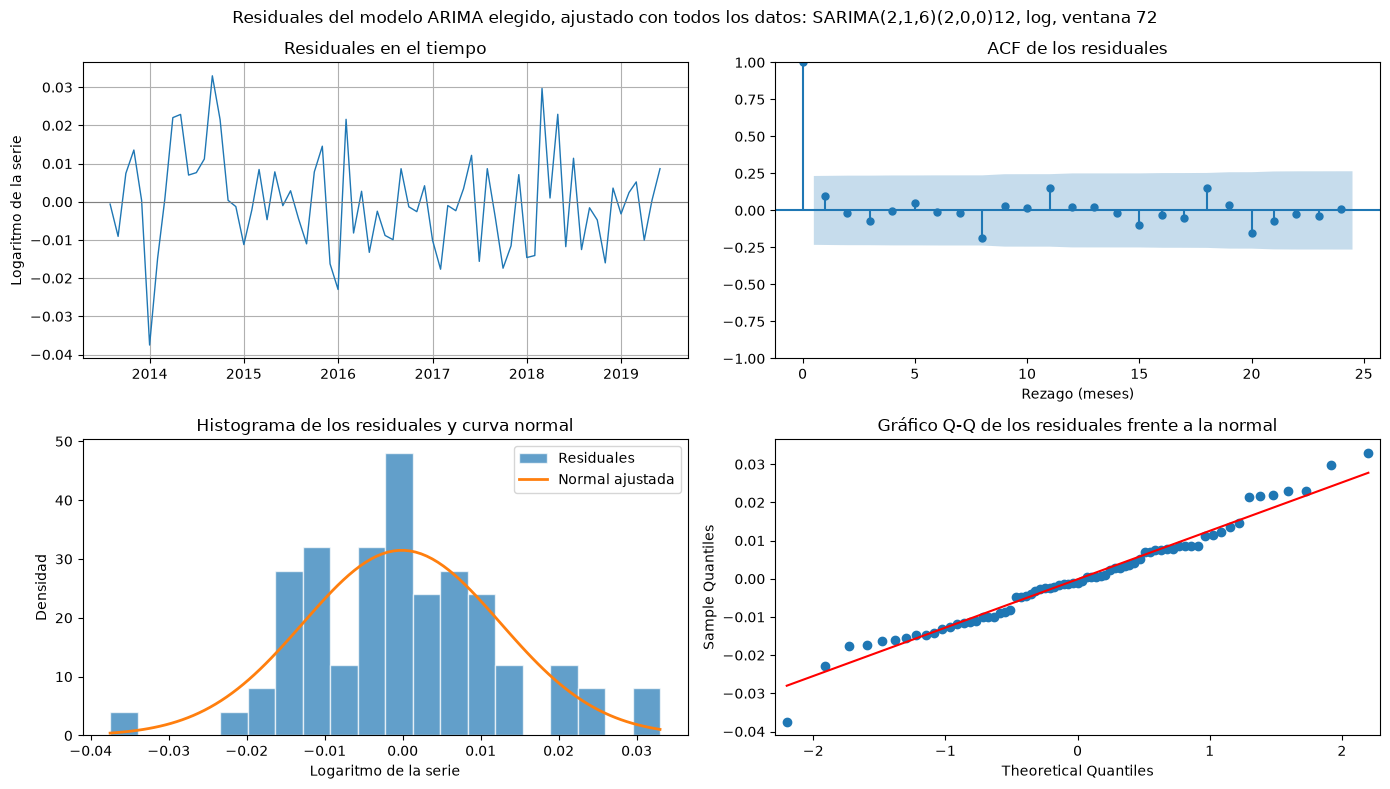

In [30]:
# --- Paso b: diagnóstico del modelo elegido ajustado con todos los datos (enero de 2001 a junio de 2019) ---
ajuste_sarima_completo = ajustar_sarima(ocupados, config_sarima)
print(ajuste_sarima_completo.summary())

residuales_sarima_completo = ajuste_sarima_completo.resid.iloc[ajuste_sarima_completo.loglikelihood_burn:]
supuestos_sarima_completo = pd.DataFrame({
    "Ajuste con el entrenamiento": diagnosticar_candidato(config_sarima),
    "Ajuste con todos los datos": evaluar_supuestos(residuales_sarima_completo, numero_coeficientes_arma(config_sarima)),
})
print(f"\nSupuestos de los residuales de {describir_sarima(config_sarima)}:")
print(supuestos_sarima_completo.map(lambda v: round(v, 3) if isinstance(v, float) else v).to_string())

graficar_diagnostico(residuales_sarima_completo,
                     f"Residuales del modelo ARIMA elegido, ajustado con todos los datos: {describir_sarima(config_sarima)}",
                     unidad="Logaritmo de la serie" if config_sarima["escala"] == "log" else "Miles de personas")

### Lectura del paso b

Con todos los datos, el modelo se estima con los últimos 72 meses de la serie, de julio de 2013 a junio de 2019. Sus residuales también cumplen los tres supuestos: la prueba de Ljung-Box rechaza en 2 de los 14 rezagos revisados, la prueba sobre los cuadrados no rechaza en ninguno, y las de Jarque-Bera y Shapiro-Wilk no rechazan la normalidad (p-valores de 0.632 y 0.352). La prueba ARCH-LM, que se reporta como complemento, tiene un p-valor de 0.043, en el límite del nivel de 0.05, pero la prueba de Ljung-Box sobre los cuadrados, que es la que aplica la regla, no rechaza en ningún rezago. En la gráfica «Residuales del modelo ARIMA elegido, ajustado con todos los datos: SARIMA(2,1,6)(2,0,0)12, log, ventana 72», todas las autocorrelaciones quedan dentro de la banda, y el gráfico Q-Q sigue la recta salvo por un residual de cerca de -3.7 % a inicios de 2014.

El `summary` del ajuste muestra, además, una característica que no aparece en las pruebas de los residuales. Los dos coeficientes autorregresivos estacionales son significativos ($\Phi_1 = 0.45$ y $\Phi_2 = 0.40$), pero ninguno de los 8 coeficientes no estacionales lo es, y sus errores estándar son muy grandes: por ejemplo, $\phi_1 = 0.21$ con un error estándar de 2.72 y $\theta_1 = -0.96$ con uno de 2.73. Esto indica que la parte autorregresiva y la de media móvil no estacionales casi se cancelan entre sí: con 72 observaciones, el modelo tiene más coeficientes no estacionales de los que los datos permiten identificar por separado. El pronóstico depende de la dinámica conjunta del modelo, que sí está bien estimada, de modo que esto no invalida el pronóstico, pero los coeficientes no estacionales no se pueden interpretar de forma individual. Es coherente con lo observado en la búsqueda, donde agregar órdenes de media móvil redujo el error en solo 1 a 2 % por etapa. El candidato 4, un $\text{SARIMA}(0,1,5)(2,0,0)_{12}$ con la misma ventana y 3 coeficientes menos, también cumple los supuestos, con un RMSE de 120.11 mil; la regla fijada elige el primero que los cumple, y esta alternativa más simple queda como referencia.

Con este diagnóstico, el modelo de la familia ARIMA cumple los supuestos tanto con el entrenamiento como con todos los datos, de modo que, si resulta elegido, sus residuales no muestran información que el modelo haya dejado sin usar.

## 9. Comparación en la muestra de prueba y elección del modelo

En esta sección se comparan, en la muestra de prueba, los modelos elegidos de cada familia: el promedio móvil, el Holt-Winters y la regresión de la sección 5, los dos modelos ARIMA de las secciones 7 y 8 (`auto_arima` y el SARIMA elegido con Optuna y los supuestos), la combinación del taller anterior y el naive estacional como referencia. Cada modelo se ajusta con todo el entrenamiento y pronostica de enero a junio de 2019, y se calculan el RMSE y el MAPE de esos 6 meses.

La regla de elección se fija antes de abrir la prueba: **se elige el modelo con menor RMSE de validación**, y la muestra de prueba se usa para confirmar la elección. Es el mismo criterio del taller anterior, y tiene dos razones. Primero, el RMSE de prueba se calcula con solo 6 meses de un único semestre, de modo que la posición de cada modelo puede depender de unos pocos meses, mientras que la validación promedia 6 semestres. Segundo, si la prueba se usara para elegir, dejaría de medir el error esperado del modelo elegido y su RMSE sería optimista. La comparación de las posiciones en la validación y en la prueba permite ver si la elección se sostiene.

Además, se recalculan las métricas de prueba de los 25 modelos del taller anterior y se verifican contra las obtenidas en ese taller, y al final se muestra la tabla completa de todos los modelos registrados como referencia.

Verificación: los 25 modelos del taller anterior reproducen su RMSE y su MAPE de prueba.

Modelos elegidos de cada familia: error de validación (6 cortes) y de prueba (2019-01 a 2019-06), en miles:
                                                                   Familia  RMSE validación  MAPE validación (%)  RMSE prueba  MAPE prueba (%)  Posición validación  Posición prueba
Holt-Winters con Optuna                            Suavización exponencial           103.63                 0.85        78.90             0.69                    1                5
Combinación ANA + regresión                                    Combinación           116.47                 0.92        62.72             0.52                    2                2
Regresión con grilla completa                                    Regresión           117.29                 0.93        77.93             0.61                    3                4
SARIMA(2,1,6)(2,0,0)12 con Optuna                                    ARIMA    

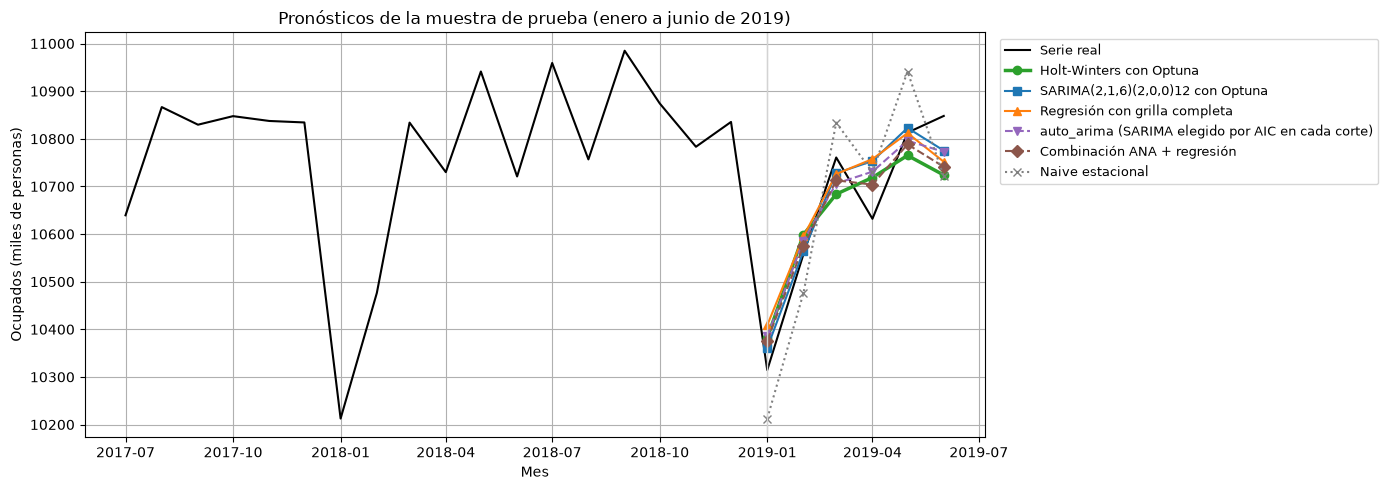

Valores reales, pronósticos y errores (real - pronóstico, miles de personas):
               Real  Holt-Winters con Optuna  Combinación ANA + regresión  Regresión con grilla completa  Error Holt-Winters con Optuna  Error Combinación ANA + regresión  Error Regresión con grilla completa
mes                                                                                                                                                                                                            
2019-01-01  10314.4                  10381.8                      10376.4                        10408.6                          -67.4                              -62.0                                -94.2
2019-02-01  10557.9                  10598.9                      10575.2                        10595.1                          -40.9                              -17.3                                -37.1
2019-03-01  10760.8                  10683.8                      10712.8                 

In [31]:
# --- Sección 9: comparación en la muestra de prueba ---
# Cada modelo registrado se ajusta con todo el entrenamiento y pronostica enero a junio de 2019
pronosticos_prueba = pd.DataFrame({nombre: np.asarray(funcion(train, horizonte), dtype=float)
                                   for nombre, funcion in funciones_pronostico.items()}, index=test.index)
metricas_prueba = pd.DataFrame({nombre: calcular_metricas(test, pronosticos_prueba[nombre])
                                for nombre in pronosticos_prueba}).T

# Verificación: los 25 modelos del taller anterior reproducen su RMSE y su MAPE de prueba
PRUEBA_TALLER_ANTERIOR = pd.DataFrame.from_dict({
    "Naive": (256.90, 1.77), "Naive estacional": (103.75, 0.95),
    "MA k=2": (242.83, 1.65), "MA k=3": (250.37, 1.70), "MA k=4": (270.62, 1.85), "MA k=6": (272.84, 1.90),
    "MA k=12": (225.31, 1.60),
    "SES (ANN)": (253.64, 1.74), "Holt (AAN)": (296.16, 2.38), "Holt amort. (AAdN)": (257.63, 1.78),
    "HW adit. sin tend. (ANA)": (108.16, 0.83), "HW adit. (AAA)": (74.38, 0.54), "HW adit. amort. (AAdA)": (66.32, 0.49),
    "HW mult. sin tend. (MNM)": (129.60, 0.95), "HW mult. (MAM)": (61.99, 0.53), "HW mult. amort. (MAdM)": (125.93, 0.92),
    "Tend. cúbica": (238.72, 1.65), "Tend. lineal + dummies": (614.22, 5.74), "Tend. cúbica + dummies": (104.61, 0.91),
    "Tend. grado 5 + dummies": (116.00, 0.89), "Tend. cuadrática + dummies, ventana 36": (73.29, 0.54),
    "Tend. lineal + Fourier K=5, ventana 24": (67.68, 0.53), "Log: Tend. lineal + dummies, ventana 24": (63.72, 0.47),
    "Tend. lineal + dummies, ventana 24": (65.20, 0.49), "Combinación ANA + regresión": (62.72, 0.52),
}, orient="index", columns=["rmse", "mape"])
diferencias_prueba = (metricas_prueba.loc[PRUEBA_TALLER_ANTERIOR.index].round(2) - PRUEBA_TALLER_ANTERIOR).abs()
assert (diferencias_prueba <= 0.01).all().all(), f"No coinciden con el taller anterior:\n{diferencias_prueba}"
print("Verificación: los 25 modelos del taller anterior reproducen su RMSE y su MAPE de prueba.\n")


def tabla_comparacion(nombres):
    """Error de validación y de prueba de los modelos indicados, con su posición en cada uno."""
    tabla = pd.DataFrame({
        "Familia": pd.Series(familias)[nombres],
        "RMSE validación": [validacion[nombre]["rmse"].mean() for nombre in nombres],
        "MAPE validación (%)": [validacion[nombre]["mape"].mean() for nombre in nombres],
        "RMSE prueba": metricas_prueba.loc[nombres, "rmse"].to_numpy(),
        "MAPE prueba (%)": metricas_prueba.loc[nombres, "mape"].to_numpy(),
    }, index=nombres)
    tabla["Posición validación"] = tabla["RMSE validación"].rank().astype(int)
    tabla["Posición prueba"] = tabla["RMSE prueba"].rank().astype(int)
    return tabla.sort_values("RMSE validación")


# Modelo elegido de cada familia y referencias. Regla fijada antes de abrir la prueba: se elige el de
# menor RMSE de validación, y la prueba se usa para confirmar la elección
modelos_elegidos = ["Naive estacional", nombre_ma_grilla, nombre_combinacion, nombre_hw_optuna,
                    nombre_regresion_grilla, nombre_auto_arima, nombre_sarima]
comparacion_final = tabla_comparacion(modelos_elegidos)
modelo_elegido_parte_1 = comparacion_final.drop(index="Naive estacional")["RMSE validación"].idxmin()
print("Modelos elegidos de cada familia: error de validación (6 cortes) y de prueba (2019-01 a 2019-06), en miles:")
print(comparacion_final.round(2).to_string())
print(f"\nModelo elegido por la regla (menor RMSE de validación): {modelo_elegido_parte_1}")

# Todos los modelos registrados, como referencia
print("\nTodos los modelos registrados, en orden de RMSE de validación:")
print(tabla_comparacion(list(funciones_pronostico)).round(2).to_string())

# Pronósticos de la prueba de los modelos elegidos de cada familia
estilos = {nombre_hw_optuna: dict(color="C2", linewidth=2.5, marker="o"),
           nombre_sarima: dict(color="C0", marker="s"), nombre_regresion_grilla: dict(color="C1", marker="^"),
           nombre_auto_arima: dict(color="C4", linestyle="--", marker="v"),
           nombre_combinacion: dict(color="C5", linestyle="--", marker="D"),
           "Naive estacional": dict(color="gray", linestyle=":", marker="x")}
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(ocupados.loc["2017-07":], color="black", linewidth=1.5, label="Serie real")
for nombre, estilo in estilos.items():
    ax.plot(pronosticos_prueba[nombre], label=nombre, **estilo)
ax.axvline(test.index[0], color="lightgray", linewidth=1)
ax.set_title("Pronósticos de la muestra de prueba (enero a junio de 2019)")
ax.set_xlabel("Mes")
ax.set_ylabel("Ocupados (miles de personas)")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=9)   # fuera del área de la serie
ax.grid()
plt.tight_layout()
plt.show()

# Valores reales, pronósticos y errores de los tres mejores modelos de la validación
mejores_validacion = comparacion_final.drop(index="Naive estacional").index[:3]
tabla_meses = pd.concat([test.rename("Real"), pronosticos_prueba[mejores_validacion]], axis=1)
for nombre in mejores_validacion:
    tabla_meses[f"Error {nombre}"] = tabla_meses["Real"] - tabla_meses[nombre]
print("Valores reales, pronósticos y errores (real - pronóstico, miles de personas):")
print(tabla_meses.round(1).to_string())

### Lectura de la comparación en la muestra de prueba

Los 25 modelos del taller anterior reproducen sus métricas de prueba, de modo que la comparación con ellos es directa.

| Modelo | Familia | RMSE validación | MAPE validación (%) | RMSE prueba | MAPE prueba (%) | Posición validación | Posición prueba |
|---|---|---|---|---|---|---|---|
| **Holt-Winters con Optuna** | Suavización exponencial | **103.63** | **0.85** | 78.90 | 0.69 | 1 | 5 |
| Combinación ANA + regresión | Combinación (taller anterior) | 116.47 | 0.92 | 62.72 | 0.52 | 2 | 2 |
| Regresión con grilla completa | Regresión | 117.29 | 0.93 | 77.93 | 0.61 | 3 | 4 |
| SARIMA(2,1,6)(2,0,0)12 con Optuna | ARIMA | 119.09 | 0.89 | **62.46** | **0.45** | 4 | 1 |
| Naive estacional | Referencia | 133.36 | 1.05 | 103.75 | 0.95 | 5 | 6 |
| `auto_arima` | ARIMA | 141.64 | 1.19 | 64.04 | 0.54 | 6 | 3 |
| MA k=25 | Promedio móvil | 171.51 | 1.29 | 202.92 | 1.39 | 7 | 7 |

*RMSE en miles de personas. La validación promedia los 6 cortes de 2016 a 2018; la prueba corresponde a enero a junio de 2019.*

Según la regla fijada antes de abrir la prueba, se elige el **Holt-Winters con Optuna**, el modelo con menor RMSE de validación. En la prueba, su RMSE es de 78.90 mil personas y su MAPE de 0.69 %: mejora al naive estacional (103.75 mil) y al Holt-Winters ANA del taller anterior (108.16 mil), pero queda en el quinto lugar entre los modelos de la tabla. Los modelos con menor error de prueba son el SARIMA elegido en la sección 8 (62.46 mil), la combinación del taller anterior (62.72 mil) y `auto_arima` (64.04 mil).

La tabla de valores reales y pronósticos muestra de dónde viene la diferencia. El Holt-Winters sobreestima enero y abril, en 67.4 y 86.7 mil, y subestima junio en 124.1 mil. En la gráfica «Pronósticos de la muestra de prueba (enero a junio de 2019)», su pronóstico se aplana desde marzo alrededor de 10,700 a 10,770 mil, mientras que la serie real termina el semestre en 10,848 mil. Su valor de $\alpha$, bajo (0.185), hace que el nivel se actualice despacio: en la validación esa lentitud evitó trasladar meses atípicos al pronóstico, pero cuando el nivel sube, como en el primer semestre de 2019, el modelo tarda en seguirlo.

Las posiciones en la validación y en la prueba no coinciden. `auto_arima`, el peor modelo ARIMA en la validación, es el tercero en la prueba; en la tabla completa, el Holt-Winters multiplicativo (MAM), en la posición 18 de la validación, vuelve a tener el menor error de prueba (61.99 mil), como en el taller anterior. Con solo 6 meses de un único semestre, las diferencias entre los mejores modelos de la prueba, de 62 a 79 mil personas, equivalen al error de uno o dos meses, y la posición de cada modelo puede cambiar con un mes atípico. La validación, en cambio, promedia 6 semestres. Por eso se mantiene la elección del Holt-Winters con Optuna; si se hubiera elegido el SARIMA por su error de prueba, ese error de 62.46 mil dejaría de ser una medida honesta de su desempeño. El desacuerdo entre las dos evaluaciones muestra el límite de una partición fija con un solo semestre de prueba, y es el punto de partida de la Parte 2, que evalúa todos los modelos en muchos orígenes.

## 10. Pronóstico de la Parte 1

El modelo elegido, el Holt-Winters aditivo sin tendencia con parámetros de suavización elegidos por Optuna, se ajusta con todos los datos disponibles, hasta junio de 2019, y pronostica de julio a diciembre de 2019. Se conservan su estructura, su ventana de 144 meses (de julio de 2007 a junio de 2019) y sus parámetros de suavización, y los estados iniciales se vuelven a estimar con la serie completa. Como referencia, se incluyen los pronósticos de los dos modelos con menor error en la prueba, que se ajustan de la misma forma, para ver cuánto depende el pronóstico del modelo elegido, y los valores de los mismos meses de 2018. Los intervalos de predicción se construyen en la Parte 2, con los errores de pronóstico observados en todos los orígenes de evaluación.

Pronóstico de julio a diciembre de 2019 (miles de personas); modelo elegido: Holt-Winters con Optuna
            Mismo mes de 2018  Holt-Winters con Optuna  SARIMA(2,1,6)(2,0,0)12 con Optuna  Combinación ANA + regresión
2019-07-01            10959.2                  10815.7                            10823.2                      10860.7
2019-08-01            10756.8                  10778.1                            10816.7                      10854.6
2019-09-01            10984.9                  10866.7                            10918.9                      10932.0
2019-10-01            10874.3                  10959.7                            10889.7                      10963.8
2019-11-01            10783.3                  10945.4                            10833.1                      10943.7
2019-12-01            10835.4                  10816.8                            10855.6                      10909.2

Crecimiento frente al mismo mes de 2018 (%):
            Holt-Win

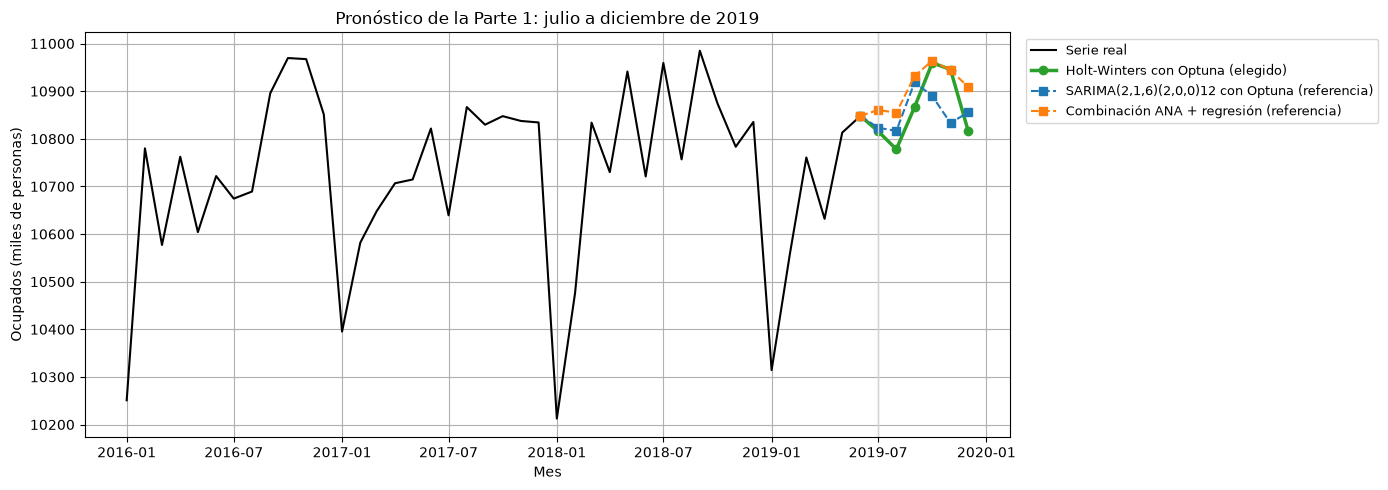

In [32]:
# --- Sección 10: pronóstico de julio a diciembre de 2019 ---
# El modelo elegido y, como referencia, los dos modelos con menor error de prueba se ajustan con todos los datos
modelos_pronostico_parte_1 = list(dict.fromkeys(
    [modelo_elegido_parte_1] + list(comparacion_final.drop(index="Naive estacional")["RMSE prueba"].nsmallest(2).index)))
fechas_futuras = fechas_siguientes(ocupados, horizonte)
pronostico_parte_1 = pd.DataFrame({nombre: np.asarray(funciones_pronostico[nombre](ocupados, horizonte), dtype=float)
                                   for nombre in modelos_pronostico_parte_1}, index=fechas_futuras)
pronostico_parte_1.insert(0, "Mismo mes de 2018", ocupados.loc["2018-07":"2018-12"].to_numpy())
print(f"Pronóstico de julio a diciembre de 2019 (miles de personas); modelo elegido: {modelo_elegido_parte_1}")
print(pronostico_parte_1.round(1).to_string())
print("\nCrecimiento frente al mismo mes de 2018 (%):")
print((100 * pronostico_parte_1[modelos_pronostico_parte_1].div(pronostico_parte_1["Mismo mes de 2018"], axis=0) - 100)
      .round(2).to_string())

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(ocupados.loc["2016":], color="black", linewidth=1.5, label="Serie real")
for numero, nombre in enumerate(modelos_pronostico_parte_1):
    estilo = dict(color="C2", linewidth=2.5, marker="o") if nombre == modelo_elegido_parte_1 else \
        dict(color=f"C{numero - 1}", linestyle="--", marker="s")
    etiqueta = f"{nombre} (elegido)" if nombre == modelo_elegido_parte_1 else f"{nombre} (referencia)"
    ax.plot(pd.concat([ocupados.iloc[-1:], pronostico_parte_1[nombre]]), label=etiqueta, **estilo)
ax.axvline(fechas_futuras[0], color="lightgray", linewidth=1)
ax.set_title("Pronóstico de la Parte 1: julio a diciembre de 2019")
ax.set_xlabel("Mes")
ax.set_ylabel("Ocupados (miles de personas)")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=9)
ax.grid()
plt.tight_layout()
plt.show()

### Lectura del pronóstico

| Mes | Mismo mes de 2018 | Holt-Winters con Optuna (elegido) | SARIMA(2,1,6)(2,0,0)12 | Combinación del taller anterior |
|---|---|---|---|---|
| Julio de 2019 | 10,959.2 | **10,815.7** | 10,823.2 | 10,860.7 |
| Agosto de 2019 | 10,756.8 | **10,778.1** | 10,816.7 | 10,854.6 |
| Septiembre de 2019 | 10,984.9 | **10,866.7** | 10,918.9 | 10,932.0 |
| Octubre de 2019 | 10,874.3 | **10,959.7** | 10,889.7 | 10,963.8 |
| Noviembre de 2019 | 10,783.3 | **10,945.4** | 10,833.1 | 10,943.7 |
| Diciembre de 2019 | 10,835.4 | **10,816.8** | 10,855.6 | 10,909.2 |

*Miles de personas.*

El Holt-Winters elegido pronostica entre 10,778 y 10,960 mil ocupados en la segunda mitad de 2019. Frente a los mismos meses de 2018, sus pronósticos van de -1.31 % en julio a +1.50 % en noviembre, con un promedio prácticamente nulo: el modelo proyecta el mismo nivel del año anterior, coherente con el estancamiento de la serie desde 2016 y con un modelo sin tendencia. En la gráfica «Pronóstico de la Parte 1: julio a diciembre de 2019», el pronóstico reproduce el patrón estacional del segundo semestre: baja en agosto, sube hasta un máximo en octubre y noviembre y cae en diciembre.

Los dos modelos de referencia pronostican niveles parecidos, pero con diferencias de hasta 112 mil personas en un mismo mes: el SARIMA ubica el máximo en septiembre y pronostica 112 mil menos que el Holt-Winters en noviembre, y la combinación del taller anterior queda por encima del Holt-Winters en todos los meses, salvo en octubre y noviembre. Estas diferencias son del mismo orden que el RMSE de validación de los modelos, de 100 a 120 mil personas, de modo que la elección del modelo pesa en el pronóstico tanto como su error esperado.

### Cierre de la Parte 1

Con la misma partición, el mismo horizonte y las mismas métricas del taller anterior, la Parte 1 agregó los modelos ARIMA y amplió la búsqueda de hiperparámetros de las demás familias. La identificación de la sección 6 sugirió una primera diferencia y una estacionalidad persistente. `auto_arima`, que elige el modelo por AIC, seleccionó un $\text{SARIMA}(2,1,0)(1,0,1)_{12}$ con constante, que en la validación no superó al naive estacional. La optimización bayesiana, que elige la especificación por el error de pronóstico a 6 meses, llegó a modelos con dos términos autorregresivos estacionales, sin diferencia estacional y en escala logarítmica, y el modelo elegido de la familia, un $\text{SARIMA}(2,1,6)(2,0,0)_{12}$ con ventana de 72 meses, cumple los supuestos de sus residuales tanto con el entrenamiento como con todos los datos.

Con la regla de elegir el menor RMSE de validación, el modelo elegido es el Holt-Winters aditivo sin tendencia, estimado con los últimos 144 meses y con parámetros de suavización elegidos por Optuna, con un RMSE de validación de 103.63 mil personas. En la muestra de prueba, su error (78.90 mil) mejora el del naive estacional y el del Holt-Winters del taller anterior, pero es mayor que el del SARIMA elegido, el de `auto_arima` y el de la combinación del taller anterior, que en la validación habían quedado por detrás. Con una sola partición, la evaluación depende de un único semestre de prueba y de 6 cortes de validación, y las dos no coinciden en qué modelo pronostica mejor. La Parte 2 evalúa todas las familias con muchos orígenes de pronóstico para dar una respuesta más robusta a esa pregunta.

# Parte 2 — Evaluación con origen móvil mensual

## 11. Protocolo de evaluación

En la Parte 2 no hay una partición fija. El origen del pronóstico avanza mes a mes y, en cada origen, todos los modelos se ajustan solo con la información disponible hasta ese momento y pronostican los 6 meses siguientes. El protocolo se define con las siguientes decisiones:

| Decisión | Elección | Justificación |
|---|---|---|
| Tipo de ventana | Expansiva (recursiva): en cada origen, los modelos disponen de toda la historia hasta el origen | Cada modelo conserva su propia ventana de estimación como hiperparámetro, de modo que un modelo que necesite solo los años recientes puede usarlos aunque el protocolo le ofrezca toda la historia. Una ventana móvil del protocolo, en cambio, limitaría a todos los modelos por igual y reduciría los datos para elegir los hiperparámetros |
| Tamaño inicial del entrenamiento | 120 meses, de enero de 2001 a diciembre de 2010 | Son 10 ciclos estacionales completos, suficientes para estimar modelos con términos estacionales de orden 2 y para validar los hiperparámetros con 6 cortes semestrales dentro de esa historia. Deja más de 8 años para evaluar, que incluyen tanto los años de crecimiento de la serie (2011 a 2015) como los de estancamiento (2016 a 2019) |
| Frecuencia de actualización | Los parámetros de cada modelo se vuelven a estimar en cada origen, es decir, cada mes. Los hiperparámetros se vuelven a elegir cada diciembre, con los datos disponibles hasta ese mes, y se usan en los orígenes de ese diciembre a noviembre del año siguiente. `auto_arima` elige su especificación en cada origen | Estimar los parámetros es rápido, de modo que se puede hacer en cada origen. Elegir los hiperparámetros requiere evaluar cientos de configuraciones, y repetirlo en cada uno de los 97 orígenes multiplicaría el cómputo sin un beneficio claro, porque la mejor configuración cambia lentamente. `auto_arima` es, por definición, un procedimiento de selección automática, y se aplica completo en cada origen |
| Periodo de evaluación | Orígenes de diciembre de 2010 a diciembre de 2018 (97 orígenes); se pronostican los meses de enero de 2011 a junio de 2019 | Es el periodo más largo en que cada origen tiene sus 6 meses siguientes observados, de modo que todos los modelos se evalúan con los mismos orígenes, los mismos horizontes y los mismos valores reales |

**Información disponible en cada origen.** Ningún modelo usa observaciones posteriores al origen para estimar sus parámetros, elegir sus hiperparámetros ni ser seleccionado. Esto incluye los espacios de búsqueda, que no pueden depender de lo aprendido con los datos de 2016 a 2018:

- Los hiperparámetros de cada año se eligen con la validación de la sección 3 aplicada a la serie disponible hasta cada diciembre: 6 cortes semestrales que terminan en ese diciembre.
- Las ventanas de estimación se limitan a la historia disponible en cada año. Una ventana mayor que la historia equivale a la ventana recursiva, de modo que no se evalúa por separado.
- La estacionalidad de periodo 12 de la suavización exponencial y de la regresión se justifica como conocimiento previo de una serie mensual de empleo, no por los resultados de la Parte 1.
- En el SARIMA con Optuna, los órdenes de diferenciación $d$ y $D$ entran en la búsqueda, en lugar de fijarse con las pruebas de la sección 6, que usaron todo el entrenamiento. `auto_arima` elige $d$ y $D$ con sus pruebas en cada origen.

**Fallos y métricas.** Si un modelo no se puede estimar en algún origen con la configuración elegida para ese año, se usa la siguiente mejor configuración del mismo año, para que todos los modelos se evalúen en los 97 orígenes. Las métricas se calculan por horizonte, con los 97 errores de cada horizonte de 1 a 6 meses, y en total, con los 582 errores de cada modelo: el RMSE total es la raíz del promedio de los 582 errores al cuadrado, y el MAPE total es el promedio de los 582 errores porcentuales absolutos. La regla de elección del modelo final se fija antes de ver los resultados: **se elige el modelo con menor RMSE total**.

Tipo de ventana del protocolo                            expansiva (recursiva)
Entrenamiento inicial                            2001-01 a 2010-12 (120 meses)
Orígenes de pronóstico               2010-12 a 2018-12 (97 orígenes mensuales)
Meses pronosticados                                          2011-01 a 2019-06
Horizontes                                1 a 6 meses (582 errores por modelo)
Reestimación de parámetros                            en cada origen (mensual)
Reoptimización de hiperparámetros     cada diciembre, de 2010 a 2018 (9 veces)


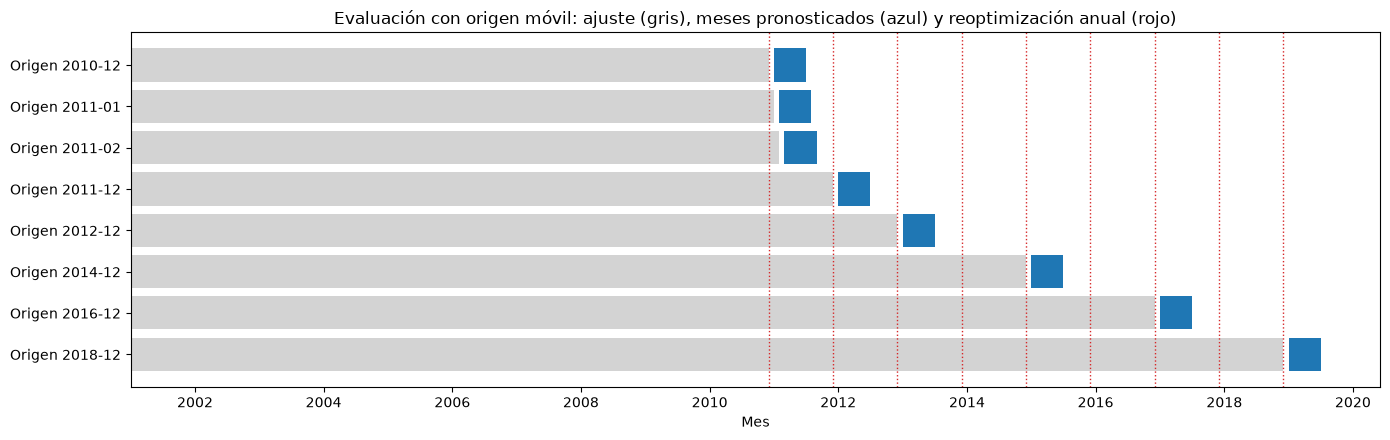

In [33]:
# --- Sección 11: protocolo de evaluación con origen móvil ---
class OrigenMovil:
    """Esquema de evaluación con origen móvil mensual y ventana expansiva.

    En cada origen, los modelos se ajustan con todos los meses hasta el origen (incluido) y pronostican los
    h meses siguientes. Solo se usan orígenes con los h meses siguientes observados, de modo que todos los
    modelos se evalúan con los mismos orígenes, horizontes y valores reales. Tiene la misma interfaz que
    TimeSeriesSplit (split, get_n_splits, gap y max_train_size), para usarlo con evaluar_validacion.
    """
    gap = 0                 # el primer mes pronosticado es el siguiente al origen
    max_train_size = None   # ventana expansiva: cada origen usa toda la historia disponible

    def __init__(self, primer_origen, ultimo_origen, h):
        self.primer_origen, self.ultimo_origen, self.h = pd.Timestamp(primer_origen), pd.Timestamp(ultimo_origen), h

    def split(self, serie):
        for origen in pd.date_range(self.primer_origen, self.ultimo_origen, freq="MS"):
            n_ajuste = serie.index.get_loc(origen) + 1
            assert n_ajuste + self.h <= len(serie), f"el origen {origen:%Y-%m} no tiene {self.h} meses observados"
            yield np.arange(n_ajuste), np.arange(n_ajuste, n_ajuste + self.h)

    def get_n_splits(self, serie=None):
        return len(pd.date_range(self.primer_origen, self.ultimo_origen, freq="MS"))


# Protocolo: 120 meses iniciales (enero de 2001 a diciembre de 2010) y orígenes mensuales hasta diciembre de
# 2018, el último con los 6 meses siguientes observados (enero a junio de 2019)
MESES_INICIALES = 120
primer_origen = ocupados.index[MESES_INICIALES - 1]
ultimo_origen = ocupados.index[-horizonte - 1]
origenes = OrigenMovil(primer_origen, ultimo_origen, horizonte)
cortes_origen = list(origenes.split(ocupados))
assert len(cortes_origen) == origenes.get_n_splits() == 97
assert all(len(idx_validacion) == horizonte for _, idx_validacion in cortes_origen)

# Reoptimización anual: los hiperparámetros elegidos con los datos hasta diciembre de cada año se usan en los
# orígenes de ese diciembre a noviembre del año siguiente
anios_reoptimizacion = list(range(primer_origen.year, ultimo_origen.year + 1))
anio_hiperparametros = {origen: origen.year if origen.month == 12 else origen.year - 1
                        for origen in pd.date_range(primer_origen, ultimo_origen, freq="MS")}

resumen_protocolo = pd.Series({
    "Tipo de ventana del protocolo": "expansiva (recursiva)",
    "Entrenamiento inicial": f"{ocupados.index[0]:%Y-%m} a {primer_origen:%Y-%m} ({MESES_INICIALES} meses)",
    "Orígenes de pronóstico": f"{primer_origen:%Y-%m} a {ultimo_origen:%Y-%m} ({len(cortes_origen)} orígenes mensuales)",
    "Meses pronosticados": f"{ocupados.index[MESES_INICIALES]:%Y-%m} a {ocupados.index[-1]:%Y-%m}",
    "Horizontes": f"1 a {horizonte} meses ({len(cortes_origen) * horizonte} errores por modelo)",
    "Reestimación de parámetros": "en cada origen (mensual)",
    "Reoptimización de hiperparámetros": f"cada diciembre, de {anios_reoptimizacion[0]} a {anios_reoptimizacion[-1]} "
                                          f"({len(anios_reoptimizacion)} veces)",
})
print(resumen_protocolo.to_string())

# Diagrama: meses de ajuste y meses pronosticados de algunos orígenes, y los diciembres de reoptimización
origenes_diagrama = [cortes_origen[i] for i in (0, 1, 2, 12, 24, 48, 72, 96)]
fig, ax = plt.subplots(figsize=(14, 4.5))
for fila, (idx_ajuste, idx_validacion) in enumerate(origenes_diagrama, start=1):
    ax.barh(fila, ocupados.index[idx_ajuste[-1]] - ocupados.index[0], left=ocupados.index[0], color="lightgray")
    ax.barh(fila, ocupados.index[idx_validacion[-1]] - ocupados.index[idx_validacion[0]] + pd.Timedelta(days=30),
            left=ocupados.index[idx_validacion[0]], color="C0")
for anio in anios_reoptimizacion:
    ax.axvline(pd.Timestamp(f"{anio}-12-01"), color="C3", linestyle=":", linewidth=1)
ax.set_yticks(range(1, len(origenes_diagrama) + 1))
ax.set_yticklabels([f"Origen {ocupados.index[idx_ajuste[-1]]:%Y-%m}" for idx_ajuste, _ in origenes_diagrama])
ax.invert_yaxis()
ax.set_title("Evaluación con origen móvil: ajuste (gris), meses pronosticados (azul) y reoptimización anual (rojo)")
ax.set_xlabel("Mes")
plt.tight_layout()
plt.show()

El protocolo tiene 97 orígenes, de diciembre de 2010 a diciembre de 2018, y produce 582 errores por modelo, 97 en cada horizonte. En la gráfica «Evaluación con origen móvil: ajuste (gris), meses pronosticados (azul) y reoptimización anual (rojo)», la historia disponible para ajustar crece de 120 meses en el primer origen a 216 en el último, y los meses pronosticados avanzan un mes en cada origen, de modo que cada mes de 2011 a 2019 se pronostica hasta 6 veces, con horizontes distintos. Las líneas rojas marcan los 9 diciembres en que se vuelven a elegir los hiperparámetros, de 2010 a 2018. El último origen pronostica de enero a junio de 2019, la muestra de prueba de la Parte 1; aquí esos meses no tienen un papel especial, porque cada pronóstico usa solo los datos anteriores a su origen.

## 12. Reoptimización anual de los hiperparámetros

Cada diciembre, de 2010 a 2018, los hiperparámetros de cada familia se vuelven a elegir con las mismas reglas de la Parte 1, aplicadas solo a la serie disponible hasta ese mes: la validación usa 6 cortes semestrales que terminan en ese diciembre. Así, cada año los modelos se eligen con la misma información que habría tenido quien pronosticara en ese momento.

| Familia | Elección de los hiperparámetros cada año |
|---|---|
| Promedio móvil | Búsqueda en grilla de la ventana $k$, de 2 a 48 meses |
| Holt-Winters | Optimización bayesiana con 300 intentos, con las estructuras y los rangos de suavización de la sección 5 |
| Regresión | Búsqueda en grilla completa, con tendencias de grado 0 a 5, y la regla de los supuestos sobre las 10 configuraciones con menor error |
| SARIMA | Optimización bayesiana con 200 intentos en un espacio genérico, con $d$ y $D$ entre 0 y 1, órdenes no estacionales hasta 3 y estacionales hasta 2, y la regla de los supuestos entre las configuraciones que superan al naive estacional de ese año |
| `auto_arima` | Sin reoptimización anual: elige su especificación en cada origen |
| Combinación | Promedio simple de los pronósticos del Holt-Winters y la regresión elegidos cada año, el equivalente de la combinación del taller anterior |

Los espacios de búsqueda no pueden depender de lo aprendido con los datos de 2016 a 2018. Por eso, las ventanas de estimación forman una grilla regular, cada 12 meses de 24 a 168 más la ventana recursiva (desde 48 meses en el SARIMA), recortada cada año a la historia del primer corte de validación. Los grados de la regresión y los órdenes del SARIMA son los rangos iniciales de la Parte 1, no los ampliados después, y en el SARIMA los órdenes de diferenciación también se eligen con los datos de cada año.

La regla de los supuestos usa los residuales del candidato ajustado con toda la serie del año. Un candidato no se puede verificar si ese ajuste no converge o si deja menos de 48 residuales, el doble del rezago máximo de la prueba de Ljung-Box; en ese caso se pasa al siguiente. Para cada familia se conserva la lista completa de configuraciones en orden de preferencia, de modo que, si la elegida falla en algún origen, se use la siguiente. La tabla final resume la configuración elegida cada año y su error de validación en ese año.

In [34]:
# --- Sección 12: reoptimización anual de los hiperparámetros ---
N_INTENTOS_HW_ANUAL = 300
N_INTENTOS_SARIMA_ANUAL = 200
N_CANDIDATOS_SUPUESTOS = 10   # candidatos de la regresión revisados con la regla de los supuestos
# Las pruebas de Ljung-Box usan los rezagos 1 a 24; con menos de 48 residuales (el doble del rezago máximo) la
# regla no se puede aplicar con confianza, y esos candidatos se tratan como no verificables
MIN_RESIDUALES_SUPUESTOS = 48
# Ventanas de estimación de la reoptimización anual: cada 12 meses, de 24 a 168, más la recursiva. Es una
# grilla regular, fijada sin mirar los resultados de la Parte 1; cada año se recorta a la historia disponible
VENTANAS_ANUALES = list(range(24, 180, 12)) + [None]
VENTANAS_SARIMA_ANUALES = [ventana for ventana in VENTANAS_ANUALES if ventana is None or ventana >= 48]


def datos_anio(anio):
    """Serie disponible hasta diciembre del año y sus 6 cortes semestrales de validación."""
    return ocupados.loc[:f"{anio}-12"], TimeSeriesSplit(n_splits=n_cortes, test_size=horizonte)


def ventanas_disponibles(ventanas, serie):
    """Ventanas menores que la historia del primer corte de validación; la recursiva (None) siempre se incluye."""
    historia_minima = len(serie) - n_cortes * horizonte
    return [ventana for ventana in ventanas if ventana is None or ventana < historia_minima]


def configs_estudio(estudio):
    """Configuraciones completas de un estudio de Optuna, sin repetidas, en orden de RMSE promedio."""
    completos = sorted((t for t in estudio.trials if t.state == optuna.trial.TrialState.COMPLETE),
                       key=lambda t: t.value)
    vistas, ordenadas = set(), []
    for intento in completos:
        clave = tuple(sorted(intento.user_attrs["config"].items()))
        if clave not in vistas:
            vistas.add(clave)
            ordenadas.append((intento.user_attrs["config"], intento.value))
    return ordenadas


def ordenar_por_supuestos(configs, residuales, coeficientes):
    """Pone primero la primera configuración, en orden de RMSE, cuyos residuales cumplen los tres supuestos
    (regla del taller anterior); si ninguna los cumple, conserva el orden. Devuelve (configs, cumple).

    Una configuración no se puede verificar, y se omite, si su ajuste con toda la serie del año no converge
    o si deja menos de MIN_RESIDUALES_SUPUESTOS residuales.
    """
    for posicion, (config, _) in enumerate(configs):
        try:
            errores = residuales(config)
        except Exception:   # por ejemplo, la estimación del SARIMA no converge con la serie completa del año
            continue
        if len(errores) < MIN_RESIDUALES_SUPUESTOS:
            continue
        if evaluar_supuestos(errores, coeficientes(config))["Cumple los supuestos"]:
            return [configs[posicion]] + configs[:posicion] + configs[posicion + 1:], True
    return configs, False


def espacio_sarima_anual(ventanas):
    """Espacio genérico de ARIMA y SARIMA para la reoptimización anual: d y D entran en la búsqueda, y los
    órdenes llegan a 3 (no estacionales) y 2 (estacionales), sin depender de la identificación de la sección 6."""
    def sugerir(trial):
        config = {"p": trial.suggest_int("p", 0, 3), "d": trial.suggest_int("d", 0, 1), "q": trial.suggest_int("q", 0, 3),
                  "P": trial.suggest_int("P", 0, 2), "D": trial.suggest_int("D", 0, 1), "Q": trial.suggest_int("Q", 0, 2),
                  "escala": trial.suggest_categorical("escala", ["original", "log"]),
                  "ventana": trial.suggest_categorical("ventana", ventanas)}
        # Término determinístico solo si d + D < 2 (con d + D = 2 implicaría una tendencia cuadrática)
        config["tendencia"] = trial.suggest_categorical("tendencia", ["n", "c"]) if config["d"] + config["D"] < 2 else "n"
        return config

    return sugerir


def reoptimizar_anio(anio):
    """Elige los hiperparámetros de cada familia con los datos hasta diciembre del año indicado.

    Devuelve, por familia, la lista de configuraciones en orden de preferencia (la primera es la elegida y las
    siguientes son el respaldo si la elegida falla en algún origen), y si la elegida cumple los supuestos.
    """
    serie, cv = datos_anio(anio)
    ventanas = ventanas_disponibles(VENTANAS_ANUALES, serie)
    rmse_naive_anio = evaluar_validacion(crear_pronostico_naive_estacional({"m": 12}), serie=serie, cv=cv)["rmse"].mean()
    resultado = {}

    # Promedio móvil: grilla de la ventana k
    tabla_ma, _ = evaluar_grilla(crear_pronostico_ma, [{"k": k} for k in VENTANAS_K], serie=serie, cv=cv)
    resultado["Promedio móvil"] = ([({"k": int(k)}, rmse) for k, rmse in tabla_ma[["k", "RMSE promedio"]].to_numpy()], None)

    # Regresión: grilla completa (tendencias de grado 0 a 5) y regla de los supuestos con los residuales en los
    # meses comunes a los candidatos verificables (los que tienen al menos MIN_RESIDUALES_SUPUESTOS residuales)
    configs_reg = [{"tendencia": tendencia, "estacionalidad": estacionalidad, "K": K, "ventana": ventana, "escala": escala}
                   for tendencia in TENDENCIAS_REGRESION
                   for estacionalidad, K in ESTACIONALIDADES_REGRESION
                   for ventana in ventanas
                   for escala in ESCALAS_REGRESION]
    with warnings.catch_warnings():
        warnings.filterwarnings("ignore", message="The design matrix is rank-deficient")
        tabla_reg, _ = evaluar_grilla(crear_pronostico_regresion, configs_reg, serie=serie, cv=cv)
    ordenadas_reg = [(configs_reg[numero], rmse) for numero, rmse in tabla_reg["RMSE promedio"].items()]
    candidatos_reg = ordenadas_reg[:N_CANDIDATOS_SUPUESTOS]
    largos = [len(ajustar_regresion(serie, c).resid) for c, _ in candidatos_reg]
    meses = min((largo for largo in largos if largo >= MIN_RESIDUALES_SUPUESTOS), default=MIN_RESIDUALES_SUPUESTOS)
    elegidas_reg, cumple_reg = ordenar_por_supuestos(
        candidatos_reg, lambda c: ajustar_regresion(serie, c).resid.iloc[-meses:], lambda c: 0)
    resultado["Regresión"] = (elegidas_reg + ordenadas_reg[N_CANDIDATOS_SUPUESTOS:], cumple_reg)

    # Holt-Winters: optimización bayesiana con el espacio de la sección 5 y las ventanas del año
    estudio = optimizar(lambda trial: sugerir_configuracion_hw(trial, ventanas=ventanas), crear_pronostico_hw,
                        N_INTENTOS_HW_ANUAL, serie=serie, cv=cv, mostrar=False)
    resultado["Holt-Winters"] = (configs_estudio(estudio), None)

    # SARIMA: optimización bayesiana y regla de los supuestos entre los que superan al naive estacional
    estudio = optimizar(espacio_sarima_anual(ventanas_disponibles(VENTANAS_SARIMA_ANUALES, serie)),
                        crear_pronostico_sarima, N_INTENTOS_SARIMA_ANUAL, serie=serie, cv=cv, mostrar=False)
    ordenadas_sarima = configs_estudio(estudio)
    candidatos_s = [(c, rmse) for c, rmse in ordenadas_sarima if rmse < rmse_naive_anio] or ordenadas_sarima[:1]
    elegidas_s, cumple_s = ordenar_por_supuestos(candidatos_s, lambda c: residuales_sarima(c, serie),
                                                 numero_coeficientes_arma)
    resultado["SARIMA"] = (elegidas_s + [x for x in ordenadas_sarima if x not in elegidas_s], cumple_s)

    for familia, (configs, _) in resultado.items():
        assert configs, f"{anio}: ninguna configuración de {familia} se pudo evaluar en la validación"
    return resultado


inicio = pd.Timestamp.now()
hiperparametros_anuales = {}
for anio in anios_reoptimizacion:
    hiperparametros_anuales[anio] = reoptimizar_anio(anio)
    print(f"{anio}: listo ({(pd.Timestamp.now() - inicio).total_seconds() / 60:.1f} min acumulados)")


def describir_config(familia, config):
    """Descripción corta de la configuración elegida de una familia."""
    if familia == "Promedio móvil":
        return f"k = {config['k']}"
    if familia == "Regresión":
        return describir_regresion(config).removeprefix("Tend. ")
    if familia == "Holt-Winters":
        ventana = "recursiva" if config["ventana"] is None else f"ventana {config['ventana']}"
        return (f"{config['tendencia']}/{config['estacionalidad']}, {ventana}, "
                f"alpha {config['alpha']:.2f}, gamma {config['gamma_relativo'] * (1 - config['alpha']):.2f}")
    return describir_sarima(config)


# Hiperparámetros elegidos cada año (con su RMSE promedio de validación de ese año)
tabla_anual = pd.DataFrame({
    familia: {anio: f"{describir_config(familia, elegidas[familia][0][0][0])} ({elegidas[familia][0][0][1]:.1f})"
                    + ("" if elegidas[familia][1] is not False else " *")
              for anio, elegidas in hiperparametros_anuales.items()}
    for familia in ["Promedio móvil", "Holt-Winters", "Regresión", "SARIMA"]
})
tabla_anual.index.name = "Datos hasta diciembre de"
print("\nConfiguración elegida cada año (RMSE promedio de validación de ese año, en miles; * = ningún candidato "
      "cumple los supuestos o se puede verificar):")
print(tabla_anual.to_string())

2010: listo (0.1 min acumulados)
2011: listo (0.4 min acumulados)
2012: listo (0.5 min acumulados)
2013: listo (0.6 min acumulados)
2014: listo (0.8 min acumulados)


/var/folders/p4/gx9vbn9x3r155vcdnyljf8_m0000gn/T/ipykernel_36755/3062083742.py:68: RuntimeWarning: overflow encountered in exp


2015: listo (3.1 min acumulados)
2016: listo (5.1 min acumulados)
2017: listo (8.2 min acumulados)
2018: listo (11.6 min acumulados)

Configuración elegida cada año (RMSE promedio de validación de ese año, en miles; * = ningún candidato cumple los supuestos o se puede verificar):
                          Promedio móvil                                                            Holt-Winters                                       Regresión                                                            SARIMA
Datos hasta diciembre de                                                                                                                                                                                                          
2010                       k = 5 (206.5)      aditiva/multiplicativa, ventana 36, alpha 0.25, gamma 0.17 (117.8)       cubica + Fourier K=3, recursiva (117.7) *                    SARIMA(1,1,3)(2,0,2)12, log, recursiva (135.3)
2011                       k = 5 (261.

## 13. Evaluación de todos los modelos con origen móvil

En cada uno de los 97 orígenes, cada modelo se ajusta con la serie disponible hasta el origen, con la configuración elegida en el diciembre más reciente, y pronostica los 6 meses siguientes. Se evalúan siete modelos: el naive estacional como referencia, el promedio móvil, el Holt-Winters, la regresión, el SARIMA con Optuna, `auto_arima` y la combinación del Holt-Winters y la regresión. Las métricas totales se calculan con los 582 errores de cada modelo, y se reportan además el error medio, que indica si el modelo sobreestima (negativo) o subestima (positivo) la serie de forma sistemática, el número de orígenes en que cada modelo supera al naive estacional y el número de años en que fue necesario usar una configuración de respaldo.

In [35]:
# --- Sección 13: evaluación de todos los modelos con origen móvil ---
def origenes_del_anio(anio):
    """Orígenes que usan los hiperparámetros elegidos en diciembre del año: de ese diciembre a noviembre del
    año siguiente, dentro del periodo de evaluación."""
    primero = max(primer_origen, pd.Timestamp(f"{anio}-12-01"))
    ultimo = min(ultimo_origen, pd.Timestamp(f"{anio + 1}-11-01"))
    return OrigenMovil(primero, ultimo, horizonte)


def evaluar_con_origen_movil(crear_pronostico, configs_por_anio):
    """Pronósticos de una familia en los 97 orígenes, con la configuración elegida para cada año.

    configs_por_anio: {año: lista de configuraciones en orden de preferencia}. Si la primera falla en algún
    origen del año, se usa la siguiente, de modo que la familia se evalúa en todos los orígenes. Devuelve la
    tabla de evaluar_validacion con los pronósticos por horizonte y el número de años en que se usó un respaldo.
    """
    tablas, respaldos = [], 0
    for anio, configs in configs_por_anio.items():
        for posicion, config in enumerate(configs):
            try:
                tabla = evaluar_validacion(crear_pronostico(config), serie=ocupados, cv=origenes_del_anio(anio),
                                           identidad=identidad_cache(crear_pronostico, config), con_pronosticos=True,
                                           n_procesos=PROCESOS_POR_MODELO.get(crear_pronostico.__name__, 1))
                respaldos += posicion > 0
                break
            except ErrorDeAjuste:
                continue
        else:   # ninguna configuración del año se pudo ajustar en todos sus orígenes
            raise RuntimeError(f"{crear_pronostico.__name__}: ninguna configuración de {anio} se pudo ajustar")
        tablas.append(tabla)
    tabla = pd.concat(tablas)
    assert len(tabla) == len(cortes_origen), "la familia no se evaluó en todos los orígenes"
    return tabla, respaldos


configuraciones_por_familia = {familia: {anio: [config for config, _ in elegidas[familia][0]]
                                         for anio, elegidas in hiperparametros_anuales.items()}
                               for familia in ["Promedio móvil", "Holt-Winters", "Regresión", "SARIMA"]}
# auto_arima: el procedimiento de la Parte 1 (AIC); si falla en algún origen del año, el mismo procedimiento con BIC
configs_auto_arima = [CONFIG_AUTO_ARIMA, {**CONFIG_AUTO_ARIMA, "criterio": "bic"}]
modelos_origen = {
    "Naive estacional": (crear_pronostico_naive_estacional, {anio: [{"m": 12}] for anio in anios_reoptimizacion}),
    "Promedio móvil": (crear_pronostico_ma, configuraciones_por_familia["Promedio móvil"]),
    "Holt-Winters": (crear_pronostico_hw, configuraciones_por_familia["Holt-Winters"]),
    "Regresión": (crear_pronostico_regresion, configuraciones_por_familia["Regresión"]),
    "SARIMA con Optuna": (crear_pronostico_sarima, configuraciones_por_familia["SARIMA"]),
    "auto_arima": (crear_pronostico_auto_arima, {anio: configs_auto_arima for anio in anios_reoptimizacion}),
}
inicio = pd.Timestamp.now()
resultados_origen, respaldos_origen = {}, {}
for nombre, (crear_pronostico, configs_por_anio) in modelos_origen.items():
    resultados_origen[nombre], respaldos_origen[nombre] = evaluar_con_origen_movil(crear_pronostico, configs_por_anio)
print(f"Evaluación con origen móvil: {(pd.Timestamp.now() - inicio).total_seconds() / 60:.1f} min")

# Pronósticos (orígenes x horizontes) y valores reales de los mismos meses
columnas_horizonte = [f"pronostico_{paso}" for paso in range(1, horizonte + 1)]
pronosticos_origen = {nombre: tabla[columnas_horizonte].to_numpy() for nombre, tabla in resultados_origen.items()}
# Combinación del Holt-Winters y la regresión de cada año: promedio simple de sus pronósticos en cada origen
pronosticos_origen["Combinación Holt-Winters + regresión"] = (pronosticos_origen["Holt-Winters"]
                                                               + pronosticos_origen["Regresión"]) / 2
reales_origen = np.array([ocupados.iloc[idx_validacion].to_numpy() for _, idx_validacion in cortes_origen])
origenes_fechas = pd.DatetimeIndex([ocupados.index[idx_ajuste[-1]] for idx_ajuste, _ in cortes_origen])
errores_origen = {nombre: reales_origen - pronostico for nombre, pronostico in pronosticos_origen.items()}

# Verificación: el RMSE de cada origen calculado con los pronósticos guardados coincide con el de la evaluación,
# lo que confirma que las filas de cada tabla están alineadas con los orígenes
for nombre, tabla in resultados_origen.items():
    assert np.allclose(np.sqrt((errores_origen[nombre] ** 2).mean(axis=1)), tabla["rmse"])

# Métricas totales: RMSE con los 582 errores y MAPE con los 582 errores porcentuales absolutos
resumen_origen = pd.DataFrame({
    nombre: {"RMSE total": np.sqrt((errores ** 2).mean()),
             "MAPE total (%)": 100 * np.mean(np.abs(errores) / reales_origen),
             "Error medio": errores.mean(),
             "Orígenes mejores que el naive estacional": int((np.sqrt((errores ** 2).mean(axis=1)) < np.sqrt(
                 (errores_origen["Naive estacional"] ** 2).mean(axis=1))).sum()),
             "Años con configuración de respaldo": respaldos_origen.get(nombre, 0)}
    for nombre, errores in errores_origen.items()
}).T.sort_values("RMSE total")
columnas_conteo = ["Orígenes mejores que el naive estacional", "Años con configuración de respaldo"]
resumen_origen[columnas_conteo] = resumen_origen[columnas_conteo].astype(int)
print(f"\nMétricas totales en {len(cortes_origen)} orígenes y {len(cortes_origen) * horizonte} errores por modelo "
      f"(miles de personas; error medio = real - pronóstico):")
print(resumen_origen.round(2).to_string())

/Users/juan/Documents/Maestria/PrimerSemestre/AprendizajeAutomaticoIII/repos/ml3-time-series-forecasting/.venv/lib/python3.13/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Evaluación con origen móvil: 2.3 min

Métricas totales en 97 orígenes y 582 errores por modelo (miles de personas; error medio = real - pronóstico):
                                      RMSE total  MAPE total (%)  Error medio  Orígenes mejores que el naive estacional  Años con configuración de respaldo
auto_arima                                140.89            1.10       -22.71                                        77                                   0
SARIMA con Optuna                         158.73            1.24       -47.65                                        60                                   1
Holt-Winters                              162.13            1.20       -22.93                                        67                                   0
Combinación Holt-Winters + regresión      168.33            1.25       -24.75                                        68                                   0
Regresión                                 236.31            1.75       